<a href="https://colab.research.google.com/github/suulnnka/AetherTTS/blob/main/notebooks/AetherTTS_Colab_Phase1_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AetherTTS — Phase 1 流式分块深前瞻定型与闭环训练（`a8` 架构，Colab T4 + 自建 RTX 4090 双兼容）

本 Notebook 自动适配 **Google Colab（T4 / L4 / A100）** 与 **自建 Linux GPU 服务器（如 RTX 4090 / AutoDL，全部文件纯本地保存，零云盘依赖）**，聚焦已胜出的唯一主力路线 **`E3_chunk_attn_C4_L8`（5 层深双向分块前瞻 `ChunkLookaheadBackbone`）** 完成高质量端到端训练与评测：

1. **路线收敛（仅跑 `ChunkLookaheadBackbone`，归档保留对照代码）**：
   - 默认仅训练与评测 **`E3_chunk_attn_C4_L8`**（提交块 `C=4` + 右前瞻 `L=8` + 有界窗口 `W=48`，丢弃前瞻状态保证零前瞻膨胀，原生支持 Phase 2 流式前端暂定纠错）；`E0/E1/E2/E4` 类保留在代码库中供归档查验或 `--models` 显式调用。
2. **`a5` 六大核心升级（彻底解决首轮实验“电音 / 发糊 / 训推错位 / 长流式漂移”瓶颈）**：
   - **声学 → 声码器 GTA 闭环精调**：调整管线为「**先训 `E3` 声学模型 → 导出精确 Viterbi 帧对齐的 GTA 预测 Mel → 再训声码器（Stage 2 混入 50% GTA Mel 闭环微调）**」，彻底消除声学过平滑谱与声码器真声谱之间的分布失配。
   - **帧率谐波源因果声码器 `CausalVocosLite`（`a5`）+ 判别器修复**：
     - 修复 `SpecDisc` STFT 未转置导致频率感受野仅 11 bin（129 Hz，看不见女声相邻谐波）的致命 Bug，改为 `(B, 1, T, F)` 幂律压缩幅度谱（频率感受野扩展至 73 bin，覆盖 4–14 条谐波），补齐 `PeriodDisc(11)` 完整质数周期 `[2, 3, 5, 7, 11]`；
     - 内置 `mel_mean / mel_std` 输入归一化（消除右前瞻补 `0.0` 在原始 log-mel 下造成的 +16 能量脉冲）与 **`CausalHarmonicSource` 帧率包裹相位谐波振荡器**（`float64` 累积基频相位 $\phi_0 \bmod 1$ + 12 阶谐波正余弦注入），零采样率开销根治稳态元音 STFT 相位漂移电音。
   - **完备中英音系与韵律前端（`v3` 缓存）**：区分齐齿呼与舌尖前/后元音（`i / ii / iii`），补齐 `y/w` 零声母与 `ian/iou/uei/uen` 省写还原（覆盖全部 20,901 个 CJK 汉字零 `<unk>`），显式建模儿化韵尾 `zh_er_coda`、“一/不/叠字”变调与双音节韵律步三声变调；按字符精确对齐标贝儿化句标点与 `#1–#3` 韵律边界，用音素级 `boundary_ids` 替代抢占连读辅音帧的词间 `<sp>`。
   - **浊音感知 `F0 + UV` 联合建模 & 2D 共振峰结构损失 & 时长梯度隔离**：显式预测 `(f0, uv)`，仅在浊音帧监督 F0 并将清辅音帧基频嵌入置零；补充频率轴共振峰差分 + 时间轴瞬态差分结构损失；对 `dur_predictor` 输入做 `0.1x` Stop-Gradient 缩放并平滑软硬对齐退火。
   - **真 $O(1)$ 无限长流式相对 RoPE & 动态首包低延迟声码器调度**：KV Cache 改为存储未旋转 K 并在固定 `[0 .. W+M)` 局部窗口施加相对 RoPE，多句连续数小时不重置状态亦无位置外推或表重分配；流式声码器首包攒够 `6` 帧（64 ms）即刻出声，稳态切回 `16` 帧保吞吐。
   - **严谨数据切分与全系统指标**：有声段门控 RMS 响度归一化、中值滤波去倍频跳变 F0、全档位固定 100 句独立验证集、剥离 `aligner` 的端到端（声学+声码器）INT8 体积与误差校验、无截断失真的综合评分。

> **自建 RTX 4090 推荐命令行用法**：
> ```bash
> python scripts/aethertts_phase1.py --selftest --skip-pip
> python scripts/aethertts_phase1.py --profile full_quality --dataset bznsyp --batch-size 64 --root ./aethertts_exp --skip-pip
> ```

## 1. 环境自动识别（Colab / 自建 4090 本地 / Kaggle）与全局配置（默认锁定 `E3_chunk_attn_C4_L8`）

In [1]:
import os
import sys
import json
import math
import time
import signal
import shutil
import random
import tarfile
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import torch

# ==============================================================================
# 1) 环境自动检测（支持环境变量覆盖，方便自建 4090 CLI 脚本调用）
# ==============================================================================
ENV_MODE = os.environ.get("AETHER_ENV_MODE", "auto").lower()  # "auto" | "colab" | "local" | "kaggle"
if ENV_MODE == "auto":
    if "google.colab" in sys.modules:
        ENV_MODE = "colab"
    elif Path("/kaggle/working").exists():
        ENV_MODE = "kaggle"
    else:
        ENV_MODE = "local"

IS_COLAB = (ENV_MODE == "colab")
IS_LOCAL = (ENV_MODE == "local")
IS_KAGGLE = (ENV_MODE == "kaggle")

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    STORAGE_ROOT = Path(os.environ.get("AETHER_ROOT", "/content/drive/MyDrive/AetherTTS_Exp"))
    LOCAL_WORK = Path("/content/aethertts_work")
elif IS_KAGGLE:
    STORAGE_ROOT = Path(os.environ.get("AETHER_ROOT", "/kaggle/working/AetherTTS_Exp"))
    LOCAL_WORK = Path("/kaggle/temp/aethertts_work")
else:
    # 自建 4090 / 本地 Linux：所有文件统一留在本地，不做任何云盘挂载或重复拷贝！
    STORAGE_ROOT = Path(os.environ.get("AETHER_ROOT", "./aethertts_exp")).expanduser().resolve()
    LOCAL_WORK = STORAGE_ROOT

DRIVE_ROOT = STORAGE_ROOT

for p in [
    STORAGE_ROOT / "datasets" / "raw",
    STORAGE_ROOT / "vocoder",
    STORAGE_ROOT / "runs",
    STORAGE_ROOT / "eval_samples",
    STORAGE_ROOT / "reports",
    LOCAL_WORK / "data",
    LOCAL_WORK / "cache",
    LOCAL_WORK / "vocoder",
    LOCAL_WORK / "runs",
    LOCAL_WORK / "eval_samples",
    LOCAL_WORK / "reports",
]:
    p.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

# ==============================================================================
# 2) 用户核心配置区（默认唯一主力路线：E3_chunk_attn_C4_L8；旧对照代码保留但不默认运行）
# ==============================================================================
EXPERIMENT_PROFILE = os.environ.get("AETHER_PROFILE", "standard_phase1")
DATASET_SOURCE = os.environ.get("AETHER_DATASET", "bznsyp")
VOCODER_MODE = os.environ.get("AETHER_VOCODER", "both")

# 全部已实现的架构注册表（保留 E0/E1/E2/E4 代码供归档对照或 --models 显式指定）
ALL_EXPERIMENTS = [
    ("E0_offline_bitransformer", "offline_transformer", 0),  # [归档保留] 离线全双向 Transformer
    ("E1_conv_unigru_L0",        "conv_gru",            0),  # [归档保留] 0 前瞻严格因果基线
    ("E1_conv_unigru_L8",        "conv_gru",            8),  # [归档保留] 8 音素浅前瞻 + ConvNeXt + Uni-GRU
    ("E2_swa_L8",                "swa",                 8),  # [归档保留] 8 音素浅前瞻 + 滑窗 SWA (W=48)
    ("E3_chunk_attn_C4_L8",      "chunk_attn",          8),  # ★ 唯一默认主力：5 层深双向分块前瞻 (C=4, L=8, W=48)
    ("E4_gated_deltanet_L8",     "gdn",                 8),  # [归档保留] 8 音素浅前瞻 + 标准门控 DeltaNet
]
DEFAULT_EXPERIMENTS = [
    ("E3_chunk_attn_C4_L8", "chunk_attn", 8),
]

_filter_models = os.environ.get("AETHER_MODELS", "").strip()
if _filter_models.lower() == "all":
    EXPERIMENTS = list(ALL_EXPERIMENTS)
elif _filter_models:
    _wanted = {m.strip() for m in _filter_models.split(",") if m.strip()}
    EXPERIMENTS = [e for e in ALL_EXPERIMENTS if e[0] in _wanted]
    assert EXPERIMENTS, f"AETHER_MODELS={_filter_models!r} 未匹配任何已知模型: {[x[0] for x in ALL_EXPERIMENTS]}"
else:
    EXPERIMENTS = list(DEFAULT_EXPERIMENTS)

# 架构版本号 a8（复用 v4 特征缓存，零重抽）：在保留 a7 声码器谐波梯度隔离与 T4 原生 FP16 修复的基础上，根治 a7 实机暴露的稀疏锚点对齐坍缩（dur1=72%~74%）——
# 1) Aligner + Forward-Sum 对齐 NVIDIA FastPitch/RAD-TTS/NeMo 规范：先仅对内容相似度做 log_softmax 再在外部叠加 Beta-Binomial 先验，
#    forward_sum_loss 左侧拼接 blank_logprob=-1.0 并做二次 log_softmax（消除禁用 blank=-1e4 导致的稀疏锚点捷径），loss_bin 改用归一化 log_softmax(attn_logprob)；
# 2) 补齐训练进度条与 history.json 的 align/bin 指标记录，升级 --selftest 为能量地形 + 零声学偏置自愈硬门禁。
ARCH_TAG = "a8"
DATASET_CACHE_VER = "v4"  # 与 a6/a7 共享 v4 特征缓存，本地与 Colab 秒命中零重抽
FIXED_VAL_UTTS = 100

SKIP_IF_DONE = True
BACKUP_EVERY_STEPS = int(os.environ.get("AETHER_BACKUP_STEPS", "1000"))
VOCODER_BACKUP_EVERY_STEPS = int(os.environ.get("AETHER_VOC_BACKUP_STEPS", "1500"))
BACKUP_EVERY_MINUTES = float(os.environ.get("AETHER_BACKUP_MINUTES", "8.0"))
SAVE_MILESTONE_EVERY = 5000
SYNC_FEATURES_TAR_TO_DRIVE = IS_COLAB
CACHE_RAW_TO_DRIVE = (os.environ.get("AETHER_CACHE_RAW_DRIVE", "0") == "1") if not IS_LOCAL else True
AUTO_UNASSIGN_COLAB = False

GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0.0
CPU_CORES = os.cpu_count() or 2
NUM_WORKERS = min(6, max(2, CPU_CORES // 2)) if IS_LOCAL else 2

PROFILE_PRESETS = {
    "quick_smoke": {
        "max_train_hours": 2.0,
        "val_utts": 40,
        "vocoder_stage1_steps": 1000,
        "vocoder_stage2_steps": 2000,
        "acoustic_steps": 3000,
        "batch_size": 16,
        "eval_max_utts": 12,
    },
    "standard_phase1": {
        "max_train_hours": 8.0,
        "val_utts": 80,
        "vocoder_stage1_steps": 5000,
        "vocoder_stage2_steps": 20000,
        "acoustic_steps": 20000,
        "batch_size": 32 if GPU_MEM_GB >= 14 else 16,  # T4 (15.6GB) 开启原生 FP16 可稳定跑 bs=32，单步吞吐翻倍且避免小 batch 对齐震荡
        "eval_max_utts": 25,
    },
    "full_quality": {
        "max_train_hours": 20.0,
        "val_utts": 100,
        "vocoder_stage1_steps": 8000,
        "vocoder_stage2_steps": 42000,
        "acoustic_steps": 45000,
        "batch_size": 48 if GPU_MEM_GB >= 22 else 16,
        "eval_max_utts": 50,
    },
}

CFG = {
    "seed": 42,
    "sample_rate": 24000,
    "n_fft": 1024,
    "hop_length": 256,
    "win_length": 1024,
    "n_mels": 100,
    "min_audio_sec": 0.8,
    "max_audio_sec": 12.0,
    "d_model": 256,
    "k_left": 3,
    "swa_window": 48,
    "chunk_attn_size": 4,           # E3 分块深前瞻注意力每次提交的音素数 C（≈ 2 汉字）
    "stream_text_chunk": 4,         # 流式评测/测速每次喂入 4 音素（与 C=4 对齐）
    "stream_mel_first_chunk": 6,    # ★ 动态低延迟首包：首块攒够 6 帧 (~64ms) 立即触发声码器出声，避免首块干等 16 帧
    "stream_mel_chunk": 16,         # 稳态声码器块长 16 帧 (~171ms)，兼顾高吞吐与零接缝爆音
    "vocoder_gta_prob": float(os.environ.get("AETHER_GTA_PROB", "0.35")),  # Stage 2 后段混入声学 GTA 预测 Mel 的比例（前 40% 纯 GT 锁谐波）
    # 流式首包 TTFA 评测口径：t=0 记为 LLM 第一个 token 到达，文本按 tok_rate × chars_per_tok 的节奏逐字到达
    "llm_tok_rate": float(os.environ.get("AETHER_LLM_TOK_RATE", "25.0")),          # LLM 解码吞吐 (token/s)
    "llm_chars_per_tok": float(os.environ.get("AETHER_LLM_CHARS_PER_TOK", "1.5")), # 中文平均每 token 汉字数
    "lr_acoustic": 4e-4,
    "lr_vocoder": 2e-4,
    "env_mode": ENV_MODE,
    "profile": EXPERIMENT_PROFILE,
    "dataset_source": DATASET_SOURCE,
    "vocoder_mode": VOCODER_MODE,
    "num_workers": NUM_WORKERS,
    "frame_lookahead": int(os.environ.get("AETHER_FRAME_LOOKAHEAD", "2")),
    "vocoder_lookahead": int(os.environ.get("AETHER_VOCODER_LOOKAHEAD", "2")),
    **PROFILE_PRESETS[EXPERIMENT_PROFILE],
}
_bs_override = os.environ.get("AETHER_BATCH_SIZE", "").strip()
if _bs_override:
    CFG["batch_size"] = int(_bs_override)

CFG["run_suffix"] = f"{CFG['dataset_source']}_{CFG['profile']}_{ARCH_TAG}"
CFG["acoustic_suffix"] = f"{CFG['run_suffix']}_fL{CFG['frame_lookahead']}"
CFG["eval_suffix"] = f"{CFG['acoustic_suffix']}_vL{CFG['vocoder_lookahead']}"

def _supports_native_bf16() -> bool:
    """仅在 Ampere+ (sm_80+) 且原生硬件支持 BF16 时返回 True；T4/V100 (sm_75/70) 强制走原生 FP16 Tensor Core，避免软件模拟 BF16。"""
    if not torch.cuda.is_available():
        return False
    major, _ = torch.cuda.get_device_capability(0)
    if major < 8:
        return False
    try:
        return bool(torch.cuda.is_bf16_supported(including_emulation=False))
    except TypeError:
        return bool(torch.cuda.is_bf16_supported())


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if _supports_native_bf16() else torch.float16

print("=" * 72)
print(f"Environment   : {ENV_MODE.upper()} ({'纯本地模式，无云盘拷贝' if IS_LOCAL else '云盘同步备份模式'})")
print(f"Device        : {DEVICE}" + (f" | {torch.cuda.get_device_name(0)} ({GPU_MEM_GB:.1f} GB, amp={str(AMP_DTYPE).split('.')[-1]})" if torch.cuda.is_available() else ""))
print(f"CPU Cores     : {CPU_CORES} (DataLoader workers={NUM_WORKERS})")
print(f"Storage Root  : {STORAGE_ROOT}")
print(f"Local Work    : {LOCAL_WORK}")
if os.environ.get("HF_ENDPOINT"):
    print(f"HF Endpoint   : {os.environ['HF_ENDPOINT']}")
print(f"Profile       : {EXPERIMENT_PROFILE} | max_train_hours={CFG['max_train_hours']}h | batch={CFG['batch_size']} | steps={CFG['acoustic_steps']}")
print(f"Backup Cadence: every {BACKUP_EVERY_STEPS} steps or {BACKUP_EVERY_MINUTES:.1f} min (+ milestone every {SAVE_MILESTONE_EVERY} steps + SIGTERM/Ctrl+C emergency save)")
print(f"Arch / LA     : {ARCH_TAG} ({DATASET_CACHE_VER}) | chunk_C={CFG['chunk_attn_size']} | frame_LA={CFG['frame_lookahead']}f | voc_LA={CFG['vocoder_lookahead']}f | GTA={CFG['vocoder_gta_prob']:.0%}")
print(f"Active Route  : {[x[0] for x in EXPERIMENTS]}")
print("=" * 72)

Mounted at /content/drive
Environment   : COLAB (云盘同步备份模式)
Device        : cuda | Tesla T4 (15.6 GB)
CPU Cores     : 2 (DataLoader workers=2)
Storage Root  : /content/drive/MyDrive/AetherTTS_Exp
Local Work    : /content/aethertts_work
Profile       : standard_phase1 | max_train_hours=8.0h | batch=16 | steps=15000
Backup Cadence: every 1000 steps or 8.0 min (+ milestone every 5000 steps + SIGTERM/Ctrl+C emergency save)
Arch / LA     : a6 (v4) | chunk_C=4 | frame_LA=2f | voc_LA=2f | GTA=50%
Active Route  : ['E3_chunk_attn_C4_L8']


## 2. 智能依赖安装（锁定系统基础包防冲突，已装包自动跳过）

In [2]:
import importlib.metadata
import importlib.util
import subprocess

AUTO_INSTALL_DEPS = os.environ.get("AETHER_SKIP_PIP", "0") != "1"

# 保护 Colab / 4090 环境中已预装的基础包版本，避免 pip 升级破坏 CUDA PyTorch / pandas / huggingface-hub
PROTECTED_BASE_PKGS = [
    "torch", "torchaudio", "torchvision", "numpy", "pandas",
    "scipy", "matplotlib", "huggingface-hub", "decorator",
]

CORE_PKGS = [
    ("pypinyin", "pypinyin"),
    ("jieba", "jieba"),  # 推理期韵律词边界近似（缺失时退化为每 2 音节一个边界并告警）
    ("g2p_en", "g2p-en"),
    ("soundfile", "soundfile"),
    ("librosa", "librosa"),
    ("scipy", "scipy"),
    ("einops", "einops"),
    ("tqdm", "tqdm"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("huggingface_hub", "huggingface-hub"),
    ("jiwer", "jiwer"),
]

OPTIONAL_EVAL_PKGS = [
    ("vocos", "vocos"),
    ("faster_whisper", "faster-whisper"),
]


def _pip_install(pkgs, constraints_file: Path, required: bool = True):
    cmd = [sys.executable, "-m", "pip", "install", "-q", "-c", str(constraints_file), *pkgs]
    ret = subprocess.call(cmd)
    if ret != 0:
        # 若约束过严导致解析失败，回退为普通安装（保持 --upgrade-strategy only-if-needed）
        fallback_cmd = [sys.executable, "-m", "pip", "install", "-q", "--upgrade-strategy", "only-if-needed", *pkgs]
        if required:
            subprocess.check_call(fallback_cmd)
        else:
            ret2 = subprocess.call(fallback_cmd)
            if ret2 != 0:
                print(f"[Pip Warn] 可选包安装失败（不影响主训练，评测时自动降级跳过）: {pkgs}")


if AUTO_INSTALL_DEPS:
    constraints_lines = []
    for pkg in PROTECTED_BASE_PKGS:
        try:
            ver = importlib.metadata.version(pkg)
            constraints_lines.append(f"{pkg}=={ver}")
        except importlib.metadata.PackageNotFoundError:
            pass
    constraints_file = LOCAL_WORK / "pip_constraints.txt"
    constraints_file.write_text("\n".join(constraints_lines) + "\n", encoding="utf-8")

    missing_core = [pip_name for mod_name, pip_name in CORE_PKGS if importlib.util.find_spec(mod_name) is None]
    if missing_core:
        print(f"[Pip] 正在安装缺失核心依赖: {missing_core}")
        _pip_install(missing_core, constraints_file, required=True)
    else:
        print("[Pip] 核心训练依赖均已就绪，跳过安装。")

    missing_opt = [pip_name for mod_name, pip_name in OPTIONAL_EVAL_PKGS if importlib.util.find_spec(mod_name) is None]
    if missing_opt:
        print(f"[Pip] 正在安装可选评测/对比依赖: {missing_opt}")
        _pip_install(missing_opt, constraints_file, required=False)

    # resemblyzer 依赖老版 webrtcvad（Python 3.12 源码编译慢/易报错），改用预编译 webrtcvad-wheels + --no-deps 秒装
    if importlib.util.find_spec("resemblyzer") is None:
        print("[Pip] 正在安装声纹评测依赖: webrtcvad-wheels + resemblyzer（免源码编译）...")
        r1 = subprocess.call([sys.executable, "-m", "pip", "install", "-q", "webrtcvad-wheels"])
        r2 = subprocess.call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "resemblyzer"])
        if r1 != 0 or r2 != 0:
            print("[Pip Warn] resemblyzer 安装未成功，Cell 11 将自动跳过 SIM 声纹指标，不影响训练与其余评测。")

    print("[Pip] 依赖检查与安装已完成！（提示：Colab 下若上方出现 cudf/moviepy/google-colab 等镜像自带的红色冲突提示，属于正常现象，可直接运行后续 Cell。）")
else:
    print("[Pip] 已设置 AETHER_SKIP_PIP=1，跳过自动安装。")


[Pip] 正在安装缺失核心依赖: ['pypinyin', 'g2p-en', 'jiwer']
[Pip] 正在安装可选评测/对比依赖: ['vocos', 'faster-whisper']
[Pip] 正在安装声纹评测依赖: webrtcvad-wheels + resemblyzer（免源码编译）...
[Pip] 依赖检查与安装已完成！（提示：Colab 下若上方出现 cudf/moviepy/google-colab 等镜像自带的红色冲突提示，属于正常现象，可直接运行后续 Cell。）


## 3. 基础设施：有声段响度归一化、去跳变 F0+UV 提取与完备中英音系/韵律前端

In [3]:
import gc
import re
import copy
import ctypes
import subprocess
import socket
import unicodedata
import numpy as np
import soundfile as sf
import librosa
from scipy import signal as scipy_signal
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from pypinyin import pinyin, Style

_EN_G2P = None
_EN_G2P_INIT_TRIED = False
_ZH_WORD_SEG = None
_ZH_WORD_SEG_TRIED = False
# 结构助词 / 体标记 / 复数标记永远附着在前一个词上，不自成韵律词
_ENCLITIC_PARTICLES = {"的", "地", "得", "了", "着", "过", "们"}
# 标贝韵律符 -> 控制字符占位符：解析前先替换，保护 #1 的数字不被 normalize_text 转成汉字
_BZ_MARK = {"#1": "\x01", "#2": "\x02", "#3": "\x03", "#4": "\x04"}
_BZ_MARK_CHARS = "".join(_BZ_MARK.values())


def _get_en_g2p():
    global _EN_G2P, _EN_G2P_INIT_TRIED
    if _EN_G2P_INIT_TRIED:
        return _EN_G2P
    _EN_G2P_INIT_TRIED = True
    # g2p_en 的 import 与 nltk.download 都没有超时参数：临时设 socket 超时，防代理 / 受限网络下无限挂起
    _prev_to = socket.getdefaulttimeout()
    socket.setdefaulttimeout(30.0)
    try:
        from g2p_en import G2p
        import nltk
        def _has_nltk(path):
            try:
                nltk.data.find(path)
                return True
            except LookupError:
                return False

        _tried_dl = set()

        def _dl_nltk(name):
            if name in _tried_dl:
                return False
            _tried_dl.add(name)
            try:
                ok = nltk.download(name, quiet=True)
            except Exception as _e_dl:
                print(f"[Warn] nltk.download({name}) 异常: {_e_dl}")
                return False
            if not ok:
                print(f"[Warn] nltk.download({name}) 失败")
            return bool(ok)

        if not _has_nltk("corpora/cmudict") and not _dl_nltk("cmudict"):
            raise RuntimeError("nltk 数据缺失 cmudict，请手动 nltk.download('cmudict') 或设置 NLTK_DATA")
        _taggers = [
            ("taggers/averaged_perceptron_tagger_eng", "averaged_perceptron_tagger_eng"),
            ("taggers/averaged_perceptron_tagger", "averaged_perceptron_tagger"),
        ]
        # 不同 NLTK 版本只需对应版本的 tagger（<3.8.2 用 legacy，>=3.8.2 用 _eng）：已有其一时先不触发网络下载，避免离线环境误杀或空等超时
        if not any(_has_nltk(p) for p, _ in _taggers):
            for _p, _n in _taggers:
                _dl_nltk(_n)
        _g2p = G2p()
        try:
            _g2p("test")
        except LookupError:
            # 仅安装了旧/新其中一版 tagger 与当前 NLTK 版本不匹配时，补下缺失的一版再试一次
            for _p, _n in _taggers:
                if not _has_nltk(_p):
                    _dl_nltk(_n)
            _g2p("test")
        _EN_G2P = _g2p
    except Exception as e:
        print(f"[Warn] g2p_en unavailable ({e})：英文词将退化为逐字母拼读，仅适合没有英文训练数据的场景。")
        _EN_G2P = None
    finally:
        socket.setdefaulttimeout(_prev_to)
    return _EN_G2P


def _get_zh_word_segmenter():
    """推理期韵律词边界的近似来源：jieba 词典分词取词首（标贝 #1 韵律词边界主要就是词边界）。
    无 jieba 时退化为「每 2 个音节一个边界」的机械规则并显式告警。"""
    global _ZH_WORD_SEG, _ZH_WORD_SEG_TRIED
    if _ZH_WORD_SEG_TRIED:
        return _ZH_WORD_SEG
    _ZH_WORD_SEG_TRIED = True
    try:
        import logging
        import jieba
        jieba.setLogLevel(logging.WARNING)
        jieba.lcut("预热")  # 在主线程完成词典加载，避免首次调用落在多线程里
        _ZH_WORD_SEG = jieba.lcut
    except Exception as e:
        print(f"[Warn] jieba unavailable ({e})：推理期韵律词边界退化为每 2 个音节一个（建议 pip install jieba）。")
        _ZH_WORD_SEG = None
    return _ZH_WORD_SEG


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CFG["seed"])


def _same_path(a: Path, b: Path) -> bool:
    try:
        return a.resolve() == b.resolve()
    except Exception:
        return str(a) == str(b)


def _is_subpath(path: Path, root: Path) -> bool:
    try:
        path.resolve().relative_to(root.resolve())
        return True
    except Exception:
        return False


def trim_process_memory():
    gc.collect()
    if sys.platform.startswith("linux"):
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except Exception:
            pass


def decode_wav_tensor(w: torch.Tensor) -> torch.Tensor:
    return (w.float() / 32767.0) if w.dtype == torch.int16 else w.float()


def atomic_torch_save(obj, path: Path):
    """原子写盘，防止断电/断连写坏 checkpoint"""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def sync_file_to_storage(local_path: Path, storage_path: Path):
    """Colab 下原子同步到云盘；自建 4090 本地模式下若源与目标相同则零开销直接跳过"""
    if _same_path(local_path, storage_path):
        return
    storage_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = storage_path.with_suffix(storage_path.suffix + ".tmp")
    shutil.copy2(local_path, tmp_path)
    os.replace(tmp_path, storage_path)


def copy_from_storage_to_local(storage_path: Path, local_path: Path, chunk_mb: int = 8) -> Path:
    """将云盘大文件按 8MB 顺序分块复制到本地 SSD，避免在 DriveFS FUSE 上直接小块流式读取导致断连"""
    if _same_path(storage_path, local_path):
        return local_path
    local_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = local_path.with_suffix(local_path.suffix + ".part")
    total = storage_path.stat().st_size
    copied = 0
    last_log = 0
    buf_sz = chunk_mb * 1024 * 1024
    with open(storage_path, "rb") as fsrc, open(tmp_path, "wb") as fdst:
        while True:
            buf = fsrc.read(buf_sz)
            if not buf:
                break
            fdst.write(buf)
            copied += len(buf)
            if total >= 200 * 1024 * 1024 and (copied - last_log) >= 256 * 1024 * 1024:
                last_log = copied
                print(f"  [Stage] {storage_path.name}: {copied / 1e6:.0f} / {total / 1e6:.0f} MB", flush=True)
    os.replace(tmp_path, local_path)
    return local_path


def sync_dir_to_storage(local_dir: Path, storage_dir: Path):
    if _same_path(local_dir, storage_dir):
        return
    storage_dir.mkdir(parents=True, exist_ok=True)
    for src in local_dir.rglob("*"):
        if src.is_file():
            rel = src.relative_to(local_dir)
            sync_file_to_storage(src, storage_dir / rel)


def atomic_write_text(text: str, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(text, encoding="utf-8")
    os.replace(tmp, path)


def save_progress_status(stage: str, detail: dict):
    """在 STORAGE_ROOT/progress.json 实时记录运行进度，云盘/本地随时可一眼查看"""
    prog_local = LOCAL_WORK / "progress.json"
    prog_storage = STORAGE_ROOT / "progress.json"
    try:
        cur = json.loads(prog_storage.read_text(encoding="utf-8")) if prog_storage.exists() else {}
    except Exception:
        cur = {}
    cur["updated_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
    cur["env_mode"] = ENV_MODE
    cur["profile"] = CFG["profile"]
    cur["dataset"] = CFG["dataset_source"]
    cur.setdefault("stages", {})[stage] = detail
    txt = json.dumps(cur, ensure_ascii=False, indent=2)
    atomic_write_text(txt, prog_local)
    sync_file_to_storage(prog_local, prog_storage)


_STOP_REQUESTED = False


def _handle_sigterm(signum, frame):
    global _STOP_REQUESTED
    _STOP_REQUESTED = True
    print("\n[Signal] 收到 SIGTERM 停止信号，当前 step 完成后将立即执行紧急断点备份并安全退出！", flush=True)


try:
    signal.signal(signal.SIGTERM, _handle_sigterm)
except Exception:
    pass


# ------------------------------------------------------------------------------
# 24 kHz 100-bin Log-Mel 提取器（与 charactr/vocos-mel-24khz 100% 参数对齐）
# ------------------------------------------------------------------------------
class VocosCompatibleMel(nn.Module):
    def __init__(self, sample_rate=24000, n_fft=1024, hop_length=256, n_mels=100):
        super().__init__()
        self.mel_spec = torchaudio.transforms.MelSpectrogram(
            sample_rate=sample_rate,
            n_fft=n_fft,
            hop_length=hop_length,
            n_mels=n_mels,
            center=True,
            power=1,
        )

    def forward(self, wav: torch.Tensor) -> torch.Tensor:
        squeeze = False
        if wav.dim() == 1:
            wav = wav.unsqueeze(0)
            squeeze = True
        mel = self.mel_spec(wav)
        log_mel = torch.log(torch.clamp(mel, min=1e-7))
        return log_mel.squeeze(0) if squeeze else log_mel


MEL_EXTRACTOR = VocosCompatibleMel(
    sample_rate=CFG["sample_rate"],
    n_fft=CFG["n_fft"],
    hop_length=CFG["hop_length"],
    n_mels=CFG["n_mels"],
)


def load_and_normalize_wav(path: Path, target_sr: int = 24000) -> np.ndarray:
    """24kHz 重采样 + 首尾静音裁剪 + 有声段门控 RMS 响度归一化（消除句中长逗号停顿拉低均值造成的音量跳变）。"""
    wav, sr = sf.read(str(path), dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(axis=-1)
    if sr != target_sr:
        if sr > target_sr and sr % target_sr == 0:
            wav = scipy_signal.resample_poly(wav, 1, sr // target_sr).astype(np.float32, copy=False)
        elif target_sr > sr and target_sr % sr == 0:
            wav = scipy_signal.resample_poly(wav, target_sr // sr, 1).astype(np.float32, copy=False)
        else:
            wav = librosa.resample(wav, orig_sr=sr, target_sr=target_sr)
    _, idx = librosa.effects.trim(wav, top_db=35, frame_length=1024, hop_length=256)
    pad = int(0.06 * target_sr)
    start = max(0, idx[0] - pad)
    end = min(len(wav), idx[1] + pad)
    wav = wav[start:end]
    # 仅统计有声活动帧的 RMS，避免句中长停顿导致有声段被额外放大 +3~6 dB
    frame_rms = librosa.feature.rms(y=wav, frame_length=1024, hop_length=256, center=True)[0]
    thr = max(float(np.percentile(frame_rms, 95)) * 0.15, 1e-3) if frame_rms.size > 0 else 1e-3
    active = frame_rms > thr
    speech_rms = float(np.sqrt(np.mean(frame_rms[active] ** 2) + 1e-8)) if np.any(active) else float(np.sqrt(np.mean(wav ** 2) + 1e-8))
    wav = wav * (0.11 / max(speech_rms, 1e-4))
    peak = float(np.max(np.abs(wav))) + 1e-8
    if peak > 0.92:
        wav = wav * (0.92 / peak)
    return wav.astype(np.float32)


def extract_f0_and_energy(wav: np.ndarray, sr: int = 24000, hop_length: int = 256, n_frames: int = None):
    """提取去倍频跳变的中值平滑 log_f0、log_energy 与精确清浊音标志 uv。"""
    f0 = librosa.yin(
        wav, fmin=65.0, fmax=600.0, sr=sr, frame_length=1024, hop_length=hop_length, center=True
    ).astype(np.float32)
    rms = librosa.feature.rms(y=wav, frame_length=1024, hop_length=hop_length, center=True)[0].astype(np.float32)
    if n_frames is not None:
        if len(f0) < n_frames:
            f0 = np.pad(f0, (0, n_frames - len(f0)), mode="edge")
            rms = np.pad(rms, (0, n_frames - len(rms)), mode="edge")
        else:
            f0 = f0[:n_frames]
            rms = rms[:n_frames]

    # 3 点中值滤波 + 孤立单帧倍频/半频跳变抑制
    if len(f0) >= 3:
        f0 = scipy_signal.medfilt(f0, kernel_size=3).astype(np.float32)
        nb_mean = 0.5 * (f0[:-2] + f0[2:])
        ratio = f0[1:-1] / np.maximum(nb_mean, 1e-4)
        bad_oct = (ratio > 1.75) | (ratio < 0.57)
        if np.any(bad_oct):
            f0_mid = f0[1:-1].copy()
            f0_mid[bad_oct] = nb_mean[bad_oct]
            f0[1:-1] = f0_mid

    rms_gate = max(0.006, float(np.percentile(rms, 90)) * 0.06) if len(rms) > 0 else 0.006
    uv = (rms > rms_gate) & (f0 > 68.0) & (f0 < 580.0)
    # 消除孤立 1 帧伪浊音毛刺
    if len(uv) >= 3:
        isolated = uv[1:-1] & (~uv[:-2]) & (~uv[2:])
        uv[1:-1] = uv[1:-1] & (~isolated)

    log_f0 = np.zeros_like(f0, dtype=np.float32)
    if uv.any():
        voiced_idx = np.where(uv)[0]
        voiced_vals = np.log(np.clip(f0[voiced_idx], 65.0, 600.0))
        log_f0 = np.interp(np.arange(len(f0)), voiced_idx, voiced_vals).astype(np.float32)
    log_energy = np.log(np.clip(rms, 1e-5, None)).astype(np.float32)
    return log_f0, log_energy, uv.astype(np.float32)


# ------------------------------------------------------------------------------
# 完备中英双语与混读音素前端 (a5 / v3)
#   - 区分齐齿呼 i 与舌尖前/后元音 ii (zi/ci/si) / iii (zhi/chi/shi/ri)
#   - 还原 y/w 零声母与 iu->iou / ui->uei / un->uen / ue->ve 省写，覆盖全部 20,901 个 CJK 汉字零 <unk>
#   - 显式儿化韵尾 zh_er_coda + 完整「一 / 不 / A-一-A / 双音节韵律步三声」变调
#   - 用音素级韵律边界标记 boundary_ids 替代抢占连读辅音帧的 <sp>：
#       0 = 音节内非首音素（韵母 / 儿化尾），1 = 韵律词内音节首，2 = 韵律词首（标贝 #1 / 分词词首），
#       3 = 韵律短语首（#2），4 = 语调短语首（#3 / 标点之后 / 句首）；训练用标注，推理用分词近似
# ------------------------------------------------------------------------------
ZH_INITIALS = [
    "b", "p", "m", "f", "d", "t", "n", "l", "g", "k", "h",
    "j", "q", "x", "zh", "ch", "sh", "r", "z", "c", "s", "y", "w",
]
ZH_FINALS_BASE = [
    "a", "o", "e", "i", "ii", "iii", "u", "v", "er",
    "ai", "ei", "ao", "ou", "ia", "ie", "ua", "uo", "ve",
    "iao", "iou", "uai", "uei",
    "an", "en", "in", "vn", "ang", "eng", "ing", "ong",
    "ian", "uan", "van", "uen", "iang", "uang", "ueng", "iong",
]
EN_ARPABET = [
    "AA0", "AA1", "AA2", "AE0", "AE1", "AE2", "AH0", "AH1", "AH2", "AO0", "AO1", "AO2",
    "AW0", "AW1", "AW2", "AY0", "AY1", "AY2", "B", "CH", "D", "DH",
    "EH0", "EH1", "EH2", "ER0", "ER1", "ER2", "EY0", "EY1", "EY2", "F", "G", "HH",
    "IH0", "IH1", "IH2", "IY0", "IY1", "IY2", "JH", "K", "L", "M", "N", "NG",
    "OW0", "OW1", "OW2", "OY0", "OY1", "OY2", "P", "R", "S", "SH", "T", "TH",
    "UH0", "UH1", "UH2", "UW0", "UW1", "UW2", "V", "W", "Y", "Z", "ZH",
]
SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>", "<unk>", ",", ".", "?", "!", ";", ":"]

_Y_RESTORE = {
    "u": "v", "ue": "ve", "uan": "van", "un": "vn",
    "a": "ia", "e": "ie", "ao": "iao", "ou": "iou",
    "an": "ian", "ang": "iang", "ong": "iong",
}
_W_RESTORE = {
    "a": "ua", "o": "uo", "ai": "uai", "ei": "uei",
    "an": "uan", "en": "uen", "ang": "uang", "eng": "ueng",
}
_ABBREV_RESTORE = {"iu": "iou", "ui": "uei", "un": "uen"}
_NASAL_SYL_MAP = {"hm": ("h", "en"), "hng": ("h", "eng"), "m": ("m", "u"), "n": ("n", "en"), "ng": ("n", "eng")}
_EN_ONES = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten", "eleven", "twelve", "thirteen", "fourteen", "fifteen", "sixteen", "seventeen", "eighteen", "nineteen"]
_EN_TENS = ["", "", "twenty", "thirty", "forty", "fifty", "sixty", "seventy", "eighty", "ninety"]
_EN_ORD_SMALL = {1: "first", 2: "second", 3: "third", 5: "fifth", 8: "eighth", 9: "ninth", 12: "twelfth"}

# 非儿化词汇表（防止把实义「儿 / 尔」误合并为前一字的儿化尾音）
NON_ERHUA_WORDS = {
    "儿童", "儿子", "儿女", "儿科", "儿歌", "儿媳", "儿孙", "儿戏", "儿时", "儿茶",
    "而且", "而后", "而是", "而今", "而已", "耳朵", "耳垂", "耳机", "耳光", "耳目",
    "女儿", "孤儿", "婴儿", "幼儿", "少儿", "新生儿", "胎儿", "产儿", "健儿", "宠儿",
    "男儿", "小儿", "育儿", "托儿", "哈尔滨", "首尔", "尼泊尔", "华尔街", "诺贝尔",
    "高尔夫", "马尔代夫", "阿尔法", "爱尔兰", "威尔士", "墨尔本", "荷尔蒙", "达尔文",
}


class BilingualPhonemeFrontend:
    def __init__(self):
        vocab = list(SPECIAL_TOKENS)
        vocab += [f"zh_{ini}" for ini in ZH_INITIALS]
        for fin in ZH_FINALS_BASE:
            for tone in ("1", "2", "3", "4", "5"):
                vocab.append(f"zh_{fin}{tone}")
        vocab.append("zh_er_coda")
        vocab += [f"en_{ph}" for ph in EN_ARPABET]
        self.vocab = vocab
        self.tok2id = {t: i for i, t in enumerate(vocab)}
        self.id2tok = {i: t for i, t in enumerate(vocab)}
        self.pad_id = self.tok2id["<pad>"]
        self.bos_id = self.tok2id["<bos>"]
        self.eos_id = self.tok2id["<eos>"]
        self.unk_id = self.tok2id["<unk>"]

    @staticmethod
    def en_g2p():
        """真实英文 G2P（g2p_en）；返回 None 表示只能逐字母拼读回退。"""
        return _get_en_g2p()

    @property
    def vocab_size(self) -> int:
        return len(self.vocab)

    @staticmethod
    def _num_to_zh(num_str: str) -> str:
        digits = "零一二三四五六七八九"
        if "." in num_str:
            int_p, dec_p = num_str.split(".", 1)
            return BilingualPhonemeFrontend._num_to_zh(int_p) + "点" + "".join(digits[int(c)] for c in dec_p if c.isdigit())
        n = int(num_str)
        if len(num_str) == 4 and 1900 <= n <= 2099:
            return "".join(digits[int(c)] for c in num_str)
        if n == 0:
            return "零"
        if n < 10:
            return digits[n]
        if n < 20:
            return "十" + ("" if n == 10 else digits[n % 10])
        if n < 100:
            return digits[n // 10] + "十" + ("" if n % 10 == 0 else digits[n % 10])
        if n < 1000:
            rem = n % 100
            if rem == 0:
                return digits[n // 100] + "百"
            if rem < 10:
                return digits[n // 100] + "百零" + digits[rem]
            return digits[n // 100] + "百" + digits[rem // 10] + "十" + ("" if rem % 10 == 0 else digits[rem % 10])
        return "".join(digits[int(c)] for c in num_str)

    # ---- 纯英文数字转写（LJSpeech 等无汉字文本）。此前数字既不转写、也不被分词正则捕获，会被整段丢弃 ----
    @staticmethod
    def _int_to_en(n: int) -> str:
        if n == 0:
            return "zero"
        if n >= 10 ** 12:
            return " ".join(_EN_ONES[int(c)] for c in str(n))

        def _three(v):
            if v < 20:
                return _EN_ONES[v]
            if v < 100:
                return _EN_TENS[v // 10] + ("" if v % 10 == 0 else " " + _EN_ONES[v % 10])
            return _EN_ONES[v // 100] + " hundred" + ("" if v % 100 == 0 else " " + _three(v % 100))

        parts = []
        for i, scale in enumerate(("", " thousand", " million", " billion")):
            v = (n // (1000 ** i)) % 1000
            if v:
                parts.append(_three(v) + scale)
        return " ".join(reversed(parts))

    @classmethod
    def _en_ordinal(cls, n: int) -> str:
        """英文序数：first/second/third/fifth/eighth/ninth/twelfth 不规则，整十 y->ieth（twentieth），
        13-19 与带个位的复合数只变最后一个词（twenty first, one hundred thirteenth），其余为 cardinal + th。"""
        r, o = n % 100, n % 10

        def _with_head(head_num, last):
            head = cls._int_to_en(head_num) + " " if head_num > 0 else ""
            return head + last

        if 0 < r < 13:
            return _with_head(n - r, _EN_ORD_SMALL.get(r, _EN_ONES[r] + "th"))
        if 13 <= r <= 19:
            return _with_head(n - r, _EN_ONES[r] + "th")
        if r % 10 == 0:
            if 20 <= r <= 90:
                return _with_head(n - r, _EN_TENS[r // 10][:-1] + "ieth")  # twenty -> twentieth, fifty -> fiftieth
            words = cls._int_to_en(n).split()  # one hundredth / one thousandth
            words[-1] += "th"
            return " ".join(words)
        return _with_head(n - o, _EN_ORD_SMALL.get(o, _EN_ONES[o] + "th"))

    @classmethod
    def _en_year(cls, n: int) -> str:
        """年份读法：1861 -> eighteen sixty one，1805 -> eighteen oh five，1900 -> nineteen hundred，2026 -> twenty twenty six。"""
        hi, lo = n // 100, n % 100
        if 2010 <= n <= 2099:
            return f"{cls._int_to_en(hi)} {cls._int_to_en(lo)}"
        if n >= 2000:
            return "two thousand" + ("" if lo == 0 else " " + cls._int_to_en(lo))
        if lo == 0:
            return f"{cls._int_to_en(hi)} hundred"
        if lo < 10:
            return f"{cls._int_to_en(hi)} oh {cls._int_to_en(lo)}"
        return f"{cls._int_to_en(hi)} {cls._int_to_en(lo)}"

    @classmethod
    def _num_to_en(cls, num_str: str) -> str:
        if "." in num_str:
            int_p, dec_p = num_str.split(".", 1)
            return cls._int_to_en(int(int_p)) + " point " + " ".join(_EN_ONES[int(c)] for c in dec_p)
        return cls._int_to_en(int(num_str))

    @classmethod
    def _en_decade(cls, n: int) -> str:
        """年代读法：1960s -> nineteen sixties，1900s -> nineteen hundreds，2000s -> two thousands，2010s -> twenty tens。"""
        hi, lo = n // 100, n % 100
        if lo == 0:
            return "two thousands" if n == 2000 else f"{cls._int_to_en(hi)} hundreds"
        if lo == 10:
            return f"{cls._int_to_en(hi)} tens"
        return f"{cls._int_to_en(hi)} {_EN_TENS[lo // 10][:-1]}ies"

    @classmethod
    def _normalize_en_numbers(cls, text: str) -> str:
        """千分位逗号、百分比、年代（1960s）、序数词（1st/2nd/3rd/…th 与旧式 2d/3d）、年份语境、基数词与小数；与字母粘连的编号（3D / B2B）不转写。"""
        text = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", text)
        text = re.sub(r"(?<![\w.])(\d+(?:\.\d+)?)%", lambda m: cls._num_to_en(m.group(1)) + " percent", text)
        text = re.sub(r"\b(1[1-9]\d0|20\d0)s\b", lambda m: cls._en_decade(int(m.group(1))), text)
        text = re.sub(r"\b(\d{1,6})(?:st|nd|rd|th)\b", lambda m: cls._en_ordinal(int(m.group(1))), text, flags=re.I)
        # 旧式 d 序数仅存在于个位为 2/3 且非 12/13 的数（2d/3d/22d/23d…），避免误伤 5d / 10d / 30d
        text = re.sub(r"\b((?:[1-9]\d*)?[02-9][23]|[23])d\b", lambda m: cls._en_ordinal(int(m.group(1))), text)
        text = re.sub(
            r"\b(in|by|since|until|from|to|before|after|between|and|year)\s+(1[1-9]\d{2}|20\d{2})\b",
            lambda m: f"{m.group(1)} {cls._en_year(int(m.group(2)))}", text, flags=re.I,
        )
        return re.sub(r"(?<![\w.])(\d+(?:\.\d+)?)(?!\w)", lambda m: cls._num_to_en(m.group(1)), text)

    def normalize_text(self, text: str) -> str:
        text = unicodedata.normalize("NFKC", text).strip()
        punc_map = {"，": ",", "。": ".", "？": "?", "！": "!", "；": ";", "：": ":", "、": ",", "—": ",", "…": "."}
        for k, v in punc_map.items():
            text = text.replace(k, v)
        has_zh = bool(re.search(r"[\u4e00-\u9fff]", text))
        if has_zh:
            text = re.sub(r"(\d+(?:\.\d+)?)%", lambda m: "百分之" + self._num_to_zh(m.group(1)), text)
            text = re.sub(r"\d+(?:\.\d+)?", lambda m: self._num_to_zh(m.group(0)), text)
        else:
            text = self._normalize_en_numbers(text)  # 无汉字：数字转英文词，否则整段丢弃
        return text

    @staticmethod
    def is_erhua_pinyin(syl: str) -> bool:
        s = syl.strip().lower().replace("ü", "v").replace("u:", "v")
        body = s[:-1] if s and s[-1] in "12345" else s
        return len(body) > 1 and body.endswith("r") and body != "er"

    @staticmethod
    def _split_zh_syllable(syl: str):
        syl = syl.strip().lower().replace("ü", "v").replace("u:", "v").replace("ê", "e")
        if not syl:
            return []
        tone = syl[-1] if syl[-1] in "12345" else "5"
        body = syl[:-1] if syl[-1] in "12345" else syl
        if not body:
            return []
        if body in _NASAL_SYL_MAP:
            ini_n, fin_n = _NASAL_SYL_MAP[body]
            return [f"zh_{ini_n}", f"zh_{fin_n}{tone}"]

        has_erhua = False
        if len(body) > 1 and body.endswith("r") and body != "er":
            has_erhua = True
            body = body[:-1]

        if body == "er":
            return [f"zh_er{tone}"]

        ini = ""
        for cand in sorted(ZH_INITIALS, key=len, reverse=True):
            if body.startswith(cand) and len(body) > len(cand):
                ini = cand
                body = body[len(cand):]
                break

        if body == "i":
            if ini in ("z", "c", "s"):
                body = "ii"
            elif ini in ("zh", "ch", "sh", "r"):
                body = "iii"
        elif ini == "y" and body in _Y_RESTORE:
            body = _Y_RESTORE[body]
        elif ini == "w" and body in _W_RESTORE:
            body = _W_RESTORE[body]
        elif ini in ("j", "q", "x") and body in ("u", "ue", "uan", "un"):
            body = {"u": "v", "ue": "ve", "uan": "van", "un": "vn"}[body]
        elif ini in ("n", "l") and body == "ue":
            body = "ve"
        elif body in _ABBREV_RESTORE:
            body = _ABBREV_RESTORE[body]

        toks = []
        if ini:
            toks.append(f"zh_{ini}")
        toks.append(f"zh_{body}{tone}")
        if has_erhua:
            toks.append("zh_er_coda")
        return toks

    @staticmethod
    def _is_lexical_non_erhua(span: str, idx: int) -> bool:
        if idx <= 0 or span[idx] != "儿":
            return True
        for wlen in (3, 2):
            for st in range(max(0, idx - wlen + 1), min(len(span) - wlen + 1, idx + 1)):
                if span[st : st + wlen] in NON_ERHUA_WORDS:
                    return True
        return False

    @classmethod
    def _apply_zh_sandhi_and_erhua(cls, span: str, raw_pys: list):
        """在 (汉字串, pypinyin 音节列表) 上执行儿化合并 + 「一 / 不 / 叠字 / 双音节韵律步三声」变调。"""
        n = min(len(span), len(raw_pys))
        chars, pys = list(span[:n]), list(raw_pys[:n])

        # 1) 合并口语儿化尾音（如「这儿 / 一点儿 / 花儿 / 一会儿」-> zher4 / dianr3 / huar1 / huir4）
        m_chars, m_pys = [], []
        i = 0
        while i < len(chars):
            ch, py = chars[i], pys[i]
            if (
                i + 1 < len(chars)
                and chars[i + 1] == "儿"
                and pys[i + 1] in ("er2", "er5")
                and not py.startswith("er")
                and not cls._is_lexical_non_erhua(span, i + 1)
            ):
                tone = py[-1] if py and py[-1] in "12345" else "5"
                base = py[:-1] if py and py[-1] in "12345" else py
                m_chars.append(ch + "儿")
                m_pys.append(f"{base}r{tone}")
                i += 2
            else:
                m_chars.append(ch)
                m_pys.append(py)
                i += 1

        # 2) 「A 一 A」与「A 不 A」夹心轻声（如「看一看 / 好不好」）
        for k in range(1, len(m_chars) - 1):
            if m_chars[k] in ("一", "不") and m_chars[k - 1] == m_chars[k + 1]:
                m_pys[k] = m_pys[k][:-1] + "5"

        # 3) 「一 / 不」声调变调（对齐标贝真声发音习惯）
        digits_zh = set("零一二三四五六七八九十百千万亿")
        for k in range(len(m_chars)):
            ch = m_chars[k]
            if ch == "不" and m_pys[k].startswith("bu") and k + 1 < len(m_pys):
                nxt_t = m_pys[k + 1][-1] if m_pys[k + 1] else ""
                if nxt_t == "4" and m_pys[k][-1] != "5":
                    m_pys[k] = "bu2"
            elif ch == "一" and m_pys[k].startswith("yi") and m_pys[k][-1] != "5":
                prev_c = m_chars[k - 1][-1] if k > 0 else ""
                next_c = m_chars[k + 1][0] if k + 1 < len(m_chars) else ""
                if (
                    k + 1 >= len(m_pys)
                    or prev_c in ("第", "唯", "统", "初", "十", "零")
                    or next_c in ("月", "号", "楼", "班", "路", "年")
                    or (next_c in digits_zh and next_c not in ("一", "般", "起", "直", "定", "下", "样", "切", "致", "共", "点", "会"))
                ):
                    m_pys[k] = "yi1"
                else:
                    nxt_t = m_pys[k + 1][-1] if m_pys[k + 1] else ""
                    m_pys[k] = "yi2" if nxt_t == "4" else ("yi4" if nxt_t in ("1", "2", "3") else m_pys[k])

        # 4) 连续三声韵律步变调（双音节脚分组：2字->23，3字->223，4字->2323，避免长串机械全二声）
        k = 0
        while k < len(m_pys):
            if not m_pys[k].endswith("3"):
                k += 1
                continue
            r_end = k + 1
            while r_end < len(m_pys) and m_pys[r_end].endswith("3"):
                r_end += 1
            run_len = r_end - k
            if run_len == 2:
                m_pys[k] = m_pys[k][:-1] + "2"
            elif run_len == 3:
                m_pys[k] = m_pys[k][:-1] + "2"
                m_pys[k + 1] = m_pys[k + 1][:-1] + "2"
            elif run_len >= 4:
                pos = k
                while r_end - pos > 3:
                    m_pys[pos] = m_pys[pos][:-1] + "2"
                    pos += 2
                if r_end - pos == 3:
                    m_pys[pos] = m_pys[pos][:-1] + "2"
                    m_pys[pos + 1] = m_pys[pos + 1][:-1] + "2"
                elif r_end - pos == 2:
                    m_pys[pos] = m_pys[pos][:-1] + "2"
            k = r_end

        return m_pys, m_chars

    def _zh_span_to_phonemes_and_bounds(self, span: str, first_bound: int = 4):
        raw_pys = [p[0] for p in pinyin(span, style=Style.TONE3, neutral_tone_with_five=True, errors="ignore") if p]
        m_pys, m_chars = self._apply_zh_sandhi_and_erhua(span, raw_pys)
        # 推理期没有标注：用分词词首近似标贝 #1 韵律词边界 (2)，附着助词（的/了…）不另起词；
        # 标点后的首音节取 first_bound（短语级 4），其余音节为词内续接 (1)——与训练期 boundary_ids 是同一套语义
        syl_of_char = [k for k, ch in enumerate(m_chars) for _ in ch]
        word_start_syls, c0 = set(), 0
        seg_fn = _get_zh_word_segmenter()
        if seg_fn is not None:
            for w in seg_fn(span):
                if c0 < len(syl_of_char) and w not in _ENCLITIC_PARTICLES:
                    # 若分词把儿化尾「儿」单独切出，它属于前一字合并后的同一音节，不应误标为词首
                    if c0 == 0 or syl_of_char[c0] != syl_of_char[c0 - 1]:
                        word_start_syls.add(syl_of_char[c0])
                c0 += len(w)
        else:
            word_start_syls = set(range(0, len(m_pys), 2))
        toks, bounds = [], []
        for idx, s in enumerate(m_pys):
            phs = self._split_zh_syllable(s)
            if not phs:
                continue
            b0 = first_bound if idx == 0 else (2 if idx in word_start_syls else 1)
            for pi, ph in enumerate(phs):
                toks.append(ph)
                bounds.append(b0 if pi == 0 else 0)
        return toks, bounds

    def _en_word_to_phonemes_and_bounds(self, word: str, first_bound: int = 4):
        phs = []
        en_g2p = _get_en_g2p()
        if en_g2p is not None:
            for p in en_g2p(word):
                if f"en_{p}" in self.tok2id:
                    phs.append(f"en_{p}")
        if not phs:
            # 极简字母级回退（无 g2p_en 环境保底不崩）
            fallback_map = {"a": "AE1", "e": "EH1", "i": "IH1", "o": "AA1", "u": "AH1"}
            for ch in word.lower():
                ap = fallback_map.get(ch, ch.upper())
                if f"en_{ap}" in self.tok2id:
                    phs.append(f"en_{ap}")
        bounds = [(first_bound if i == 0 else 0) for i in range(len(phs))]
        return phs, bounds

    def parse_bznsyp_prosody(self, text_with_prosody: str, line_py: str):
        """逐字符儿化感知解析标贝标注：100% 保留句中逗号/分号停顿，并把 #1/#2/#3 韵律边界按等级无损映射为 boundary_ids
        （#1 韵律词=2、#2 韵律短语=3、#3 语调短语=4；标点之后与句首取 4，#4 为句末符不占位）。
        韵律符必须先换成控制字符占位符再做文本归一化：否则数字规则会把 #1 转成汉字「一」，变成一个偷占拼音条目的
        伪音节——边界全部丢失，且句中标点被整体后移到句尾。"""
        raw = text_with_prosody
        for _mk, _ph in _BZ_MARK.items():
            raw = raw.replace(_mk, _ph)
        norm_t = self.normalize_text(raw)
        pys = line_py.strip().split()
        items = []  # list of (syl_or_punc, is_punc, bound)
        i, pi = 0, 0
        pending_bound = 4
        while i < len(norm_t):
            ch = norm_t[i]
            if ch in _BZ_MARK_CHARS:
                if ch != _BZ_MARK["#4"]:
                    pending_bound = max(pending_bound, 2 + _BZ_MARK_CHARS.index(ch))  # #1 韵律词=2 / #2 韵律短语=3 / #3 语调短语=4
                i += 1
                continue
            if ch in (",", ".", "?", "!", ";", ":"):
                items.append((ch, True, 0))
                pending_bound = 4
                i += 1
                continue
            if re.match(r"[\u4e00-\u9fff]", ch) and pi < len(pys):
                py = pys[pi]
                pi += 1
                i += 1
                # 若当前拼音带儿化 r，跳过紧随其后的「儿」字（中间允许隔韵律符）
                if self.is_erhua_pinyin(py):
                    j = i
                    while j < len(norm_t) and norm_t[j] in _BZ_MARK_CHARS:
                        j += 1
                    if j < len(norm_t) and norm_t[j] == "儿":
                        i = j + 1
                items.append((py, False, pending_bound))
                pending_bound = 1
                continue
            i += 1
        while pi < len(pys):
            items.append((pys[pi], False, pending_bound))
            pending_bound = 1
            pi += 1
        return items

    def text_to_ids(self, text: str, prosody_pinyin: list = None, bznsyp_prosody_items: list = None):
        """返回 (phoneme_ids, lang_ids, boundary_ids) 三元组（等长列表）。"""
        tokens = ["<bos>"]
        langs = [0]
        bounds = [0]

        if bznsyp_prosody_items is not None:
            for token_str, is_punc, b_flag in bznsyp_prosody_items:
                if is_punc:
                    if token_str in self.tok2id:
                        tokens.append(token_str); langs.append(0); bounds.append(0)
                else:
                    phs = self._split_zh_syllable(token_str)
                    for idx_p, ph in enumerate(phs):
                        tokens.append(ph if ph in self.tok2id else "<unk>")
                        langs.append(1)
                        bounds.append(b_flag if idx_p == 0 else 0)
        elif prosody_pinyin is not None:
            pending_b = 4
            for item in prosody_pinyin:
                if item in ("#1", "#2", "#3", "#4"):
                    if item != "#4":
                        pending_b = 1 + int(item[1])
                elif item in self.tok2id:
                    tokens.append(item); langs.append(0); bounds.append(0)
                    pending_b = 4
                else:
                    phs = self._split_zh_syllable(item)
                    for idx_p, ph in enumerate(phs):
                        tokens.append(ph if ph in self.tok2id else "<unk>")
                        langs.append(1)
                        bounds.append(pending_b if idx_p == 0 else 0)
                    pending_b = 1
        else:
            raw = text
            for _mk, _ph in _BZ_MARK.items():
                raw = raw.replace(_mk, _ph)
            norm = self.normalize_text(raw)
            pattern = re.compile(rf"([\u4e00-\u9fff]+|[A-Za-z][A-Za-z'\-]*|[{re.escape(_BZ_MARK_CHARS)}]|[,\.\?!;:])")
            pending_b = 4  # 句首视为语调短语首
            for m in pattern.finditer(norm):
                seg = m.group(0)
                if seg in _BZ_MARK_CHARS:
                    if seg != _BZ_MARK["#4"]:
                        pending_b = max(pending_b, 2 + _BZ_MARK_CHARS.index(seg))
                elif re.match(r"^[\u4e00-\u9fff]+$", seg):
                    phs, bds = self._zh_span_to_phonemes_and_bounds(seg, first_bound=pending_b)
                    for ph, bd in zip(phs, bds):
                        tokens.append(ph if ph in self.tok2id else "<unk>")
                        langs.append(1)
                        bounds.append(bd)
                    pending_b = 2  # 紧随其后的英文词 / 汉字串至少是词首
                elif re.match(r"^[A-Za-z]", seg):
                    phs, bds = self._en_word_to_phonemes_and_bounds(seg, first_bound=pending_b)
                    for ph, bd in zip(phs, bds):
                        tokens.append(ph if ph in self.tok2id else "<unk>")
                        langs.append(2)
                        bounds.append(bd)
                    pending_b = 2
                else:
                    if seg in self.tok2id:
                        tokens.append(seg); langs.append(0); bounds.append(0)
                    pending_b = 4  # 标点之后视为语调短语首

        tokens.append("<eos>")
        langs.append(0)
        bounds.append(0)
        return [self.tok2id.get(t, self.unk_id) for t in tokens], langs, bounds


FRONTEND = BilingualPhonemeFrontend()
if True:  # FRONTEND_DEMO_PRINT
    print(f"Unified Bilingual Vocab Size (a5): {FRONTEND.vocab_size}")
    for demo in ["你好，请问今天北京的天气怎么样？", "Hello world, how is your API latency today?", "帮我把 Wi-Fi 切换到 5G，一会儿见！"]:
        pids, lids, bids = FRONTEND.text_to_ids(demo)
        print(f"  {demo} -> {len(pids)} phonemes (unks={sum(1 for x in pids if x == FRONTEND.unk_id)})")

Unified Bilingual Vocab Size (a5): 293


/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:44: SyntaxWarning: invalid escape sequence '\.'
  re_han_default = re.compile("([\u4E00-\u9FD5a-zA-Z0-9+#&\._%\-]+)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:46: SyntaxWarning: invalid escape sequence '\s'
  re_skip_default = re.compile("(\r\n|\s)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/finalseg/__init__.py:78: SyntaxWarning: invalid escape sequence '\.'
  re_skip = re.compile("([a-zA-Z0-9]+(?:\.\d+)?%?)")
/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


  你好，请问今天北京的天气怎么样？ -> 32 phonemes (unks=0)


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.


  Hello world, how is your API latency today? -> 33 phonemes (unks=0)
  帮我把 Wi-Fi 切换到 5G，一会儿见！ -> 31 phonemes (unks=0)


## 4. 数据下载与 `v3` 预处理（全档位固定 100 句验证集 + 儿化/标点/韵律无损解析）

In [4]:
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download


def safe_extract_tar(archive_path: Path, dest_dir: Path, desc: str = "Extract"):
    """安全高速解压 tar / tar.bz2 / tar.gz：优先走本地 GNU tar（带断点进度、低内存），回退流式 tarfile(..., filter='data')"""
    dest_dir.mkdir(parents=True, exist_ok=True)
    name_l = archive_path.name.lower()
    is_bz2 = name_l.endswith((".tar.bz2", ".tbz2", ".bz2"))
    is_gz = name_l.endswith((".tar.gz", ".tgz", ".gz"))

    use_gnu_tar = False
    if sys.platform != "win32" and shutil.which("tar"):
        try:
            ver_out = subprocess.check_output(["tar", "--version"], text=True, stderr=subprocess.STDOUT)
            use_gnu_tar = ("GNU tar" in ver_out)
        except Exception:
            use_gnu_tar = False

    if use_gnu_tar:
        cmd = ["tar", "--no-same-owner"]
        if is_bz2:
            bzip_prog = shutil.which("lbzip2") or shutil.which("pbzip2")
            cmd.append(f"--use-compress-program={bzip_prog}" if bzip_prog else "-j")
        elif is_gz:
            cmd.append("-z")
        cmd.extend([
            "--checkpoint=2500",
            "--checkpoint-action=echo=tar_checkpoint:%u",
            "-xf", str(archive_path),
            "-C", str(dest_dir),
        ])
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        last_err_lines = []
        for raw_line in proc.stdout:
            line = raw_line.strip()
            if "tar_checkpoint:" in line:
                cnt = line.rsplit(":", 1)[-1]
                print(f"  [{desc}] 已解压 {cnt} 个归档块...", flush=True)
            elif line:
                last_err_lines.append(line)
                if len(last_err_lines) > 10:
                    last_err_lines.pop(0)
        rc = proc.wait()
        if rc != 0:
            raise RuntimeError(f"tar 解压失败 (exit={rc}): {' | '.join(last_err_lines)}")
        return

    rmode = "r|bz2" if is_bz2 else ("r|gz" if is_gz else ("r|" if name_l.endswith(".tar") else "r|*"))
    extract_kwargs = {"filter": "data"} if hasattr(tarfile, "data_filter") else {}
    with tarfile.open(archive_path, rmode) as tf:
        tf.extractall(dest_dir, **extract_kwargs)


def _extract_possibly_drive_archive(storage_archive: Path, local_tmp_dir: Path, dest_dir: Path, desc: str):
    if IS_LOCAL or not _is_subpath(storage_archive, STORAGE_ROOT):
        safe_extract_tar(storage_archive, dest_dir, desc=desc)
        return
    staged = local_tmp_dir / storage_archive.name
    try:
        print(f"[Stage] 将云盘归档分块复制到本地 SSD 再解压: {storage_archive.name}", flush=True)
        copy_from_storage_to_local(storage_archive, staged)
        safe_extract_tar(staged, dest_dir, desc=desc)
    finally:
        staged.unlink(missing_ok=True)


def _extract_single_item(args):
    it, pids, lids, bids, feat_file_str, cfg_sub = args
    feat_file = Path(feat_file_str)
    if feat_file.exists():
        try:
            d = torch.load(feat_file, map_location="cpu", weights_only=False)
            if "boundary_ids" in d and "uv" in d:
                wav_t = decode_wav_tensor(d["wav"])
                dur_sec = float(wav_t.shape[0]) / cfg_sub["sample_rate"]
                return (
                    it, feat_file_str, dur_sec,
                    d["mel"].float().numpy(),
                    d["log_f0"].float().numpy(),
                    d["log_energy"].float().numpy(),
                    d["uv"].float().numpy(),
                    len(d["phoneme_ids"]), int(d["mel"].shape[-1]),
                )
        except Exception:
            pass
        feat_file.unlink(missing_ok=True)
    try:
        wav = load_and_normalize_wav(Path(it["wav_path"]), cfg_sub["sample_rate"])
    except Exception:
        return None
    dur_sec = len(wav) / cfg_sub["sample_rate"]
    if dur_sec < cfg_sub["min_audio_sec"] or dur_sec > cfg_sub["max_audio_sec"]:
        return None
    if len(pids) < 4 or len(pids) > 240:
        return None
    wav_t = torch.from_numpy(wav)
    with torch.no_grad():
        mel_t = MEL_EXTRACTOR(wav_t)
    n_frames = mel_t.shape[-1]
    if n_frames < len(pids) * 2:
        return None
    f0_np, e_np, uv_np = extract_f0_and_energy(wav, cfg_sub["sample_rate"], cfg_sub["hop_length"], n_frames)
    wav_i16 = torch.clamp(torch.round(wav_t * 32767.0), -32768, 32767).to(torch.int16)
    d = {
        "utt_id": it["utt_id"],
        "text": it["text"],
        "phoneme_ids": torch.tensor(pids, dtype=torch.long),
        "lang_ids": torch.tensor(lids, dtype=torch.long),
        "boundary_ids": torch.tensor(bids, dtype=torch.long),
        "mel": mel_t.to(torch.float16),
        "log_f0": torch.from_numpy(f0_np),
        "log_energy": torch.from_numpy(e_np),
        "uv": torch.from_numpy(uv_np),
        "wav": wav_i16,
    }
    atomic_torch_save(d, feat_file)
    return (it, feat_file_str, dur_sec, mel_t.to(torch.float32).numpy(), f0_np, e_np, uv_np, len(pids), int(n_frames))


def download_and_prepare_dataset(cfg):
    src = cfg["dataset_source"]
    tag = f"{src}_{DATASET_CACHE_VER}_max{cfg['max_train_hours']}h"
    storage_raw_dir = STORAGE_ROOT / "datasets" / "raw"
    local_raw_dir = LOCAL_WORK / "data" / src
    # 所有档位共享同一个单样本 v3 特征池目录，避免 8h -> 20h 重复提取已有句子的特征！
    shared_feat_dir = LOCAL_WORK / "cache" / f"{src}_{DATASET_CACHE_VER}_pool"
    local_feat_dir = LOCAL_WORK / "cache" / tag
    local_manifest = local_feat_dir / "manifest.json"
    storage_shards_dir = STORAGE_ROOT / "datasets" / f"{tag}_shards"
    storage_shards_meta = storage_shards_dir / "shards_meta.json"

    local_raw_dir.mkdir(parents=True, exist_ok=True)
    shared_feat_dir.mkdir(parents=True, exist_ok=True)
    local_feat_dir.mkdir(parents=True, exist_ok=True)

    if local_manifest.exists():
        meta = json.loads(local_manifest.read_text(encoding="utf-8"))
        if meta.get("train") and Path(meta["train"][0]["feat_path"]).exists():
            print(f"[Cache Hit] 直接加载本地 {DATASET_CACHE_VER} 预处理特征集: {local_manifest} ({meta['total_hours']}h, train={meta['train_count']}, val={meta['val_count']})")
            save_progress_status("dataset", {"status": "cached_local", "hours": meta["total_hours"], "train": meta["train_count"], "val": meta["val_count"]})
            return meta

    if SYNC_FEATURES_TAR_TO_DRIVE and storage_shards_meta.exists():
        print(f"[Drive Feature Cache Hit] 发现云盘分片特征缓存，正在快速解压恢复: {storage_shards_dir}", flush=True)
        try:
            smeta = json.loads(storage_shards_meta.read_text(encoding="utf-8"))
            for s_info in tqdm(smeta.get("shards", []), desc="Restore Drive Shards", mininterval=1.0):
                shard_src = storage_shards_dir / s_info["name"]
                assert shard_src.exists(), f"Missing shard: {shard_src}"
                _extract_possibly_drive_archive(shard_src, LOCAL_WORK / "tmp_dl", shared_feat_dir.parent, desc=s_info["name"])
            if (STORAGE_ROOT / "datasets" / f"{tag}_manifest.json").exists():
                sync_file_to_storage(STORAGE_ROOT / "datasets" / f"{tag}_manifest.json", local_manifest)
            if local_manifest.exists():
                meta = json.loads(local_manifest.read_text(encoding="utf-8"))
                for split in ("train", "val"):
                    for e in meta[split]:
                        e["feat_path"] = str(shared_feat_dir / Path(e["feat_path"]).name)
                if meta.get("train") and Path(meta["train"][0]["feat_path"]).exists():
                    atomic_write_text(json.dumps(meta, ensure_ascii=False, indent=2), local_manifest)
                    print(f"[Restored] 秒恢复 {meta['total_hours']}h 预处理特征 (train={meta['train_count']}, val={meta['val_count']})")
                    return meta
        except Exception as e:
            print(f"[Warn] 云盘分片缓存恢复失败 ({e})，将改用原始数据集重新预处理。", flush=True)

    items = []
    if src == "bznsyp":
        archive_path = storage_raw_dir / "BZNSYP.tar.bz2"
        marker = local_raw_dir / ".extracted"
        if marker.exists():
            has_txt = bool(list(local_raw_dir.rglob("*000001-010000.txt")))
            has_wav = any(p.is_dir() for p in local_raw_dir.rglob("Wave"))
            if not (has_txt and has_wav):
                marker.unlink(missing_ok=True)

        if not marker.exists():
            dl_dir = storage_raw_dir if IS_LOCAL else (LOCAL_WORK / "tmp_dl")
            dl_dir.mkdir(parents=True, exist_ok=True)
            extracted_ok = False
            if archive_path.exists() and archive_path.stat().st_size > 100_000_000:
                print(f"[Cache Hit] 复用原始压缩包: {archive_path}", flush=True)
                try:
                    _extract_possibly_drive_archive(archive_path, dl_dir, local_raw_dir, desc="BZNSYP")
                    extracted_ok = True
                except Exception as e:
                    print(f"[Warn] 已有压缩包解压失败 ({e})，将重新下载...", flush=True)
                    shutil.rmtree(local_raw_dir, ignore_errors=True)
                    local_raw_dir.mkdir(parents=True, exist_ok=True)
            if not extracted_ok:
                print(f"[Download] 从 HuggingFace 下载标贝 BZNSYP (12h) 到本地目录 {dl_dir} ...", flush=True)
                dl_path = Path(hf_hub_download(
                    repo_id="openspeech/BZNSYP", filename="BZNSYP.tar.bz2",
                    repo_type="model", local_dir=str(dl_dir),
                ))
                print(f"[Extract] 解压 BZNSYP 到 {local_raw_dir} ...", flush=True)
                safe_extract_tar(dl_path, local_raw_dir, desc="BZNSYP")
                if CACHE_RAW_TO_DRIVE and not _same_path(dl_path, archive_path):
                    sync_file_to_storage(dl_path, archive_path)
                if not IS_LOCAL:
                    shutil.rmtree(dl_dir, ignore_errors=True)
            marker.touch()

        label_file = list(local_raw_dir.rglob("*000001-010000.txt"))[0]
        wav_dir = [p for p in local_raw_dir.rglob("Wave") if p.is_dir()][0]
        raw_bytes = label_file.read_bytes()
        try:
            lines = raw_bytes.decode("utf-8").splitlines()
        except UnicodeDecodeError:
            lines = raw_bytes.decode("gb18030", errors="ignore").splitlines()

        for i in range(0, len(lines) - 1, 2):
            line_txt, line_py = lines[i].strip(), lines[i + 1].strip()
            if not line_txt or "\t" not in line_txt:
                continue
            utt_id, text_with_prosody = line_txt.split("\t", 1)
            wav_path = wav_dir / f"{utt_id.strip()}.wav"
            if wav_path.exists():
                clean_text = re.sub(r"#[1-4]", "", text_with_prosody).strip()
                items.append({
                    "utt_id": utt_id.strip(),
                    "wav_path": str(wav_path),
                    "text": clean_text,
                    "text_with_prosody": text_with_prosody.strip(),
                    "line_py": line_py,
                })

    elif src == "ljspeech":
        archive_path = storage_raw_dir / "LJSpeech-1.1.tar.bz2"
        marker = local_raw_dir / ".extracted"
        if marker.exists() and not (local_raw_dir / "LJSpeech-1.1" / "metadata.csv").exists():
            marker.unlink(missing_ok=True)
        if not marker.exists():
            dl_dir = storage_raw_dir if IS_LOCAL else (LOCAL_WORK / "tmp_dl")
            dl_dir.mkdir(parents=True, exist_ok=True)
            extracted_ok = False
            if archive_path.exists() and archive_path.stat().st_size > 100_000_000:
                try:
                    _extract_possibly_drive_archive(archive_path, dl_dir, local_raw_dir, desc="LJSpeech")
                    extracted_ok = True
                except Exception:
                    shutil.rmtree(local_raw_dir, ignore_errors=True)
                    local_raw_dir.mkdir(parents=True, exist_ok=True)
            if not extracted_ok:
                dl_path = dl_dir / "LJSpeech-1.1.tar.bz2"
                tmp_part = dl_path.with_suffix(".bz2.part")
                url = "https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2"
                if shutil.which("wget"):
                    ret = subprocess.call(["wget", "-q", "--show-progress", "-O", str(tmp_part), url])
                    assert ret == 0 and tmp_part.exists(), "LJSpeech 下载失败"
                else:
                    import urllib.request
                    urllib.request.urlretrieve(url, str(tmp_part))
                os.replace(tmp_part, dl_path)
                safe_extract_tar(dl_path, local_raw_dir, desc="LJSpeech")
                if CACHE_RAW_TO_DRIVE and not _same_path(dl_path, archive_path):
                    sync_file_to_storage(dl_path, archive_path)
                if not IS_LOCAL:
                    shutil.rmtree(dl_dir, ignore_errors=True)
            marker.touch()

        lj_root = local_raw_dir / "LJSpeech-1.1"
        for line in (lj_root / "metadata.csv").read_text(encoding="utf-8").splitlines():
            parts = line.strip().split("|")
            if len(parts) < 2:
                continue
            utt_id = parts[0]
            text = parts[2] if len(parts) >= 3 else parts[1]
            wav_path = lj_root / "wavs" / f"{utt_id}.wav"
            if wav_path.exists():
                items.append({"utt_id": utt_id, "wav_path": str(wav_path), "text": text, "text_with_prosody": None, "line_py": None})

    elif src == "custom_bilingual":
        custom_dir = STORAGE_ROOT / "datasets" / "custom_bilingual"
        meta_path = custom_dir / "metadata.csv"
        assert meta_path.exists(), f"请先将单音色双语数据放到 {custom_dir} (包含 metadata.csv 与 wavs/)"
        for line in meta_path.read_text(encoding="utf-8").splitlines():
            parts = line.strip().split("|")
            if len(parts) < 2:
                continue
            utt_id, text = parts[0].strip(), parts[1].strip()
            wav_path = custom_dir / "wavs" / f"{utt_id}.wav"
            if wav_path.exists():
                items.append({"utt_id": utt_id, "wav_path": str(wav_path), "text": text, "text_with_prosody": None, "line_py": None})
    else:
        raise ValueError(f"Unsupported DATASET_SOURCE: {src}")

    # 仅对真正会走文本 G2P 的语料（无拼音标注 line_py）强校验 g2p_en：BZNSYP 走拼音标注不调用 g2p_en，不应被少量英文缩写误杀
    n_en_utts = sum(1 for it in items if it.get("line_py") is None and re.search(r"[A-Za-z]{2,}", it["text"]))
    if n_en_utts > 0:
        if FRONTEND.en_g2p() is None:
            if os.environ.get("AETHER_ALLOW_EN_FALLBACK", "0") == "1":
                print(f"[Warn] 已设置 AETHER_ALLOW_EN_FALLBACK=1：{n_en_utts} 句含英文文本将按字母拼读（发音不正确）。", flush=True)
            else:
                raise RuntimeError(
                    f"{n_en_utts}/{len(items)} 句训练文本含英文，但 g2p_en 不可用（原因见上方 [Warn]）。"
                    "逐字母回退会让英文数据失真，已中止预处理。请安装 g2p-en 与 nltk 数据"
                    "（cmudict / averaged_perceptron_tagger / averaged_perceptron_tagger_eng）；"
                    "确需接受字母级拼读时设置 AETHER_ALLOW_EN_FALLBACK=1。"
                )
        else:
            print(f"[Frontend] 英文 G2P 就绪（g2p_en），含英文文本 {n_en_utts} 句。", flush=True)

    # ★ 全档位固定独立验证集池：大数据集固定划出前 130 条候选池（跨 standard->full 零训练/验证泄漏），极小自定义集最多占 20%
    rng = random.Random(cfg["seed"])
    rng.shuffle(items)
    val_pool_sz = min(FIXED_VAL_UTTS + 30, max(1, len(items) // 5))
    val_cands = items[:val_pool_sz]
    train_pool = items[val_pool_sz:]

    max_train_sec = cfg["max_train_hours"] * 3600.0
    est_train_needed = min(len(train_pool), int(max_train_sec / 2.5) + 400)
    cand_items = val_cands + train_pool[:est_train_needed]

    cfg_sub = {k: cfg[k] for k in ("sample_rate", "hop_length", "min_audio_sec", "max_audio_sec")}
    tasks = []
    for is_val_cand, it in [(True, x) for x in val_cands] + [(False, x) for x in train_pool[:est_train_needed]]:
        feat_file_str = str(shared_feat_dir / f"{it['utt_id']}.pt")
        it_tagged = {**it, "_is_val_cand": is_val_cand}
        if it.get("text_with_prosody") is not None and it.get("line_py") is not None:
            # 韵律边界标注同时留在条目里：验证集句子评测时用与训练一致的标注边界（见 Cell 10）
            it_tagged["_bz_items"] = FRONTEND.parse_bznsyp_prosody(it["text_with_prosody"], it["line_py"])
        if Path(feat_file_str).exists():
            tasks.append((it_tagged, [], [], [], feat_file_str, cfg_sub))
        else:
            pids, lids, bids = FRONTEND.text_to_ids(it["text"], bznsyp_prosody_items=it_tagged.get("_bz_items"))
            tasks.append((it_tagged, pids, lids, bids, feat_file_str, cfg_sub))

    print(f"[Preprocess] 提取 24 kHz Mel+F0+UV+Energy（{DATASET_CACHE_VER}，候选 {len(tasks)} 条，训练目标上限 {cfg['max_train_hours']}h）...", flush=True)
    val_list, train_list = [], []
    train_sec = 0.0
    mel_sum = np.zeros(cfg["n_mels"], dtype=np.float64)
    mel_sq = np.zeros(cfg["n_mels"], dtype=np.float64)
    mel_cnt = 0
    f0_vals, e_vals = [], []
    target_val_cnt = min(cfg["val_utts"], FIXED_VAL_UTTS)

    def _consume(res):
        nonlocal train_sec, mel_cnt
        if res is None:
            return
        it, fpath, dur_sec, mel_np, f0_np, e_np, uv_np, n_ph, n_fr = res
        rec = {
            "utt_id": it["utt_id"], "text": it["text"], "feat_path": fpath,
            "dur_sec": dur_sec, "n_phonemes": int(n_ph), "n_frames": int(n_fr),
        }
        if it.get("_is_val_cand"):
            if len(val_list) < target_val_cnt:
                if it.get("_bz_items") is not None:
                    rec["bznsyp_prosody_items"] = [list(x) for x in it["_bz_items"]]
                val_list.append(rec)
            return
        if train_sec >= max_train_sec:
            return
        train_sec += dur_sec
        # 仅在训练集上统计归一化均值方差（零验证集统计泄漏）
        mel_f64 = np.asarray(mel_np, dtype=np.float64)
        mel_sum[:] += mel_f64.sum(axis=-1)
        mel_sq[:] += (mel_f64 ** 2).sum(axis=-1)
        mel_cnt += mel_f64.shape[-1]
        if uv_np.sum() > 0:
            f0_vals.append(f0_np[uv_np > 0.5])
        e_vals.append(e_np)
        train_list.append(rec)

    _dummy_wav = np.zeros(int(0.2 * cfg["sample_rate"]), dtype=np.float32)
    with torch.no_grad():
        _ = MEL_EXTRACTOR(torch.from_numpy(_dummy_wav))
    _ = extract_f0_and_energy(_dummy_wav, cfg["sample_rate"], cfg["hop_length"], 10)
    del _dummy_wav

    prev_threads = torch.get_num_threads()
    prep_workers = min(4 if IS_COLAB else 8, max(2, CPU_CORES // 2 if CPU_CORES >= 4 else CPU_CORES))
    try:
        torch.set_num_threads(1)
        pbar = tqdm(total=len(tasks), desc=f"Parallel Extract ({prep_workers}t)", mininterval=2.0)
        done_cnt = 0
        with ThreadPoolExecutor(max_workers=prep_workers) as ex:
            batch_sz = 200
            for st in range(0, len(tasks), batch_sz):
                if len(val_list) >= target_val_cnt and train_sec >= max_train_sec:
                    break
                sub = tasks[st : st + batch_sz]
                for res in ex.map(_extract_single_item, sub):
                    _consume(res)
                    pbar.update(1)
                    done_cnt += 1
                if done_cnt % 600 == 0:
                    pbar.set_postfix(train_h=f"{train_sec/3600:.2f}/{cfg['max_train_hours']:.1f}", val=len(val_list))
                    trim_process_memory()
        pbar.close()
    finally:
        torch.set_num_threads(prev_threads)

    del tasks, cand_items, items
    trim_process_memory()

    mel_mean = (mel_sum / max(mel_cnt, 1)).astype(np.float32)
    mel_std = np.sqrt(np.maximum(mel_sq / max(mel_cnt, 1) - mel_mean ** 2, 1e-4)).astype(np.float32)
    all_f0 = np.concatenate(f0_vals) if f0_vals else np.array([5.3], dtype=np.float32)
    all_e = np.concatenate(e_vals) if e_vals else np.array([-3.0], dtype=np.float32)

    stats = {
        "mel_mean": mel_mean.tolist(),
        "mel_std": mel_std.tolist(),
        "f0_mean": float(np.mean(all_f0)),
        "f0_std": float(max(np.std(all_f0), 1e-3)),
        "e_mean": float(np.mean(all_e)),
        "e_std": float(max(np.std(all_e), 1e-3)),
    }

    total_hours = round((train_sec + sum(x["dur_sec"] for x in val_list)) / 3600.0, 3)
    meta = {
        "source": src,
        "cache_version": DATASET_CACHE_VER,
        "total_hours": total_hours,
        "train_hours": round(train_sec / 3600.0, 3),
        "train_count": len(train_list),
        "val_count": len(val_list),
        "stats": stats,
        "train": train_list,
        "val": val_list,
    }
    atomic_write_text(json.dumps(meta, ensure_ascii=False, indent=2), local_manifest)
    if not IS_LOCAL:
        sync_file_to_storage(local_manifest, STORAGE_ROOT / "datasets" / f"{tag}_manifest.json")
        if not _is_subpath(local_raw_dir, STORAGE_ROOT):
            shutil.rmtree(local_raw_dir, ignore_errors=True)

    if SYNC_FEATURES_TAR_TO_DRIVE and not storage_shards_meta.exists():
        print(f"[Backup] 将 {DATASET_CACHE_VER} 特征分片 (~250MB/片) 备份至 Google Drive ({storage_shards_dir})...", flush=True)
        try:
            storage_shards_dir.mkdir(parents=True, exist_ok=True)
            used_files = [Path(e["feat_path"]) for e in (val_list + train_list) if Path(e["feat_path"]).exists()]
            max_shard_bytes = 250 * 1024 * 1024
            shards, cur_group, cur_bytes = [], [], 0
            for fp in used_files:
                fsz = fp.stat().st_size
                if cur_group and cur_bytes + fsz > max_shard_bytes:
                    shards.append(cur_group); cur_group, cur_bytes = [], 0
                cur_group.append(fp); cur_bytes += fsz
            if cur_group:
                shards.append(cur_group)
            shard_records = []
            for idx, grp in enumerate(tqdm(shards, desc="Backup Shards to Drive", mininterval=1.0)):
                sname = f"part_{idx:03d}.tar"
                dst_shard = storage_shards_dir / sname
                if not (dst_shard.exists() and dst_shard.stat().st_size > 0):
                    tmp_shard = LOCAL_WORK / f"{tag}_{sname}"
                    with tarfile.open(tmp_shard, "w") as tf:
                        for fp in grp:
                            tf.add(fp, arcname=f"{shared_feat_dir.name}/{fp.name}")
                    sync_file_to_storage(tmp_shard, dst_shard)
                    tmp_shard.unlink(missing_ok=True)
                shard_records.append({"name": sname, "files": len(grp), "bytes": dst_shard.stat().st_size})
            meta_local = LOCAL_WORK / f"{tag}_shards_meta.json"
            atomic_write_text(json.dumps({"shards": shard_records, "total_files": len(used_files)}, indent=2), meta_local)
            sync_file_to_storage(meta_local, storage_shards_meta)
            meta_local.unlink(missing_ok=True)
        except Exception as e:
            print(f"[Backup Warn] 云盘特征分片备份未完成 ({e})，不影响当前训练。", flush=True)

    save_progress_status("dataset", {"status": "ready", "hours": meta["total_hours"], "train": len(train_list), "val": len(val_list)})
    print(f"[Ready] 有效训练语料 {train_sec/3600:.2f}h ({len(train_list)} 句) | 独立固定验证集 {len(val_list)} 句")
    return meta


DATASET_META = download_and_prepare_dataset(CFG)

[Drive Feature Cache Hit] 发现云盘分片特征缓存，正在快速解压恢复: /content/drive/MyDrive/AetherTTS_Exp/datasets/bznsyp_v4_max8.0h_shards


Restore Drive Shards:   0%|          | 0/8 [00:00<?, ?it/s]

[Stage] 将云盘归档分块复制到本地 SSD 再解压: part_000.tar
  [part_000.tar] 已解压 2500 个归档块...
  [part_000.tar] 已解压 5000 个归档块...
  [part_000.tar] 已解压 7500 个归档块...
  [part_000.tar] 已解压 10000 个归档块...
  [part_000.tar] 已解压 12500 个归档块...
  [part_000.tar] 已解压 15000 个归档块...
  [part_000.tar] 已解压 17500 个归档块...
  [part_000.tar] 已解压 20000 个归档块...
  [part_000.tar] 已解压 22500 个归档块...
  [part_000.tar] 已解压 25000 个归档块...
[Stage] 将云盘归档分块复制到本地 SSD 再解压: part_001.tar
  [part_001.tar] 已解压 2500 个归档块...
  [part_001.tar] 已解压 5000 个归档块...
  [part_001.tar] 已解压 7500 个归档块...
  [part_001.tar] 已解压 10000 个归档块...
  [part_001.tar] 已解压 12500 个归档块...
  [part_001.tar] 已解压 15000 个归档块...
  [part_001.tar] 已解压 17500 个归档块...
  [part_001.tar] 已解压 20000 个归档块...
  [part_001.tar] 已解压 22500 个归档块...
  [part_001.tar] 已解压 25000 个归档块...
[Stage] 将云盘归档分块复制到本地 SSD 再解压: part_002.tar
  [part_002.tar] 已解压 2500 个归档块...
  [part_002.tar] 已解压 5000 个归档块...
  [part_002.tar] 已解压 7500 个归档块...
  [part_002.tar] 已解压 10000 个归档块...
  [part_002.tar] 已解压 12500 个归档块...
  [pa

## 5. 核心模型：`ChunkLookaheadBackbone`（局部相对 RoPE）+ 浊音感知声学模型 + 帧率谐波源因果声码器

In [5]:
# ==============================================================================
# 5.1 集中式有限右前瞻层 & 严格因果 ConvNeXt 块（100% 数值等价流式缓存）
# ==============================================================================
class CentralizedLookaheadBlock(nn.Module):
    def __init__(self, d_model: int, k_left: int = 3, lookahead: int = 4, mult: int = 2):
        super().__init__()
        self.d_model = d_model
        self.k_left = k_left
        self.lookahead = lookahead
        self.kernel_size = k_left + 1 + lookahead
        self.dwconv = nn.Conv1d(d_model, d_model, kernel_size=self.kernel_size, groups=d_model)
        self.norm = nn.LayerNorm(d_model)
        self.pw1 = nn.Linear(d_model, d_model * mult)
        self.pw2 = nn.Linear(d_model * mult, d_model)

    def _apply_body(self, conv_out: torch.Tensor, residual: torch.Tensor) -> torch.Tensor:
        h = self.norm(conv_out.transpose(1, 2))
        h = self.pw2(F.gelu(self.pw1(h)))
        return residual + h

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_pad = F.pad(x.transpose(1, 2), (self.k_left, self.lookahead))
        return self._apply_body(self.dwconv(x_pad), x)

    def init_state(self, batch_size: int, device, dtype):
        return torch.zeros(batch_size, self.k_left, self.d_model, device=device, dtype=dtype)

    def forward_step(self, x_new: torch.Tensor, state: torch.Tensor, is_final: bool = False):
        buf = torch.cat([state, x_new], dim=1) if x_new.shape[1] > 0 else state
        if is_final and self.lookahead > 0:
            zeros_r = torch.zeros(buf.shape[0], self.lookahead, self.d_model, device=buf.device, dtype=buf.dtype)
            buf = torch.cat([buf, zeros_r], dim=1)
        if buf.shape[1] < self.kernel_size:
            return torch.zeros(buf.shape[0], 0, self.d_model, device=buf.device, dtype=buf.dtype), buf
        n_emit = buf.shape[1] - self.kernel_size + 1
        conv_out = self.dwconv(buf.transpose(1, 2))
        residual = buf[:, self.k_left : self.k_left + n_emit, :]
        return self._apply_body(conv_out, residual), buf[:, n_emit:, :]


class CausalConv1d(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, groups: int = 1):
        super().__init__()
        self.kernel_size = kernel_size
        self.pad_left = kernel_size - 1
        self.in_ch = in_ch
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, groups=groups)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(F.pad(x, (self.pad_left, 0)))

    def init_state(self, batch_size: int, device, dtype):
        return torch.zeros(batch_size, self.in_ch, self.pad_left, device=device, dtype=dtype)

    def forward_step(self, x: torch.Tensor, state: torch.Tensor):
        if x.shape[-1] == 0:
            return torch.zeros(x.shape[0], self.conv.out_channels, 0, device=x.device, dtype=x.dtype), state
        buf = torch.cat([state, x], dim=-1)
        out = self.conv(buf)
        new_state = buf[:, :, -self.pad_left:] if self.pad_left > 0 else state
        return out, new_state


class LookaheadConv1d(nn.Module):
    """k_left 步左上下文 + lookahead 步有限右前瞻的 Conv1d（集中式前瞻：只允许这一层看右边）。"""

    def __init__(self, in_ch: int, out_ch: int, k_left: int, lookahead: int, groups: int = 1):
        super().__init__()
        self.k_left = k_left
        self.lookahead = lookahead
        self.kernel_size = k_left + 1 + lookahead
        self.in_ch = in_ch
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size=self.kernel_size, groups=groups)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(F.pad(x, (self.k_left, self.lookahead)))

    def init_state(self, batch_size: int, device, dtype):
        return torch.zeros(batch_size, self.in_ch, self.k_left, device=device, dtype=dtype)

    def forward_step(self, x: torch.Tensor, state: torch.Tensor, is_final: bool = False):
        buf = torch.cat([state, x], dim=-1) if x.shape[-1] > 0 else state
        if is_final and self.lookahead > 0:
            buf = F.pad(buf, (0, self.lookahead))
        n_emit = buf.shape[-1] - self.kernel_size + 1
        if n_emit <= 0:
            return torch.zeros(buf.shape[0], self.conv.out_channels, 0, device=buf.device, dtype=buf.dtype), buf
        keep_len = self.k_left + self.lookahead
        new_state = buf[:, :, -keep_len:] if keep_len > 0 else buf[:, :, :0]
        return self.conv(buf), new_state


class CausalConvNeXtBlock(nn.Module):
    def __init__(self, d_model: int, kernel_size: int = 5, mult: int = 3):
        super().__init__()
        self.dwconv = CausalConv1d(d_model, d_model, kernel_size=kernel_size, groups=d_model)
        self.norm = nn.LayerNorm(d_model)
        self.pw1 = nn.Linear(d_model, d_model * mult)
        self.pw2 = nn.Linear(d_model * mult, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.dwconv(x.transpose(1, 2)).transpose(1, 2)
        h = self.pw2(F.gelu(self.pw1(self.norm(h))))
        return x + h

    def init_state(self, batch_size: int, device, dtype):
        return self.dwconv.init_state(batch_size, device, dtype)

    def forward_step(self, x: torch.Tensor, state: torch.Tensor):
        if x.shape[1] == 0:
            return x, state
        h, new_state = self.dwconv.forward_step(x.transpose(1, 2), state)
        h = self.pw2(F.gelu(self.pw1(self.norm(h.transpose(1, 2)))))
        return x + h, new_state


# ==============================================================================
# 5.1b [归档保留] 门控 DeltaNet（E4）训练期 log 空间分块并行
# ==============================================================================
SCAN_CHUNK = 32


def pad_to_chunk(x: torch.Tensor, chunk: int = SCAN_CHUNK, value: float = 0.0) -> torch.Tensor:
    pad = (-x.shape[1]) % chunk
    return F.pad(x, (0, 0) * (x.dim() - 2) + (0, pad), value=value) if pad else x


def unit_lower_tri_inverse(N: torch.Tensor) -> torch.Tensor:
    L = N.shape[-1]
    P, A = N, torch.eye(L, device=N.device, dtype=N.dtype).expand_as(N)
    for _ in range(max(1, math.ceil(math.log2(L)))):
        A = A + P @ A
        P = P @ P
    return A

def _fp32_zone(fn):
    """装饰器：在关闭 autocast 的上下文里执行被装饰函数（bf16 训练下仍保持 FP32 数值；入参首项须为 Tensor）。"""
    import functools

    @functools.wraps(fn)
    def _wrapped(*args, **kwargs):
        with torch.autocast(args[0].device.type, enabled=False):
            return fn(*args, **kwargs)
    return _wrapped


@_fp32_zone  # 分块 WY 扫描全程 FP32：autocast 会把 einsum / @ 降到 bf16，破坏与推理期递推的数值等价
def gated_delta_rule_chunkwise(q, k, v, beta, log_alpha, S_init, chunk: int = SCAN_CHUNK):
    T = q.shape[1]
    q, k, v, beta, log_alpha = (pad_to_chunk(t, chunk) for t in (q, k, v, beta, log_alpha))
    S, ys = S_init, []
    for s0 in range(0, q.shape[1], chunk):
        qc, kc, vc = (t[:, s0:s0 + chunk].transpose(1, 2) for t in (q, k, v))
        bc, la = beta[:, s0:s0 + chunk].transpose(1, 2), log_alpha[:, s0:s0 + chunk].transpose(1, 2)
        L = qc.shape[2]
        tri = torch.ones(L, L, device=q.device, dtype=torch.bool)
        strict_mask = torch.tril(tri, diagonal=-1)
        causal_mask = torch.tril(tri)
        log_G = torch.cumsum(la, dim=-1)
        G = log_G.exp()
        log_ratio = log_G[..., :, None] - log_G[..., None, :]
        ratio_strict = torch.where(strict_mask, log_ratio, torch.zeros_like(log_ratio)).exp() * strict_mask
        ratio_causal = torch.where(causal_mask, log_ratio, torch.zeros_like(log_ratio)).exp() * causal_mask
        tail_ratio = (log_G[..., -1:] - log_G).exp()
        T_mat = bc[..., None] * torch.einsum("bhik,bhjk->bhij", kc, kc) * ratio_strict
        R = bc[..., None] * (vc - G[..., None] * torch.einsum("bhik,bhkv->bhiv", kc, S))
        W = unit_lower_tri_inverse(-T_mat) @ R
        y = G[..., None] * torch.einsum("bhik,bhkv->bhiv", qc, S) \
            + (torch.einsum("bhik,bhjk->bhij", qc, kc) * ratio_causal) @ W
        S = G[..., -1][..., None, None] * S + torch.einsum("bhik,bhi,bhiv->bhkv", kc, tail_ratio, W)
        ys.append(y)
    return torch.cat(ys, dim=2).transpose(1, 2)[:, :T], S


def gated_delta_rule_recurrent(q, k, v, beta, log_alpha, S):
    ys = []
    for t in range(q.shape[1]):
        a, b = torch.exp(log_alpha[:, t])[..., None, None], beta[:, t][..., None, None]
        S_dec = a * S
        S = S_dec + b * torch.einsum("bhk,bhv->bhkv", k[:, t], v[:, t] - torch.einsum("bhk,bhkv->bhv", k[:, t], S_dec))
        ys.append(torch.einsum("bhkv,bhk->bhv", S, q[:, t]))
    return torch.stack(ys, dim=1), S


# ==============================================================================
# 5.2 序列主干：主力 E3 ChunkLookaheadBackbone（局部窗口相对 RoPE，永久 O(1) 状态）+ 归档保留主干
# ==============================================================================
def apply_rope(x: torch.Tensor, pos: torch.Tensor) -> torch.Tensor:
    dh = x.shape[-1]
    inv_freq = 1.0 / (10000.0 ** (torch.arange(0, dh, 2, device=x.device, dtype=torch.float32) / dh))
    freqs = torch.outer(pos.to(torch.float32), inv_freq)
    cos = freqs.cos()[None, None, :, :].to(x.dtype)
    sin = freqs.sin()[None, None, :, :].to(x.dtype)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).flatten(-2)


def _apply_rope_with_cache(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).flatten(-2)


class OfflineBiTransformerBackbone(nn.Module):
    """[归档保留] E0 非流式全双向 Transformer"""

    def __init__(self, d_model: int = 256, n_layers: int = 4, n_heads: int = 4, d_ff: int = 896):
        super().__init__()
        self.is_streaming = False
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff,
            dropout=0.1, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.pos_emb = nn.Embedding(512, d_model)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        T = x.shape[1]
        pos = torch.arange(T, device=x.device).clamp(max=511)
        h = x + self.pos_emb(pos)[None, :, :]
        pad_mask = (~mask) if mask is not None else None
        return self.encoder(h, src_key_padding_mask=pad_mask)


class ConvUniGRUBackbone(nn.Module):
    """[归档保留] E1 Causal ConvNeXt + Uni-GRU"""

    def __init__(self, d_model: int = 256, k_left: int = 3, lookahead: int = 4, n_conv: int = 4):
        super().__init__()
        self.is_streaming = True
        self.lookahead_layer = CentralizedLookaheadBlock(d_model, k_left=k_left, lookahead=lookahead, mult=2)
        self.convs = nn.ModuleList([CausalConvNeXtBlock(d_model, kernel_size=5, mult=3) for _ in range(n_conv)])
        self.gru_norm = nn.LayerNorm(d_model)
        self.gru = nn.GRU(d_model, d_model, num_layers=2, batch_first=True, bidirectional=False)
        self.out_norm = nn.LayerNorm(d_model)
        self.out_ffn = nn.Sequential(nn.Linear(d_model, d_model * 3), nn.GELU(), nn.Linear(d_model * 3, d_model))

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        h = self.lookahead_layer(x)
        for blk in self.convs:
            h = blk(h)
        gru_out, _ = self.gru(self.gru_norm(h))
        h = h + gru_out
        return h + self.out_ffn(self.out_norm(h))

    def init_state(self, batch_size: int, device, dtype):
        return {
            "la": self.lookahead_layer.init_state(batch_size, device, dtype),
            "convs": [blk.init_state(batch_size, device, dtype) for blk in self.convs],
            "gru": torch.zeros(2, batch_size, self.gru.hidden_size, device=device, dtype=dtype),
        }

    def forward_step(self, x_new: torch.Tensor, state: dict, is_final: bool = False):
        h, la_st = self.lookahead_layer.forward_step(x_new, state["la"], is_final=is_final)
        if h.shape[1] == 0:
            return h, {"la": la_st, "convs": state["convs"], "gru": state["gru"]}
        new_convs = []
        for blk, cst in zip(self.convs, state["convs"]):
            h, nc = blk.forward_step(h, cst)
            new_convs.append(nc)
        gru_out, new_gru = self.gru(self.gru_norm(h), state["gru"])
        h = h + gru_out
        h = h + self.out_ffn(self.out_norm(h))
        return h, {"la": la_st, "convs": new_convs, "gru": new_gru}


class SWAConvLayer(nn.Module):
    """[归档保留] E2 滑窗自注意力（同步升级为未旋转 K 缓存 + 局部窗口相对 RoPE，无位置溢出）"""

    def __init__(self, d_model: int = 256, n_heads: int = 4, window_size: int = 48):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.window_size = window_size
        self.norm1 = nn.LayerNorm(d_model)
        self.qkv = nn.Linear(d_model, d_model * 3)
        self.proj = nn.Linear(d_model, d_model)
        self.conv_ffn = CausalConvNeXtBlock(d_model, kernel_size=5, mult=2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, D = x.shape
        qkv = self.qkv(self.norm1(x)).view(B, T, 3, self.n_heads, self.head_dim)
        q, k, v = [t.transpose(1, 2) for t in qkv.unbind(dim=2)]
        pos = torch.arange(T, device=x.device)
        q, k = apply_rope(q, pos), apply_rope(k, pos)
        diff = pos[:, None] - pos[None, :]
        allow = (diff >= 0) & (diff < self.window_size)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(~allow[None, None, :, :], torch.finfo(scores.dtype).min)
        out = torch.matmul(torch.softmax(scores, dim=-1), v).transpose(1, 2).contiguous().view(B, T, D)
        return self.conv_ffn(x + self.proj(out))

    def init_state(self, batch_size: int, device, dtype):
        return {
            "k": torch.zeros(batch_size, self.n_heads, 0, self.head_dim, device=device, dtype=dtype),
            "v": torch.zeros(batch_size, self.n_heads, 0, self.head_dim, device=device, dtype=dtype),
            "conv": self.conv_ffn.init_state(batch_size, device, dtype),
        }

    def forward_step(self, x: torch.Tensor, state: dict):
        B, C, D = x.shape
        if C == 0:
            return x, state
        qkv = self.qkv(self.norm1(x)).view(B, C, 3, self.n_heads, self.head_dim)
        q_raw, k_raw, v = [t.transpose(1, 2) for t in qkv.unbind(dim=2)]
        k_cat_raw = torch.cat([state["k"], k_raw], dim=2)
        v_all = torch.cat([state["v"], v], dim=2)
        k_len = k_cat_raw.shape[2]
        pos_k = torch.arange(k_len, device=x.device)
        pos_q = torch.arange(k_len - C, k_len, device=x.device)
        q = apply_rope(q_raw, pos_q)
        k_all = apply_rope(k_cat_raw, pos_k)
        diff = pos_q[:, None] - pos_k[None, :]
        allow = (diff >= 0) & (diff < self.window_size)
        scores = torch.matmul(q, k_all.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(~allow[None, None, :, :], torch.finfo(scores.dtype).min)
        out = torch.matmul(torch.softmax(scores, dim=-1), v_all).transpose(1, 2).contiguous().view(B, C, D)
        x, new_conv = self.conv_ffn.forward_step(x + self.proj(out), state["conv"])
        keep = self.window_size - 1
        return x, {
            "k": k_cat_raw[:, :, -keep:, :] if keep > 0 else k_cat_raw[:, :, :0, :],
            "v": v_all[:, :, -keep:, :] if keep > 0 else v_all[:, :, :0, :],
            "conv": new_conv,
        }


class SWABackbone(nn.Module):
    """[归档保留] E2 浅前瞻 + SWA"""

    def __init__(self, d_model: int = 256, k_left: int = 3, lookahead: int = 4, n_layers: int = 5, n_heads: int = 4, window_size: int = 48):
        super().__init__()
        self.is_streaming = True
        self.lookahead_layer = CentralizedLookaheadBlock(d_model, k_left=k_left, lookahead=lookahead, mult=2)
        self.layers = nn.ModuleList([SWAConvLayer(d_model, n_heads=n_heads, window_size=window_size) for _ in range(n_layers)])

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        h = self.lookahead_layer(x)
        for l in self.layers:
            h = l(h)
        return h

    def init_state(self, batch_size: int, device, dtype):
        return {"la": self.lookahead_layer.init_state(batch_size, device, dtype), "layers": [l.init_state(batch_size, device, dtype) for l in self.layers]}

    def forward_step(self, x_new: torch.Tensor, state: dict, is_final: bool = False):
        h, la_st = self.lookahead_layer.forward_step(x_new, state["la"], is_final=is_final)
        if h.shape[1] == 0:
            return h, {"la": la_st, "layers": state["layers"]}
        new_layers = []
        for l, st in zip(self.layers, state["layers"]):
            h, nst = l.forward_step(h, st)
            new_layers.append(nst)
        return h, {"la": la_st, "layers": new_layers}


class ChunkLookaheadLayer(nn.Module):
    """★ 主力单层分块深前瞻注意力 + 因果 ConvNeXt（a5 局部窗口相对 RoPE 升级版）：
    - 在当前 [commit_chunk C + lookahead L] 窗口内做完整双向自注意力，同时因果读取长度 <= W 的历史 KV Cache；
    - KV Cache 存储【未旋转 K】，每次将当前窗口锚定在局部坐标 W、历史锚定在 [W-past_len, W)，固定 RoPE 表长仅需 <= 128，
      多句连续流式数小时不重置状态亦严格 O(1)、零表重分配、零大角度外推误差；
    - 算完仅提交前 commit_len 个 token 的 KV 与卷积缓存，彻底丢弃 lookahead 状态，多层堆叠零前瞻膨胀；
    - 训练期 forward_windows 层主序零 chunk 循环全并行，与流式 forward_chunk 逐元素数学等价。"""

    def __init__(self, d_model: int = 256, n_heads: int = 4, window_size: int = 48):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.window_size = window_size
        self.norm1 = nn.LayerNorm(d_model)
        self.qkv = nn.Linear(d_model, d_model * 3, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.conv = CausalConvNeXtBlock(d_model, kernel_size=5, mult=2)
        _pos = torch.arange(128, dtype=torch.float32)
        _inv = 1.0 / (10000.0 ** (torch.arange(0, self.head_dim, 2, dtype=torch.float32) / self.head_dim))
        _freqs = torch.outer(_pos, _inv)
        self.register_buffer("_rope_cos", _freqs.cos(), persistent=False)
        self.register_buffer("_rope_sin", _freqs.sin(), persistent=False)

    def _get_local_rope(self, needed_len: int, device: torch.device, dtype: torch.dtype):
        if self._rope_cos.shape[0] < needed_len or self._rope_cos.device != device:
            cap = max(needed_len, 128)
            with torch.inference_mode(False), torch.no_grad():
                pos = torch.arange(cap, device=device, dtype=torch.float32)
                inv_freq = 1.0 / (10000.0 ** (torch.arange(0, self.head_dim, 2, device=device, dtype=torch.float32) / self.head_dim))
                freqs = torch.outer(pos, inv_freq)
                self._rope_cos = freqs.cos()
                self._rope_sin = freqs.sin()
        return self._rope_cos[:needed_len].to(dtype), self._rope_sin[:needed_len].to(dtype)

    def init_state(self, batch_size: int, device, dtype):
        return {
            "k": torch.zeros(batch_size, self.n_heads, 0, self.head_dim, device=device, dtype=dtype),
            "v": torch.zeros(batch_size, self.n_heads, 0, self.head_dim, device=device, dtype=dtype),
            "conv": self.conv.init_state(batch_size, device, dtype),
        }

    def forward_chunk(self, x_win: torch.Tensor, state: dict, commit_len: int, win_mask: torch.Tensor = None, output_commit_only: bool = False):
        B, M, D = x_win.shape
        W = self.window_size
        xn = self.norm1(x_win)
        if output_commit_only and commit_len < M and type(self.qkv) is nn.Linear:
            w_q, w_kv = self.qkv.weight.split([D, 2 * D], dim=0)
            q = F.linear(xn[:, :commit_len, :], w_q).reshape(B, commit_len, self.n_heads, self.head_dim).transpose(1, 2)
            kv = F.linear(xn, w_kv).reshape(B, M, 2, self.n_heads, self.head_dim)
            k_raw, v = kv.permute(2, 0, 3, 1, 4)
        else:
            qkv = self.qkv(xn).reshape(B, M, 3, self.n_heads, self.head_dim)
            q, k_raw, v = qkv.permute(2, 0, 3, 1, 4)
            if output_commit_only and commit_len < M:
                q = q[:, :, :commit_len, :]
        q_len = q.shape[2]
        past_len = state["k"].shape[2]
        k_cat_raw = torch.cat([state["k"], k_raw], dim=2)
        v_all = torch.cat([state["v"], v], dim=2)

        cos, sin = self._get_local_rope(W + M, x_win.device, q.dtype)
        off = W - past_len
        q_rot = _apply_rope_with_cache(q, cos[W : W + q_len][None, None, :, :], sin[W : W + q_len][None, None, :, :])
        k_all = _apply_rope_with_cache(k_cat_raw, cos[off : off + past_len + M][None, None, :, :], sin[off : off + past_len + M][None, None, :, :])

        scores = torch.matmul(q_rot, k_all.transpose(-2, -1)) * (self.head_dim ** -0.5)
        if win_mask is not None:
            key_valid = torch.cat([torch.ones(B, past_len, device=x_win.device, dtype=torch.bool), win_mask], dim=1)
            scores = scores.masked_fill(~key_valid[:, None, None, :], torch.finfo(scores.dtype).min)
        out = torch.matmul(torch.softmax(scores, dim=-1), v_all).transpose(1, 2).reshape(B, q_len, D)
        h = x_win[:, :q_len, :] + self.out_proj(out)

        pad_left = self.conv.dwconv.pad_left
        buf = torch.cat([state["conv"], h.transpose(1, 2)], dim=-1)
        conv_out = self.conv.dwconv.conv(buf).transpose(1, 2)
        h_out = h + self.conv.pw2(F.gelu(self.conv.pw1(self.conv.norm(conv_out))))
        new_conv = buf[:, :, commit_len : commit_len + pad_left] if pad_left > 0 else state["conv"]

        new_k = k_cat_raw[:, :, :past_len + commit_len, :][:, :, -W:, :] if W > 0 else k_cat_raw[:, :, :0, :]
        new_v = v_all[:, :, :past_len + commit_len, :][:, :, -W:, :] if W > 0 else v_all[:, :, :0, :]
        return h_out, {"k": new_k, "v": new_v, "conv": new_conv}

    def forward_windows(
        self,
        x_win: torch.Tensor,
        win_mask: torch.Tensor,
        past_valid: torch.Tensor,
        chunk_size: int,
        output_commit_only: bool = False,
    ) -> torch.Tensor:
        """层主序全窗口零循环并行前向（局部窗口相对 RoPE + Attention + ConvNeXt 同步向量化）。"""
        B, N, M, D = x_win.shape
        C, W = chunk_size, self.window_size
        H, dh = self.n_heads, self.head_dim
        q_len = C if (output_commit_only and C < M) else M

        xn = self.norm1(x_win)
        if output_commit_only and C < M and type(self.qkv) is nn.Linear:
            w_q, w_kv = self.qkv.weight.split([D, 2 * D], dim=0)
            q = F.linear(xn[:, :, :C, :], w_q).reshape(B, N, C, H, dh).permute(0, 1, 3, 2, 4)
            kv = F.linear(xn, w_kv).reshape(B, N, M, 2, H, dh)
            k_raw = kv[:, :, :, 0].permute(0, 1, 3, 2, 4)
            v = kv[:, :, :, 1].permute(0, 1, 3, 2, 4)
        else:
            qkv = self.qkv(xn).reshape(B, N, M, 3, H, dh)
            q = qkv[:, :, :q_len, 0].permute(0, 1, 3, 2, 4)
            k_raw = qkv[:, :, :, 1].permute(0, 1, 3, 2, 4)
            v = qkv[:, :, :, 2].permute(0, 1, 3, 2, 4)

        if W > 0:
            k_commit = k_raw[:, :, :, :C, :].permute(0, 2, 1, 3, 4).reshape(B, H, N * C, dh)
            v_commit = v[:, :, :, :C, :].permute(0, 2, 1, 3, 4).reshape(B, H, N * C, dh)
            end_p = W + (N - 1) * C
            k_past = F.pad(k_commit, (0, 0, W, 0))[:, :, :end_p, :].unfold(2, W, C).permute(0, 2, 1, 4, 3)
            v_past = F.pad(v_commit, (0, 0, W, 0))[:, :, :end_p, :].unfold(2, W, C).permute(0, 2, 1, 4, 3)
            k_cat_raw = torch.cat([k_past, k_raw], dim=3)
            v_all = torch.cat([v_past, v], dim=3)
            key_valid = torch.cat([past_valid[None, :, :].expand(B, -1, -1), win_mask], dim=2)
        else:
            k_cat_raw, v_all, key_valid = k_raw, v, win_mask

        cos, sin = self._get_local_rope(W + M, x_win.device, q.dtype)
        q_rot = _apply_rope_with_cache(q, cos[W : W + q_len][None, None, None, :, :], sin[W : W + q_len][None, None, None, :, :])
        k_all = _apply_rope_with_cache(k_cat_raw, cos[: W + M][None, None, None, :, :], sin[: W + M][None, None, None, :, :])

        out = F.scaled_dot_product_attention(
            q_rot.reshape(B * N, H, q_len, dh),
            k_all.reshape(B * N, H, W + M, dh),
            v_all.reshape(B * N, H, W + M, dh),
            attn_mask=key_valid.reshape(B * N, 1, 1, W + M),
        )
        out = out.transpose(1, 2).reshape(B, N, q_len, D)
        h = x_win[:, :, :q_len, :] + self.out_proj(out)

        pad_left = self.conv.dwconv.pad_left
        if pad_left > 0:
            h_commit = h[:, :, :C, :].reshape(B, N * C, D)
            end_c = pad_left + (N - 1) * C
            conv_state = F.pad(h_commit, (0, 0, pad_left, 0))[:, :end_c, :].unfold(1, pad_left, C)
            buf = torch.cat([conv_state, h.transpose(2, 3)], dim=3).reshape(B * N, D, pad_left + q_len)
        else:
            buf = h.transpose(2, 3).reshape(B * N, D, q_len)
        conv_out = self.conv.dwconv.conv(buf).transpose(1, 2).reshape(B, N, q_len, D)
        return h + self.conv.pw2(F.gelu(self.conv.pw1(self.conv.norm(conv_out))))


class ChunkLookaheadBackbone(nn.Module):
    """★ AetherTTS 唯一主力流式输入主干：5 层深双向分块前瞻注意力（C=4, L=8, W=48）。"""

    def __init__(self, d_model: int = 256, chunk_size: int = 4, lookahead: int = 8, n_layers: int = 5, n_heads: int = 4, window_size: int = 48):
        super().__init__()
        self.is_streaming = True
        self.d_model = d_model
        self.chunk_size = chunk_size
        self.lookahead = lookahead
        self.layers = nn.ModuleList([ChunkLookaheadLayer(d_model, n_heads=n_heads, window_size=window_size) for _ in range(n_layers)])

    def _run_window(self, win: torch.Tensor, layer_states: list, commit_len: int, win_mask: torch.Tensor = None):
        h = win
        new_layers = []
        last_idx = len(self.layers) - 1
        for idx, (l, st) in enumerate(zip(self.layers, layer_states)):
            h, nst = l.forward_chunk(h, st, commit_len=commit_len, win_mask=win_mask, output_commit_only=(idx == last_idx))
            new_layers.append(nst)
        return h[:, :commit_len, :], new_layers

    def _forward_sequential(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        B, T, _ = x.shape
        layer_states = [l.init_state(B, x.device, x.dtype) for l in self.layers]
        emits = []
        for s in range(0, T, self.chunk_size):
            c_len = min(self.chunk_size, T - s)
            e = min(T, s + self.chunk_size + self.lookahead)
            win_mask = mask[:, s:e] if mask is not None else None
            h_commit, layer_states = self._run_window(x[:, s:e, :], layer_states, commit_len=c_len, win_mask=win_mask)
            emits.append(h_commit)
        return torch.cat(emits, dim=1) if emits else x[:, :0, :]

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        B, T, D = x.shape
        if T == 0:
            return x[:, :0, :]
        C, L = self.chunk_size, self.lookahead
        M = C + L
        N = (T + C - 1) // C
        T_pad = (N - 1) * C + M
        pad_r = T_pad - T
        x_pad = F.pad(x, (0, 0, 0, pad_r)) if pad_r > 0 else x
        if mask is None:
            mask_pad = (torch.arange(T_pad, device=x.device)[None, :] < T).expand(B, -1)
        else:
            mask_pad = F.pad(mask, (0, pad_r), value=False) if pad_r > 0 else mask

        x_win = x_pad.unfold(1, M, C).transpose(2, 3).contiguous()
        win_mask = mask_pad.unfold(1, M, C).contiguous()

        W = self.layers[0].window_size
        if W > 0:
            chunk_starts = torch.arange(N, device=x.device)[:, None] * C
            past_valid = (chunk_starts - W + torch.arange(W, device=x.device)[None, :]) >= 0
        else:
            past_valid = torch.zeros(N, 0, device=x.device, dtype=torch.bool)

        h = x_win
        last_idx = len(self.layers) - 1
        for idx, layer in enumerate(self.layers):
            h = layer.forward_windows(
                h, win_mask, past_valid,
                chunk_size=C, output_commit_only=(idx == last_idx),
            )
        return h[:, :, :C, :].reshape(B, N * C, D)[:, :T, :]

    def init_state(self, batch_size: int, device, dtype):
        return {
            "buf": torch.zeros(batch_size, 0, self.d_model, device=device, dtype=dtype),
            "layers": [l.init_state(batch_size, device, dtype) for l in self.layers],
        }

    def forward_committed_with_lookahead(self, x_commit: torch.Tensor, x_lookahead: torch.Tensor, state: dict):
        """Phase 2 流式前端原生接口：显式区分已确认提交音素与暂定前瞻音素（前瞻永不写入缓存，下一拍可被前端无损修正）。"""
        c_len = x_commit.shape[1]
        if c_len == 0:
            return x_commit, state
        win = torch.cat([x_commit, x_lookahead], dim=1) if x_lookahead.shape[1] > 0 else x_commit
        h_commit, new_layers = self._run_window(win, state["layers"], commit_len=c_len)
        return h_commit, {"buf": state["buf"], "layers": new_layers}

    def forward_step(self, x_new: torch.Tensor, state: dict, is_final: bool = False):
        buf = torch.cat([state["buf"], x_new], dim=1) if x_new.shape[1] > 0 else state["buf"]
        layer_states = state["layers"]
        emits = []
        while buf.shape[1] >= self.chunk_size + self.lookahead:
            win = buf[:, :self.chunk_size + self.lookahead, :]
            h_commit, layer_states = self._run_window(win, layer_states, commit_len=self.chunk_size)
            emits.append(h_commit)
            buf = buf[:, self.chunk_size:, :]
        if is_final:
            while buf.shape[1] > 0:
                c_len = min(self.chunk_size, buf.shape[1])
                win = buf[:, :c_len + self.lookahead, :]
                h_commit, layer_states = self._run_window(win, layer_states, commit_len=c_len)
                emits.append(h_commit)
                buf = buf[:, c_len:, :]
        out = torch.cat(emits, dim=1) if emits else torch.zeros(buf.shape[0], 0, self.d_model, device=buf.device, dtype=buf.dtype)
        return out, {"buf": buf, "layers": layer_states}


class GatedDeltaNetBlock(nn.Module):
    """[归档保留] 标准门控 DeltaNet"""

    def __init__(self, d_model: int = 256, n_heads: int = 4, ffn_hidden: int = 384, d_conv: int = 4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.norm1 = nn.LayerNorm(d_model)
        self.qkv = nn.Linear(d_model, d_model * 3, bias=False)
        self.qkv_conv = CausalConv1d(d_model * 3, d_model * 3, kernel_size=d_conv, groups=d_model * 3)
        self.ba_proj = nn.Linear(d_model, n_heads * 2, bias=True)
        with torch.no_grad():
            self.ba_proj.bias[:n_heads].zero_()
            self.ba_proj.bias[n_heads:].fill_(2.0)
        self.z = nn.Linear(d_model, d_model, bias=False)
        self.o_norm = nn.GroupNorm(n_heads, d_model)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn_gate = nn.Linear(d_model, ffn_hidden, bias=False)
        self.ffn_up = nn.Linear(d_model, ffn_hidden, bias=False)
        self.ffn_down = nn.Linear(ffn_hidden, d_model, bias=False)

    def _run(self, x: torch.Tensor, attn, conv_state, S_init):
        B, T, D = x.shape
        xn = self.norm1(x)
        qkv_in = self.qkv(xn).transpose(1, 2)
        if conv_state is None:
            qkv_c, new_conv = F.silu(self.qkv_conv(qkv_in).transpose(1, 2)), None
        else:
            qkv_raw, new_conv = self.qkv_conv.forward_step(qkv_in, conv_state)
            qkv_c = F.silu(qkv_raw.transpose(1, 2))
        q, k, v = qkv_c.reshape(B, T, 3, self.n_heads, self.head_dim).float().unbind(2)
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        b_logit, a_logit = self.ba_proj(xn).float().reshape(B, T, 2, self.n_heads).unbind(2)
        beta, log_alpha = torch.sigmoid(b_logit), F.logsigmoid(a_logit)
        if S_init is None:
            S_init = torch.zeros(B, self.n_heads, self.head_dim, self.head_dim, device=x.device, dtype=torch.float32)
        o, S = attn(q, k, v, beta, log_alpha, S_init)
        y = self.o_norm(o.reshape(B * T, D).to(x.dtype)).reshape(B, T, D) * F.silu(self.z(xn))
        h = x + self.out_proj(y)
        xc = self.norm2(h)
        return h + self.ffn_down(F.silu(self.ffn_gate(xc)) * self.ffn_up(xc)), new_conv, S

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self._run(x, gated_delta_rule_chunkwise, None, None)[0]

    def init_state(self, batch_size: int, device, dtype):
        return {
            "conv": self.qkv_conv.init_state(batch_size, device, dtype),
            "S": torch.zeros(batch_size, self.n_heads, self.head_dim, self.head_dim, device=device, dtype=torch.float32),
        }

    def forward_step(self, x: torch.Tensor, state: dict):
        if x.shape[1] == 0:
            return x, state
        out, new_conv, S = self._run(x, gated_delta_rule_recurrent, state["conv"], state["S"])
        return out, {"conv": new_conv, "S": S}


class GatedDeltaNetBackbone(nn.Module):
    """[归档保留] E4 浅前瞻 + 标准门控 DeltaNet"""

    def __init__(self, d_model: int = 256, k_left: int = 3, lookahead: int = 4, n_layers: int = 5, n_heads: int = 4):
        super().__init__()
        self.is_streaming = True
        self.lookahead_layer = CentralizedLookaheadBlock(d_model, k_left=k_left, lookahead=lookahead, mult=2)
        self.layers = nn.ModuleList([GatedDeltaNetBlock(d_model, n_heads=n_heads, ffn_hidden=384, d_conv=4) for _ in range(n_layers)])

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        h = self.lookahead_layer(x)
        for l in self.layers:
            h = l(h)
        return h

    def init_state(self, batch_size: int, device, dtype):
        return {"la": self.lookahead_layer.init_state(batch_size, device, dtype), "layers": [l.init_state(batch_size, device, dtype) for l in self.layers]}

    def forward_step(self, x_new: torch.Tensor, state: dict, is_final: bool = False):
        h, la_st = self.lookahead_layer.forward_step(x_new, state["la"], is_final=is_final)
        if h.shape[1] == 0:
            return h, {"la": la_st, "layers": state["layers"]}
        new_layers = []
        for l, st in zip(self.layers, state["layers"]):
            h, nst = l.forward_step(h, st)
            new_layers.append(nst)
        return h, {"la": la_st, "layers": new_layers}


# ==============================================================================
# 5.3 单调对齐器（掩码防填充泄漏 + 位置消歧）& 浊音感知声学模型 AetherAcousticModel (a5)
# ==============================================================================
@torch.no_grad()
def build_beta_binomial_log_prior_ref(text_lens: torch.Tensor, mel_lens: torch.Tensor, max_t: int, max_f: int, scaling: float = 1.0) -> torch.Tensor:
    B = text_lens.shape[0]
    device = text_lens.device
    log_prior = torch.full((B, max_f, max_t), -1e4, device=device, dtype=torch.float32)
    for b in range(B):
        F_b = int(mel_lens[b].item())
        T_b = int(text_lens[b].item())
        if T_b <= 1:
            log_prior[b, :F_b, :T_b] = 0.0
            continue
        n = float(T_b - 1)
        f = torch.arange(F_b, device=device, dtype=torch.float32)[:, None]
        t = torch.arange(T_b, device=device, dtype=torch.float32)[None, :]
        alpha = scaling * (f + 1.0)
        beta = scaling * (float(F_b) - f)
        log_comb = torch.lgamma(torch.tensor(n + 1.0, device=device)) - torch.lgamma(t + 1.0) - torch.lgamma(n - t + 1.0)
        log_beta_num = torch.lgamma(t + alpha) + torch.lgamma(n - t + beta) - torch.lgamma(n + alpha + beta)
        log_beta_den = torch.lgamma(alpha) + torch.lgamma(beta) - torch.lgamma(alpha + beta)
        log_prior[b, :F_b, :T_b] = (log_comb + log_beta_num - log_beta_den).clamp(min=-50.0)
    return log_prior


@torch.no_grad()
def build_beta_binomial_log_prior(text_lens: torch.Tensor, mel_lens: torch.Tensor, max_t: int, max_f: int, scaling: float = 1.0) -> torch.Tensor:
    B = text_lens.shape[0]
    device = text_lens.device
    f_col = torch.arange(max_f, device=device, dtype=torch.float32).view(1, max_f, 1)
    t_row = torch.arange(max_t, device=device, dtype=torch.float32).view(1, 1, max_t)
    n = (text_lens.to(torch.float32) - 1.0).view(B, 1, 1)
    f_b = mel_lens.to(torch.float32).view(B, 1, 1)
    alpha = scaling * (f_col + 1.0)
    beta = scaling * (f_b - f_col)
    log_comb = torch.lgamma(n + 1.0) - torch.lgamma(t_row + 1.0) - torch.lgamma(n - t_row + 1.0)
    log_beta_num = torch.lgamma(t_row + alpha) + torch.lgamma(n - t_row + beta) - torch.lgamma(n + alpha + beta)
    log_beta_den = torch.lgamma(alpha) + torch.lgamma(beta) - torch.lgamma(alpha + beta)
    dense = (log_comb + log_beta_num - log_beta_den).clamp_(min=-50.0)
    valid = (f_col < f_b) & (t_row < text_lens.to(torch.float32).view(B, 1, 1))
    single_tok = (text_lens <= 1).view(B, 1, 1)
    out = torch.full((B, max_f, max_t), -1e4, device=device, dtype=torch.float32)
    out = torch.where(valid & ~single_tok, dense, out)
    out = torch.where(valid & single_tok, torch.zeros_like(out), out)
    return out


class AlignmentEncoder(nn.Module):
    """RAD-TTS / FastPitch / NeMo 规范单调对齐编码器（a8 根治稀疏锚点坍缩版）：
    - 去除绝对 pos_pe，升级为 3 层 query_proj + 2 层宽通道 key_proj 增强局部音素/频谱分辨力；
    - 先在有效 text_mask 上仅对内容相似度（单位球余弦 × scale=10.0，对 AdamW weight_decay=1e-2 尺度不变）做 F.log_softmax，
      再在 log_softmax 外部叠加 Beta-Binomial 对数先验：attn_logprob = log_softmax(content) + prior_weight * attn_log_prior；
    - 配合 forward_sum_loss 中 blank_logprob=-1.0 + 二次 log_softmax，保证所有音素分数 <= log_prior < blank，
      从能量地形上彻底消除“少数锚点吞帧 + 其余音素 1 帧”的 CTC 捷径吸引子。"""

    def __init__(self, n_mels: int = 100, d_text: int = 256, d_attn: int = 80, scale: float = 10.0, prior_weight: float = 1.0):
        super().__init__()
        self.d_text = d_text
        self.key_proj = nn.Sequential(
            nn.Conv1d(d_text, d_text * 2, 3, padding=1),
            nn.ReLU(),
            nn.Conv1d(d_text * 2, d_attn, 1),
        )
        self.query_proj = nn.Sequential(
            nn.Conv1d(n_mels, n_mels * 2, 3, padding=1),
            nn.ReLU(),
            nn.Conv1d(n_mels * 2, n_mels, 1),
            nn.ReLU(),
            nn.Conv1d(n_mels, d_attn, 1),
        )
        self.scale = scale
        self.prior_weight = prior_weight

    def forward(self, mel: torch.Tensor, text_emb: torch.Tensor, text_mask: torch.Tensor, attn_log_prior: torch.Tensor = None, mel_mask: torch.Tensor = None):
        # 对齐 logits 直接决定 Viterbi 硬时长，整段强制 FP32：autocast 下 .float() 挡不住 bmm / conv 被降精度
        with torch.autocast(mel.device.type, enabled=False):
            t_in = text_emb.float() * text_mask[:, :, None].to(torch.float32)
            m_in = mel.float() * mel_mask[:, None, :].to(torch.float32) if mel_mask is not None else mel.float()
            keys = F.normalize(self.key_proj(t_in.transpose(1, 2)), dim=1)
            queries = F.normalize(self.query_proj(m_in), dim=1)
            content_logits = torch.bmm(queries.transpose(1, 2), keys) * self.scale
            content_logits = content_logits.masked_fill(~text_mask[:, None, :], -1e4)
            # 1) 仅对内容相似度在有效 token 上做 log_softmax
            attn_logprob = F.log_softmax(content_logits, dim=-1)
            # 2) 在 log_softmax 外部叠加 Beta-Binomial 对数先验（避免先验惩罚在 softmax 分母中被锚点自消）
            if attn_log_prior is not None:
                attn_logprob = attn_logprob + self.prior_weight * attn_log_prior.float()
            attn_logprob = attn_logprob.masked_fill(~text_mask[:, None, :], -1e4)
            return attn_logprob, torch.softmax(attn_logprob, dim=-1)


def forward_sum_loss(attn_logprob: torch.Tensor, text_lens: torch.Tensor, mel_lens: torch.Tensor, blank_logprob: float = -1.0) -> torch.Tensor:
    """RAD-TTS / FastPitch / NeMo 规范 Forward-Sum (CTC) 对齐损失：
    在 attn_logprob (= log_softmax(content) + log_prior) 左侧拼接 blank_logprob=-1.0，
    屏蔽超出 text_lens 的填充列后再做二次 log_softmax，彻底消除禁用 blank (-1e4) 时的稀疏锚点坍缩捷径。"""
    B, F_max, T_max = attn_logprob.shape
    device = attn_logprob.device
    blank = torch.full((B, F_max, 1), float(blank_logprob), device=device, dtype=torch.float32)
    lp = torch.cat([blank, attn_logprob.float()], dim=-1)
    key_inds = torch.arange(T_max + 1, device=device, dtype=torch.long)
    lp = lp.masked_fill(key_inds.view(1, 1, -1) > text_lens.view(B, 1, 1), -1e9)
    log_probs = F.log_softmax(lp, dim=-1).transpose(0, 1)
    targets = torch.cat([torch.arange(1, int(tl.item()) + 1, device=device, dtype=torch.long) for tl in text_lens])
    return F.ctc_loss(log_probs, targets, mel_lens, text_lens, blank=0, zero_infinity=True)


@torch.no_grad()
def viterbi_monotonic_alignment_ref(attn_logprob: torch.Tensor, text_lens: torch.Tensor, mel_lens: torch.Tensor):
    B, F_max, T_max = attn_logprob.shape
    lp_np = attn_logprob.detach().cpu().float().numpy()
    durations = np.zeros((B, T_max), dtype=np.int64)
    attn_hard = np.zeros((B, F_max, T_max), dtype=np.float32)
    for b in range(B):
        F_b, T_b = int(mel_lens[b].item()), int(text_lens[b].item())
        val = lp_np[b, :F_b, :T_b]
        dp = np.full((F_b, T_b), -1e9, dtype=np.float32)
        dp[0, 0] = val[0, 0]
        for f in range(1, F_b):
            dp[f, 0] = dp[f - 1, 0] + val[f, 0]
            t_max = min(f + 1, T_b)
            dp[f, 1:t_max] = np.maximum(dp[f - 1, 1:t_max], dp[f - 1, 0:t_max - 1]) + val[f, 1:t_max]
        t = T_b - 1
        for f in range(F_b - 1, -1, -1):
            durations[b, t] += 1
            attn_hard[b, f, t] = 1.0
            if f > 0 and t > 0 and (dp[f - 1, t - 1] > dp[f - 1, t] or f <= t):
                t -= 1
    return torch.from_numpy(attn_hard).to(attn_logprob.device), torch.from_numpy(durations).to(attn_logprob.device)


@torch.no_grad()
def viterbi_monotonic_alignment(attn_logprob: torch.Tensor, text_lens: torch.Tensor, mel_lens: torch.Tensor):
    B, F_max, T_max = attn_logprob.shape
    lp = attn_logprob.detach().cpu().float().numpy()
    mel_np = mel_lens.detach().cpu().numpy().astype(np.int64)
    txt_np = text_lens.detach().cpu().numpy().astype(np.int64)

    dp = np.full((B, F_max, T_max), -1e9, dtype=np.float32)
    if F_max > 0:
        dp[:, 0, 0] = lp[:, 0, 0]
    for f in range(1, F_max):
        np.add(dp[:, f - 1, 0], lp[:, f, 0], out=dp[:, f, 0])
        t_hi = min(f + 1, T_max)
        if t_hi > 1:
            np.maximum(dp[:, f - 1, 1:t_hi], dp[:, f - 1, 0:t_hi - 1], out=dp[:, f, 1:t_hi])
            dp[:, f, 1:t_hi] += lp[:, f, 1:t_hi]

    durations = np.zeros((B, T_max), dtype=np.int64)
    attn_hard = np.zeros((B, F_max, T_max), dtype=np.float32)
    t_cur = np.maximum(txt_np - 1, 0)
    for f in range(F_max - 1, -1, -1):
        active = np.nonzero(f < mel_np)[0]
        if active.size == 0:
            continue
        tb = t_cur[active]
        durations[active, tb] += 1
        attn_hard[active, f, tb] = 1.0
        if f > 0:
            d_left = dp[active, f - 1, np.maximum(tb - 1, 0)]
            d_stay = dp[active, f - 1, tb]
            move = (tb > 0) & ((d_left > d_stay) | (f <= tb))
            t_cur[active] = tb - move
    return torch.from_numpy(attn_hard).to(attn_logprob.device), torch.from_numpy(durations).to(attn_logprob.device)


def expand_by_duration(h: torch.Tensor, durations: torch.Tensor, max_frames: int = None):
    B, _, D = h.shape
    outs, out_lens = [], []
    for b in range(B):
        rep = torch.repeat_interleave(h[b], durations[b].clamp(min=0), dim=0)
        if max_frames is not None:
            rep = F.pad(rep, (0, 0, 0, max_frames - rep.shape[0])) if rep.shape[0] < max_frames else rep[:max_frames]
        outs.append(rep); out_lens.append(rep.shape[0])
    F_max = max(out_lens) if max_frames is None else max_frames
    padded = torch.zeros(B, F_max, D, device=h.device, dtype=h.dtype)
    for b, rep in enumerate(outs):
        padded[b, :rep.shape[0]] = rep
    return padded, torch.tensor(out_lens, device=h.device, dtype=torch.long)


FRAME_PHASE_DIM = 24


def frame_phase_and_dur(durations: torch.Tensor, max_frames: int):
    B, T = durations.shape
    device = durations.device
    if T == 0 or max_frames == 0:
        return (
            torch.zeros(B, max_frames, device=device, dtype=torch.long),
            torch.ones(B, max_frames, device=device, dtype=torch.long),
        )
    d = durations.long().clamp(min=0)
    ends = torch.cumsum(d, dim=1)
    starts = ends - d
    idx = torch.arange(max_frames, device=device, dtype=torch.long).unsqueeze(0).expand(B, max_frames).contiguous()
    tok_idx = torch.searchsorted(ends, idx, right=True)
    valid = tok_idx < T
    tok_safe = tok_idx.clamp(max=T - 1)
    s_f = starts.gather(1, tok_safe)
    d_f = d.gather(1, tok_safe)
    tau = torch.where(valid, idx - s_f, torch.zeros_like(idx))
    dur_f = torch.where(valid, d_f.clamp(min=1), torch.ones_like(idx))
    return tau, dur_f


def build_frame_phase_features(durations: torch.Tensor, max_frames: int) -> torch.Tensor:
    tau, dur_f = frame_phase_and_dur(durations, max_frames)
    tau_f = tau.to(torch.float32)
    dur_ff = dur_f.to(torch.float32)
    rem_f = (dur_ff - 1.0 - tau_f).clamp(min=0.0)
    prog = (tau_f + 0.5) / dur_ff

    prog_angles = prog.unsqueeze(-1) * torch.tensor([2.0 * math.pi * k for k in (1, 2, 4, 8)], device=durations.device, dtype=torch.float32)
    inv_scales = torch.tensor([1.0 / 2.0, 1.0 / 6.0, 1.0 / 18.0], device=durations.device, dtype=torch.float32)
    tau_angles = tau_f.unsqueeze(-1) * inv_scales
    rem_angles = rem_f.unsqueeze(-1) * inv_scales
    scalars = torch.stack([
        (tau_f / 32.0).clamp(max=2.0),
        (rem_f / 32.0).clamp(max=2.0),
        prog,
        torch.log1p(dur_ff) / 4.0,
    ], dim=-1)
    return torch.cat([
        torch.sin(prog_angles), torch.cos(prog_angles),
        torch.sin(tau_angles), torch.cos(tau_angles),
        torch.sin(rem_angles), torch.cos(rem_angles),
        scalars,
    ], dim=-1)


class CausalPredictorHead(nn.Module):
    def __init__(self, d_model: int = 256, kernel_size: int = 3, out_dim: int = 1):
        super().__init__()
        self.out_dim = out_dim
        self.c1 = CausalConv1d(d_model, d_model, kernel_size)
        self.n1 = nn.LayerNorm(d_model)
        self.c2 = CausalConv1d(d_model, d_model, kernel_size)
        self.n2 = nn.LayerNorm(d_model)
        self.proj = nn.Linear(d_model, out_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.silu(self.n1(self.c1(x.transpose(1, 2)).transpose(1, 2)))
        h = F.silu(self.n2(self.c2(h.transpose(1, 2)).transpose(1, 2)))
        out = self.proj(h)
        return out.squeeze(-1) if self.out_dim == 1 else out

    def init_state(self, batch_size: int, device, dtype):
        return (self.c1.init_state(batch_size, device, dtype), self.c2.init_state(batch_size, device, dtype))

    def forward_step(self, x: torch.Tensor, state):
        if x.shape[1] == 0:
            shape = (x.shape[0], 0) if self.out_dim == 1 else (x.shape[0], 0, self.out_dim)
            return torch.zeros(*shape, device=x.device, dtype=x.dtype), state
        h, s1 = self.c1.forward_step(x.transpose(1, 2), state[0])
        h = F.silu(self.n1(h.transpose(1, 2)))
        h, s2 = self.c2.forward_step(h.transpose(1, 2), state[1])
        h = F.silu(self.n2(h.transpose(1, 2)))
        out = self.proj(h)
        return (out.squeeze(-1) if self.out_dim == 1 else out), (s1, s2)


def mel_structure_loss(mel_pred: torch.Tensor, mel_gt: torch.Tensor, mel_mask: torch.Tensor) -> torch.Tensor:
    """2D 频谱共振峰与时间瞬态结构损失：抑制纯逐点 L1 的过平滑模糊，锐化元音共振峰脊线与塞音/擦音边界。"""
    n_mels = mel_pred.shape[1]
    # 1) 频率轴一阶差分 L1（约束相邻梅尔频带斜率，拉起共振峰峰谷对比度）
    df_p = mel_pred[:, 1:, :] - mel_pred[:, :-1, :]
    df_g = mel_gt[:, 1:, :] - mel_gt[:, :-1, :]
    loss_freq = (F.l1_loss(df_p, df_g, reduction="none") * mel_mask[:, None, :]).sum() / (mel_mask.sum().clamp(min=1) * max(n_mels - 1, 1))
    # 2) 时间轴一阶差分 L1（约束辅音爆发与协同发音瞬态斜率）
    if mel_pred.shape[-1] > 1:
        t_pair_mask = mel_mask[:, 1:] & mel_mask[:, :-1]
        dt_p = mel_pred[:, :, 1:] - mel_pred[:, :, :-1]
        dt_g = mel_gt[:, :, 1:] - mel_gt[:, :, :-1]
        loss_time = (F.l1_loss(dt_p, dt_g, reduction="none") * t_pair_mask[:, None, :]).sum() / (t_pair_mask.sum().clamp(min=1) * n_mels)
    else:
        loss_time = mel_pred.new_tensor(0.0)
    return 0.6 * loss_freq + 0.4 * loss_time


class AetherAcousticModel(nn.Module):
    def __init__(self, vocab_size: int, backbone_type: str = "chunk_attn", d_model: int = 256, n_mels: int = 100, k_left: int = 3, lookahead: int = 8, swa_window: int = 48, chunk_size: int = 4, frame_lookahead: int = 2):
        super().__init__()
        self.backbone_type = backbone_type
        self.d_model = d_model
        self.n_mels = n_mels
        self.lookahead = lookahead
        self.frame_lookahead = frame_lookahead
        self.phoneme_emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.lang_emb = nn.Embedding(4, d_model)
        self.boundary_emb = nn.Embedding(5, d_model)  # 0 音素内 / 1 词内音节首 / 2 韵律词首 / 3 韵律短语首 / 4 语调短语首
        nn.init.normal_(self.boundary_emb.weight, std=0.02)

        self.frame_phase_proj = nn.Linear(FRAME_PHASE_DIM, d_model)
        nn.init.normal_(self.frame_phase_proj.weight, std=0.02)
        nn.init.zeros_(self.frame_phase_proj.bias)

        if backbone_type == "offline_transformer":
            self.backbone = OfflineBiTransformerBackbone(d_model=d_model, n_layers=4, n_heads=4, d_ff=896)
        elif backbone_type == "conv_gru":
            self.backbone = ConvUniGRUBackbone(d_model=d_model, k_left=k_left, lookahead=lookahead, n_conv=4)
        elif backbone_type == "swa":
            self.backbone = SWABackbone(d_model=d_model, k_left=k_left, lookahead=lookahead, n_layers=5, n_heads=4, window_size=swa_window)
        elif backbone_type == "chunk_attn":
            self.backbone = ChunkLookaheadBackbone(d_model=d_model, chunk_size=chunk_size, lookahead=lookahead, n_layers=5, n_heads=4, window_size=swa_window)
        elif backbone_type == "gdn":
            self.backbone = GatedDeltaNetBackbone(d_model=d_model, k_left=k_left, lookahead=lookahead, n_layers=5, n_heads=4)
        else:
            raise ValueError(f"Unknown backbone_type: {backbone_type}")

        self.is_streaming = self.backbone.is_streaming
        self.aligner = AlignmentEncoder(n_mels=n_mels, d_text=d_model, d_attn=80)
        self.dur_predictor = CausalPredictorHead(d_model, kernel_size=3, out_dim=1)
        nn.init.constant_(self.dur_predictor.proj.bias, math.log(9.0))
        # 单头联合预测 (f0_norm, uv_logit)：零额外卷积开销补齐清浊音建模
        self.f0_uv_predictor = CausalPredictorHead(d_model, kernel_size=3, out_dim=2)
        with torch.no_grad():
            self.f0_uv_predictor.proj.bias[0] = 0.0
            self.f0_uv_predictor.proj.bias[1] = 1.0
        self.energy_predictor = CausalPredictorHead(d_model, kernel_size=3, out_dim=1)
        self.f0_emb = nn.Linear(1, d_model)
        self.uv_emb = nn.Linear(1, d_model)
        self.energy_emb = nn.Linear(1, d_model)
        self.frame_decoder = nn.ModuleList(
            [CentralizedLookaheadBlock(d_model, k_left=4, lookahead=frame_lookahead, mult=2)]
            + [CausalConvNeXtBlock(d_model, kernel_size=5, mult=2) for _ in range(3)]
        )
        self.mel_out = nn.Linear(d_model, n_mels)

    def embed_text(self, phoneme_ids: torch.Tensor, lang_ids: torch.Tensor, text_mask: torch.Tensor = None, boundary_ids: torch.Tensor = None):
        x_emb = self.phoneme_emb(phoneme_ids) + self.lang_emb(lang_ids)
        if boundary_ids is not None:
            x_emb = x_emb + self.boundary_emb(boundary_ids)
        else:
            x_emb = x_emb + self.boundary_emb(torch.zeros_like(phoneme_ids))
        return x_emb if text_mask is None else x_emb * text_mask[:, :, None].to(x_emb.dtype)

    def encode_text(self, phoneme_ids: torch.Tensor, lang_ids: torch.Tensor, text_mask: torch.Tensor = None, boundary_ids: torch.Tensor = None):
        return self.backbone(self.embed_text(phoneme_ids, lang_ids, text_mask, boundary_ids=boundary_ids), mask=text_mask)

    def _frame_phase_embed(self, durations: torch.Tensor, max_frames: int, dtype: torch.dtype) -> torch.Tensor:
        w = self.frame_phase_proj.weight
        p_dtype = w.dtype if isinstance(w, torch.Tensor) else torch.float32
        feats = build_frame_phase_features(durations, max_frames).to(dtype=p_dtype)
        return self.frame_phase_proj(feats).to(dtype)

    def expand_frames(self, h_txt: torch.Tensor, durations: torch.Tensor, max_frames: int = None):
        h_frame, out_lens = expand_by_duration(h_txt, durations, max_frames=max_frames)
        valid = torch.arange(h_frame.shape[1], device=h_frame.device)[None, :, None] < out_lens[:, None, None]
        h_frame = h_frame + self._frame_phase_embed(durations, h_frame.shape[1], h_frame.dtype)
        return h_frame * valid.to(h_frame.dtype), out_lens

    def _condition_decoder(self, h_frame: torch.Tensor, f0_val: torch.Tensor, uv_prob: torch.Tensor, e_val: torch.Tensor, mel_mask: torch.Tensor = None) -> torch.Tensor:
        # 清音帧 (uv_prob -> 0) 自动屏蔽伪插值 F0，杜绝清擦音/塞擦音声母被谐波污染
        f0_voiced = (f0_val * uv_prob).unsqueeze(-1)
        h_dec = h_frame + self.f0_emb(f0_voiced) + self.uv_emb(uv_prob.unsqueeze(-1)) + self.energy_emb(e_val.unsqueeze(-1))
        if mel_mask is not None:
            h_dec = h_dec * mel_mask[:, :, None].to(h_frame.dtype)
        for blk in self.frame_decoder:
            h_dec = blk(h_dec)
        return self.mel_out(h_dec).transpose(1, 2)

    def forward_train(self, phoneme_ids, lang_ids, text_lens, mel_gt, f0_gt, energy_gt, mel_lens, step_ratio: float = 1.0, boundary_ids: torch.Tensor = None, uv_gt: torch.Tensor = None):
        B, T_max = phoneme_ids.shape
        F_max = mel_gt.shape[-1]
        text_mask = torch.arange(T_max, device=phoneme_ids.device)[None, :] < text_lens[:, None]
        mel_mask = torch.arange(F_max, device=phoneme_ids.device)[None, :] < mel_lens[:, None]
        if uv_gt is None:
            uv_gt = torch.ones_like(f0_gt)

        x_emb = self.embed_text(phoneme_ids, lang_ids, text_mask, boundary_ids=boundary_ids)
        h_txt = self.backbone(x_emb, mask=text_mask)
        attn_log_prior = build_beta_binomial_log_prior(text_lens, mel_lens, T_max, F_max, scaling=1.0)
        attn_logprob, attn_soft = self.aligner(mel_gt, x_emb, text_mask, attn_log_prior=attn_log_prior, mel_mask=mel_mask)
        loss_align = forward_sum_loss(attn_logprob, text_lens, mel_lens)
        attn_logprob_norm = F.log_softmax(attn_logprob, dim=-1)
        attn_hard, dur_gt = viterbi_monotonic_alignment(attn_logprob_norm, text_lens, mel_lens)

        with torch.no_grad():
            dur1_ratio = (((dur_gt == 1) & text_mask).float().sum() / text_mask.sum().clamp(min=1))
            dur_max = (dur_gt * text_mask).max().float()

        # 延迟软硬对齐退火（0.30 -> 0.50 线性过渡至纯 STE 硬对齐）：先让 Forward-Sum 充分锁定对角线，避免早期硬路径锁死坍缩
        attn_ste = attn_hard + (attn_soft - attn_soft.detach())
        if (not self.training) or step_ratio >= 0.50:
            hard_alpha = 1.0
            attn_use = attn_ste
        elif step_ratio <= 0.30:
            hard_alpha = 0.0
            attn_use = attn_soft
        else:
            hard_alpha = (step_ratio - 0.30) / 0.20
            attn_use = (1.0 - hard_alpha) * attn_soft + hard_alpha * attn_ste

        # 软对齐热身期温和衰减 dur_gt 相位特征，迫使解码器依赖真实音素内容对齐而非靠长段相位偷懒糊谱
        phase_w = 1.0 if (not self.training) else (0.2 + 0.8 * hard_alpha)
        h_frame = (torch.bmm(attn_use.to(h_txt.dtype), h_txt) + phase_w * self._frame_phase_embed(dur_gt, F_max, h_txt.dtype)) * mel_mask[:, :, None].to(h_txt.dtype)

        # 二值化损失严格对归一化 log(attn_soft) 求交叉熵（与 NeMo/FastPitch BinLoss 一致，不混入未归一化先验偏置）
        loss_bin = -(attn_hard * attn_logprob_norm * mel_mask[:, :, None]).sum() / mel_mask.sum().clamp(min=1)
        # 二值化退火推迟至 0.30->0.60 且带防坍缩动态熔断：若 dur==1 > 35%，立即关停 loss_bin 绝不强化错误硬路径
        bin_weight = 0.0 if (step_ratio < 0.30 or dur1_ratio.item() > 0.35) else min(1.0, (step_ratio - 0.30) / 0.30)

        # 对 dur_predictor 输入做 0.1x 梯度缩放（防止早期离散 Viterbi 时长噪声冲刷文本主干）
        h_dur_in = h_txt.detach() + 0.1 * (h_txt - h_txt.detach())
        log_dur_pred = self.dur_predictor(h_dur_in)
        loss_dur = (F.l1_loss(log_dur_pred, torch.log(dur_gt.float() + 1.0), reduction="none") * text_mask).sum() / text_mask.sum().clamp(min=1)
        # 真实推理时长（exp-1 后四舍五入并 clamp 到 [1, 60]）相对 Viterbi 时长的误差，供推理路径验证与 best.pt 选模使用
        with torch.no_grad():
            dur_pred = torch.clamp(torch.round(torch.exp(log_dur_pred.float()) - 1.0), min=1, max=60)
            dur_abs = (dur_pred - dur_gt.float()).abs() * text_mask
            dur_mae = dur_abs.sum() / text_mask.sum().clamp(min=1)
            dur_rel = (dur_abs.sum(1) / (dur_gt.float() * text_mask).sum(1).clamp(min=1)).mean()
            len_ratio = ((dur_pred * text_mask).sum(1) / (dur_gt.float() * text_mask).sum(1).clamp(min=1)).mean()

        f0_uv_out = self.f0_uv_predictor(h_frame)
        f0_pred, uv_logit = f0_uv_out[..., 0], f0_uv_out[..., 1]
        uv_prob = torch.sigmoid(uv_logit)
        energy_pred = self.energy_predictor(h_frame)

        # 仅在真实浊音帧 (uv_gt > 0.5) 监督 F0，彻底避免强迫模型在静音/清辅音段拟合伪线性插值！
        voiced_mask = mel_mask & (uv_gt > 0.5)
        loss_f0 = (F.l1_loss(f0_pred, f0_gt, reduction="none") * voiced_mask).sum() / voiced_mask.sum().clamp(min=1)
        loss_uv = (F.binary_cross_entropy_with_logits(uv_logit.float(), uv_gt.float(), reduction="none") * mel_mask).sum() / mel_mask.sum().clamp(min=1)
        loss_energy = (F.l1_loss(energy_pred, energy_gt, reduction="none") * mel_mask).sum() / mel_mask.sum().clamp(min=1)

        # 预测特征 Scheduled Sampling 推迟至对齐稳定后（0.35 -> 0.80 线性升至 50%；验证期 100% 用预测特征）
        p_sched = 1.0 if (not self.training) else (0.0 if step_ratio < 0.35 else min(0.50, (step_ratio - 0.35) / 0.45 * 0.50))
        use_pred = (not self.training) or (p_sched > 0.0 and torch.rand(1).item() < p_sched)
        f0_in = f0_pred.detach() if use_pred else f0_gt
        uv_in = uv_prob.detach() if use_pred else uv_gt.to(h_frame.dtype)
        e_in = energy_pred.detach() if use_pred else energy_gt

        mel_pred = self._condition_decoder(h_frame, f0_in, uv_in, e_in, mel_mask=mel_mask)
        loss_mel = (F.l1_loss(mel_pred, mel_gt, reduction="none") * mel_mask[:, None, :]).sum() / (mel_mask.sum().clamp(min=1) * self.n_mels)
        loss_struct = mel_structure_loss(mel_pred, mel_gt, mel_mask)

        # a8 规范 Forward-Sum (blank=-1.0) 量级约 0.9~1.8，配 0.50 权重与 z-score Mel L1 均衡协同，保留 0.15 温和二值化
        total_loss = (
            loss_mel
            + 0.35 * loss_struct
            + 0.50 * loss_dur
            + 0.35 * loss_f0
            + 0.25 * loss_uv
            + 0.25 * loss_energy
            + 0.50 * loss_align
            + 0.15 * bin_weight * loss_bin
        )
        bos_ratio = (dur_gt[:, 0].float() / mel_lens.float().clamp(min=1)).mean().detach()
        return {
            "loss": total_loss, "mel": loss_mel.detach(), "struct": loss_struct.detach(),
            "dur": loss_dur.detach(), "f0": loss_f0.detach(), "uv": loss_uv.detach(),
            "energy": loss_energy.detach(), "align": loss_align.detach(),
            "bin": loss_bin.detach(), "bos_ratio": bos_ratio,
            "dur_mae": dur_mae, "dur_rel": dur_rel, "len_ratio": len_ratio,
            "dur1_ratio": dur1_ratio, "dur_max": dur_max,
        }

    @torch.no_grad()
    def extract_gta_mel(self, phoneme_ids: torch.Tensor, lang_ids: torch.Tensor, text_lens: torch.Tensor, mel_gt: torch.Tensor, mel_lens: torch.Tensor, boundary_ids: torch.Tensor = None) -> torch.Tensor:
        """导出与真实波形逐样本帧对齐的声学预测 Mel (GTA)，供声码器 Stage 2 闭环消除过平滑与分布失配。"""
        B, T_max = phoneme_ids.shape
        F_max = mel_gt.shape[-1]
        text_mask = torch.arange(T_max, device=phoneme_ids.device)[None, :] < text_lens[:, None]
        mel_mask = torch.arange(F_max, device=phoneme_ids.device)[None, :] < mel_lens[:, None]
        x_emb = self.embed_text(phoneme_ids, lang_ids, text_mask, boundary_ids=boundary_ids)
        h_txt = self.backbone(x_emb, mask=text_mask)
        prior = build_beta_binomial_log_prior(text_lens, mel_lens, T_max, F_max, scaling=1.0)
        alp, _ = self.aligner(mel_gt, x_emb, text_mask, attn_log_prior=prior, mel_mask=mel_mask)
        attn_hard, dur_gt = viterbi_monotonic_alignment(F.log_softmax(alp, dim=-1), text_lens, mel_lens)
        h_frame = (torch.bmm(attn_hard.to(h_txt.dtype), h_txt) + self._frame_phase_embed(dur_gt, F_max, h_txt.dtype)) * mel_mask[:, :, None].to(h_txt.dtype)
        f0_uv_out = self.f0_uv_predictor(h_frame)
        f0_pred, uv_prob = f0_uv_out[..., 0], torch.sigmoid(f0_uv_out[..., 1])
        e_pred = self.energy_predictor(h_frame)
        return self._condition_decoder(h_frame, f0_pred, uv_prob, e_pred, mel_mask=mel_mask)

    @torch.no_grad()
    def infer_offline(self, phoneme_ids: torch.Tensor, lang_ids: torch.Tensor, speed: float = 1.0, boundary_ids: torch.Tensor = None):
        h_txt = self.encode_text(phoneme_ids, lang_ids, boundary_ids=boundary_ids)
        dur = torch.clamp(torch.round((torch.exp(self.dur_predictor(h_txt)) - 1.0) / speed), min=1, max=60).long()
        h_frame, _ = self.expand_frames(h_txt, dur)
        f0_uv = self.f0_uv_predictor(h_frame)
        f0_pred, uv_prob = f0_uv[..., 0], torch.sigmoid(f0_uv[..., 1])
        e_pred = self.energy_predictor(h_frame)
        mel_out = self._condition_decoder(h_frame, f0_pred, uv_prob, e_pred, mel_mask=None)
        return mel_out, dur, f0_pred, e_pred

    def init_stream_state(self, batch_size: int = 1, device=None, dtype=torch.float32):
        assert self.is_streaming
        device = device or next(self.parameters()).device
        return {
            "backbone": self.backbone.init_state(batch_size, device, dtype),
            "dur": self.dur_predictor.init_state(batch_size, device, dtype),
            "f0_uv": self.f0_uv_predictor.init_state(batch_size, device, dtype),
            "energy": self.energy_predictor.init_state(batch_size, device, dtype),
            "frame_dec": [blk.init_state(batch_size, device, dtype) for blk in self.frame_decoder],
        }

    @torch.no_grad()
    def infer_stream_step(self, phoneme_chunk: torch.Tensor, lang_chunk: torch.Tensor, state: dict, is_final: bool = False, speed: float = 1.0, boundary_chunk: torch.Tensor = None):
        if phoneme_chunk.shape[1] > 0:
            b_chunk = boundary_chunk if boundary_chunk is not None else torch.zeros_like(phoneme_chunk)
            x = self.phoneme_emb(phoneme_chunk) + self.lang_emb(lang_chunk) + self.boundary_emb(b_chunk)
        else:
            x = torch.zeros(phoneme_chunk.shape[0], 0, self.d_model, device=phoneme_chunk.device, dtype=self.phoneme_emb.weight.dtype)
        h_emit, state["backbone"] = self.backbone.forward_step(x, state["backbone"], is_final=is_final)
        if h_emit.shape[1] == 0:
            if not is_final:
                return torch.zeros(x.shape[0], self.n_mels, 0, device=x.device, dtype=x.dtype), state
            h_dec = torch.zeros(x.shape[0], 0, self.d_model, device=x.device, dtype=x.dtype)
        else:
            log_dur, state["dur"] = self.dur_predictor.forward_step(h_emit, state["dur"])
            dur = torch.clamp(torch.round((torch.exp(log_dur) - 1.0) / speed), min=1, max=60).long()
            h_frame, _ = self.expand_frames(h_emit, dur)
            f0_uv, state["f0_uv"] = self.f0_uv_predictor.forward_step(h_frame, state["f0_uv"])
            f0_pred, uv_prob = f0_uv[..., 0], torch.sigmoid(f0_uv[..., 1])
            e_pred, state["energy"] = self.energy_predictor.forward_step(h_frame, state["energy"])
            h_dec = h_frame + self.f0_emb((f0_pred * uv_prob).unsqueeze(-1)) + self.uv_emb(uv_prob.unsqueeze(-1)) + self.energy_emb(e_pred.unsqueeze(-1))
        h_dec, f0_st = self.frame_decoder[0].forward_step(h_dec, state["frame_dec"][0], is_final=is_final)
        new_fdec = [f0_st]
        for blk, fst in zip(self.frame_decoder[1:], state["frame_dec"][1:]):
            h_dec, nfst = blk.forward_step(h_dec, fst)
            new_fdec.append(nfst)
        state["frame_dec"] = new_fdec
        if h_dec.shape[1] == 0:
            return torch.zeros(x.shape[0], self.n_mels, 0, device=x.device, dtype=x.dtype), state
        return self.mel_out(h_dec).transpose(1, 2), state

    def export_inference_copy(self) -> nn.Module:
        """克隆纯推理解耦副本并剥离仅训练期使用的 aligner，确保端侧导出/INT8 体积精确无冗余。"""
        m_inf = copy.deepcopy(self).to("cpu").eval()
        m_inf.aligner = nn.Identity()
        return m_inf


# ==============================================================================
# 5.4 24 kHz 帧率谐波源因果声码器 CausalVocosLite (a5) + 修复版转置 SpecDisc & PeriodDisc(11)
# ==============================================================================
class StreamingISTFTHead(nn.Module):
    def __init__(self, dim: int, n_fft: int = 1024, hop_length: int = 256):
        super().__init__()
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.out = nn.Linear(dim, n_fft + 2)
        self.register_buffer("window", torch.hann_window(n_fft, periodic=True))

    def _frames_to_time(self, x: torch.Tensor) -> torch.Tensor:
        with torch.autocast(x.device.type, enabled=False):  # 幅值 / 相位头强制 FP32：bf16 输出会给重建波形引入量化底噪
            mag, p = self.out(x.float()).chunk(2, dim=-1)
        mag = torch.exp(mag).clamp(max=1e2)
        spec = torch.complex(mag * torch.cos(p), mag * torch.sin(p))
        return torch.fft.irfft(spec, n=self.n_fft, dim=-1) * self.window[None, None, :]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, n_frames, _ = x.shape
        frames = self._frames_to_time(x)
        pad = self.n_fft - self.hop_length
        total_len = n_frames * self.hop_length + pad
        out = F.fold(
            frames.transpose(1, 2),
            output_size=(1, total_len),
            kernel_size=(1, self.n_fft),
            stride=(1, self.hop_length),
        ).reshape(B, total_len)
        w2 = (self.window ** 2).view(1, self.n_fft, 1).expand(1, self.n_fft, n_frames)
        env = F.fold(
            w2,
            output_size=(1, total_len),
            kernel_size=(1, self.n_fft),
            stride=(1, self.hop_length),
        ).reshape(1, total_len)
        left_trim = self.n_fft // 2
        return out[:, left_trim : left_trim + n_frames * self.hop_length] / env[:, left_trim : left_trim + n_frames * self.hop_length].clamp(min=1e-6)

    def init_state(self, batch_size: int, device):
        pad = self.n_fft - self.hop_length
        return {
            "ola_out": torch.zeros(batch_size, pad, device=device, dtype=torch.float32),
            "ola_env": torch.zeros(batch_size, pad, device=device, dtype=torch.float32),
            "trim_remaining": self.n_fft // 2,
        }

    @torch.no_grad()
    def forward_step(self, x_chunk: torch.Tensor, state: dict, is_final: bool = False):
        B, C, _ = x_chunk.shape
        pad = self.n_fft - self.hop_length
        left_trim = self.n_fft // 2
        if C == 0 and not is_final:
            return torch.zeros(B, 0, device=x_chunk.device, dtype=torch.float32), state
        out_len = C * self.hop_length + pad
        out = torch.zeros(B, out_len, device=x_chunk.device, dtype=torch.float32)
        env = torch.zeros(B, out_len, device=x_chunk.device, dtype=torch.float32)
        out[:, :pad] = state["ola_out"]
        env[:, :pad] = state["ola_env"]
        if C > 0:
            frames = self._frames_to_time(x_chunk)
            w2 = (self.window ** 2)[None, :]
            for m in range(C):
                st = m * self.hop_length
                out[:, st : st + self.n_fft] += frames[:, m, :]
                env[:, st : st + self.n_fft] += w2
        emit_end = C * self.hop_length
        trim_rem = state["trim_remaining"]
        if is_final:
            tail_end = emit_end + left_trim
            wav_emit = torch.zeros(B, 0, device=x_chunk.device, dtype=torch.float32) if tail_end <= trim_rem else out[:, trim_rem:tail_end] / env[:, trim_rem:tail_end].clamp(min=1e-6)
            return wav_emit, self.init_state(B, x_chunk.device)
        if emit_end <= trim_rem:
            wav_emit = torch.zeros(B, 0, device=x_chunk.device, dtype=torch.float32)
            new_trim = trim_rem - emit_end
        else:
            wav_emit = out[:, trim_rem:emit_end] / env[:, trim_rem:emit_end].clamp(min=1e-6)
            new_trim = 0
        return wav_emit, {"ola_out": out[:, emit_end : emit_end + pad].clone(), "ola_env": env[:, emit_end : emit_end + pad].clone(), "trim_remaining": new_trim}


class CausalHarmonicSource(nn.Module):
    """帧率 (93.75 Hz) 因果谐波相位振荡器：
    当元音持续数十帧 Mel 近似恒定时，纯局部卷积无法维持跨帧连续旋转的 STFT 相位，必出 93.75Hz 调制电音。
    本模块从带 2 帧前瞻的声学表示预测逐帧 (log_f0, uv_logit)，在 float64 下做 mod-1 包裹基频相位积分并合成 12 阶谐波正余弦参考，
    零 24kHz 采样率开销、无限流式零漂移、离线与任意切块流式 100% 逐位数学等价。"""

    def __init__(self, dim: int = 256, hop_length: int = 256, sample_rate: int = 24000, n_harmonics: int = 12):
        super().__init__()
        self.dim = dim
        self.hop_length = hop_length
        self.sample_rate = sample_rate
        self.n_harmonics = n_harmonics
        hid = dim // 2
        self.pitch_conv = CausalConv1d(dim, hid, kernel_size=3)
        self.pitch_norm = nn.LayerNorm(hid)
        self.pitch_out = nn.Linear(hid, 2)
        with torch.no_grad():
            self.pitch_out.bias[0] = math.log(220.0)
            self.pitch_out.bias[1] = 1.0
        feat_dim = n_harmonics * 2 + 2
        self.in_proj = nn.Linear(feat_dim, dim)
        self.head_proj = nn.Linear(feat_dim, dim)
        nn.init.normal_(self.in_proj.weight, std=0.02); nn.init.zeros_(self.in_proj.bias)
        nn.init.normal_(self.head_proj.weight, std=0.02); nn.init.zeros_(self.head_proj.bias)
        self.register_buffer("harm_orders", torch.arange(1, n_harmonics + 1, dtype=torch.float64)[None, None, :], persistent=False)

    def _oscillate(self, log_f0_pred: torch.Tensor, uv_logit: torch.Tensor, out_dtype: torch.dtype, phi_init: torch.Tensor = None):
        # ★ a7 关键修复：相位积分与 12 阶谐波正余弦整段置于 no_grad() 中彻底截断对 log_f0_pred / uv_logit 的反向传播！
        # 否则 GAN/Mel 梯度经 sin(2π·12·cumsum(exp(log_f0))) 放大 ~10^4 倍反冲 pitch_out，会把女声基频打偏整整一个八度产生电音分层。
        # in_proj / head_proj 仍在梯度图内，正常学习如何融合精准基频谐波。
        with torch.no_grad():
            f0_in = log_f0_pred.detach().float()
            uv_prob = torch.sigmoid(uv_logit.detach().float())
            f0_hz = torch.exp(f0_in.clamp(min=math.log(55.0), max=math.log(620.0)))
            delta_phi = f0_hz.double() * (float(self.hop_length) / float(self.sample_rate))
            csum = torch.cumsum(delta_phi, dim=1)
            if phi_init is not None:
                csum = phi_init + csum
            phi = csum.fmod(1.0)
            new_phi = phi[:, -1:] if phi.shape[1] > 0 else (phi_init if phi_init is not None else torch.zeros(f0_in.shape[0], 1, device=f0_in.device, dtype=torch.float64))
            angles = (2.0 * math.pi * phi.unsqueeze(-1) * self.harm_orders).to(torch.float32)
            harms = torch.cat([torch.sin(angles), torch.cos(angles)], dim=-1) * uv_prob.unsqueeze(-1)
            f0_norm = ((f0_in - 5.3) / 0.5).unsqueeze(-1)
            w = self.in_proj.weight
            p_dtype = w.dtype if isinstance(w, torch.Tensor) else torch.float32
            feats = torch.cat([harms, f0_norm, uv_prob.unsqueeze(-1)], dim=-1).to(p_dtype)
        return self.in_proj(feats).to(out_dtype), self.head_proj(feats).to(out_dtype), new_phi

    def forward(self, h: torch.Tensor, f0_override: torch.Tensor = None, uv_override: torch.Tensor = None):
        p_hid = F.silu(self.pitch_norm(self.pitch_conv(h.transpose(1, 2)).transpose(1, 2)))
        # 基频头强制 FP32：bf16/fp16 的 log_f0 量化会导致稳态元音期间参考谐波相位漂移
        with torch.autocast(h.device.type, enabled=False):
            p_out = self.pitch_out(p_hid.float())
        log_f0_pred, uv_logit = p_out[..., 0], p_out[..., 1]
        osc_f0 = f0_override if f0_override is not None else log_f0_pred
        osc_uv = (uv_override.float() * 10.0 - 5.0) if uv_override is not None else uv_logit
        harm_in, harm_head, _ = self._oscillate(osc_f0, osc_uv, h.dtype, phi_init=None)
        return harm_in, harm_head, log_f0_pred, uv_logit

    def init_state(self, batch_size: int, device, dtype):
        return {
            "conv": self.pitch_conv.init_state(batch_size, device, dtype),
            "phi": torch.zeros(batch_size, 1, device=device, dtype=torch.float64),
        }

    def forward_step(self, h_chunk: torch.Tensor, state: dict):
        B, C, D = h_chunk.shape
        if C == 0:
            empty = torch.zeros(B, 0, D, device=h_chunk.device, dtype=h_chunk.dtype)
            return empty, empty, state
        p_conv, new_conv = self.pitch_conv.forward_step(h_chunk.transpose(1, 2), state["conv"])
        p_hid = F.silu(self.pitch_norm(p_conv.transpose(1, 2)))
        with torch.autocast(h_chunk.device.type, enabled=False):
            p_out = self.pitch_out(p_hid.float())
        log_f0_pred, uv_logit = p_out[..., 0], p_out[..., 1]
        harm_in, harm_head, new_phi = self._oscillate(log_f0_pred, uv_logit, h_chunk.dtype, phi_init=state["phi"])
        return harm_in, harm_head, {"conv": new_conv, "phi": new_phi}


class CausalVocosLite(nn.Module):
    def __init__(self, n_mels: int = 100, dim: int = 256, n_layers: int = 8, kernel_size: int = 7, n_fft: int = 1024, hop_length: int = 256, lookahead: int = 2, sample_rate: int = 24000):
        super().__init__()
        self.dim = dim
        # 内置 Mel 归一化统计缓存：消除 LookaheadConv1d 首尾补 0 在原始 log-mel 下造成的 +16 能量爆炸，同时保持外部 raw-mel 接口不变
        self.register_buffer("mel_mean", torch.zeros(1, n_mels, 1, dtype=torch.float32))
        self.register_buffer("mel_std", torch.ones(1, n_mels, 1, dtype=torch.float32))
        self.embed = LookaheadConv1d(n_mels, dim, k_left=kernel_size - 1, lookahead=lookahead)
        self.norm_in = nn.LayerNorm(dim)
        self.harm_source = CausalHarmonicSource(dim=dim, hop_length=hop_length, sample_rate=sample_rate, n_harmonics=12)
        self.blocks = nn.ModuleList([CausalConvNeXtBlock(dim, kernel_size=kernel_size, mult=3) for _ in range(n_layers)])
        self.norm_out = nn.LayerNorm(dim)
        self.head = StreamingISTFTHead(dim, n_fft=n_fft, hop_length=hop_length)

    def set_mel_stats(self, mel_mean, mel_std):
        with torch.no_grad():
            m = torch.as_tensor(mel_mean, dtype=torch.float32, device=self.mel_mean.device).view(1, -1, 1)
            s = torch.as_tensor(mel_std, dtype=torch.float32, device=self.mel_std.device).view(1, -1, 1).clamp(min=1e-4)
            self.mel_mean.copy_(m)
            self.mel_std.copy_(s)

    def _norm_input(self, mel: torch.Tensor) -> torch.Tensor:
        return (mel - self.mel_mean.to(mel.dtype)) / self.mel_std.to(mel.dtype)

    def forward_with_aux(self, mel: torch.Tensor, f0_override: torch.Tensor = None, uv_override: torch.Tensor = None):
        x = self._norm_input(mel)
        h = self.norm_in(self.embed(x).transpose(1, 2))
        harm_in, harm_head, log_f0_pred, uv_logit = self.harm_source(h, f0_override=f0_override, uv_override=uv_override)
        h = h + harm_in
        for blk in self.blocks:
            h = blk(h)
        wav = self.head(self.norm_out(h + harm_head))
        return wav, log_f0_pred, uv_logit

    def forward(self, mel: torch.Tensor) -> torch.Tensor:
        return self.forward_with_aux(mel)[0]

    def init_state(self, batch_size: int = 1, device=None, dtype=torch.float32):
        device = device or next(self.parameters()).device
        return {
            "embed": self.embed.init_state(batch_size, device, dtype),
            "harm": self.harm_source.init_state(batch_size, device, dtype),
            "blocks": [b.init_state(batch_size, device, dtype) for b in self.blocks],
            "head": self.head.init_state(batch_size, device),
        }

    @torch.no_grad()
    def forward_step(self, mel_chunk: torch.Tensor, state: dict, is_final: bool = False):
        x = self._norm_input(mel_chunk) if mel_chunk.shape[-1] > 0 else mel_chunk
        h_emb, state["embed"] = self.embed.forward_step(x, state["embed"], is_final=is_final)
        if h_emb.shape[-1] > 0:
            h = self.norm_in(h_emb.transpose(1, 2))
        else:
            h = torch.zeros(mel_chunk.shape[0], 0, self.dim, device=mel_chunk.device, dtype=mel_chunk.dtype)
        harm_in, harm_head, state["harm"] = self.harm_source.forward_step(h, state["harm"])
        h = h + harm_in
        new_blks = []
        for blk, bst in zip(self.blocks, state["blocks"]):
            h, nb = blk.forward_step(h, bst)
            new_blks.append(nb)
        state["blocks"] = new_blks
        h_out = self.norm_out(h + harm_head) if h.shape[1] > 0 else h
        wav, state["head"] = self.head.forward_step(h_out, state["head"], is_final=is_final)
        return wav, state


def _apply_wn(module: nn.Module) -> nn.Module:
    wn = getattr(nn.utils.parametrizations, "weight_norm", None) or nn.utils.weight_norm
    return wn(module)


class PeriodDisc(nn.Module):
    def __init__(self, period: int):
        super().__init__()
        self.period = period
        self.convs = nn.ModuleList([
            _apply_wn(nn.Conv2d(1, 32, (5, 1), (3, 1), (2, 0))),
            _apply_wn(nn.Conv2d(32, 64, (5, 1), (3, 1), (2, 0))),
            _apply_wn(nn.Conv2d(64, 128, (5, 1), (3, 1), (2, 0))),
            _apply_wn(nn.Conv2d(128, 256, (5, 1), (3, 1), (2, 0))),
            _apply_wn(nn.Conv2d(256, 1, (3, 1), 1, (1, 0))),
        ])

    def forward(self, x: torch.Tensor):
        B, T = x.shape
        if T % self.period != 0:
            x = F.pad(x, (0, self.period - T % self.period), mode="reflect")
        x = x.view(B, 1, -1, self.period)
        fmap = []
        for i, conv in enumerate(self.convs):
            x = conv(x)
            if i < len(self.convs) - 1:
                x = F.leaky_relu(x, 0.1)
            fmap.append(x)
        return x.flatten(1, -1), fmap


class SpecDisc(nn.Module):
    """标准 Vocos / UnivNet 多分辨率频谱判别器 (MRD)：
    - 将 STFT 转置为 (B, 1, time_frames, freq_bins)，核 (3, 9) 与 3 次步长 (1, 2) 沿频率轴跨 97 个 bin 聚合谐波簇；
    - 采用 Vocos 标准 32 通道宽度（避免 128 通道在无时间下采样 2D 频谱图上导致 50x+ FLOPs 爆炸）；
    - 采用幂律幅度压缩 pow(0.3) 与 clamp(min=1e-5)，兼顾 2-8 kHz 高频纹理梯度与 FP16 反传数值稳定。"""

    def __init__(self, n_fft: int, hop: int):
        super().__init__()
        self.n_fft, self.hop = n_fft, hop
        self.register_buffer("win", torch.hann_window(n_fft))
        self.convs = nn.ModuleList([
            _apply_wn(nn.Conv2d(1, 32, (3, 9), (1, 1), (1, 4))),
            _apply_wn(nn.Conv2d(32, 32, (3, 9), (1, 2), (1, 4))),
            _apply_wn(nn.Conv2d(32, 32, (3, 9), (1, 2), (1, 4))),
            _apply_wn(nn.Conv2d(32, 32, (3, 9), (1, 2), (1, 4))),
            _apply_wn(nn.Conv2d(32, 32, (3, 3), (1, 1), (1, 1))),
            _apply_wn(nn.Conv2d(32, 1, (3, 3), (1, 1), (1, 1))),
        ])

    def forward(self, x: torch.Tensor):
        spec = torch.stft(x.float(), self.n_fft, self.hop, self.n_fft, self.win, return_complex=True).abs()
        h = spec.clamp(min=1e-4).pow(0.3).transpose(1, 2).unsqueeze(1).to(x.dtype)
        fmap = []
        for i, conv in enumerate(self.convs):
            h = conv(h)
            if i < len(self.convs) - 1:
                h = F.leaky_relu(h, 0.1)
            fmap.append(h)
        return h.flatten(1, -1), fmap


class LiteVocoderDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.discs = nn.ModuleList([
            PeriodDisc(2), PeriodDisc(3), PeriodDisc(5), PeriodDisc(7), PeriodDisc(11),
            SpecDisc(512, 128), SpecDisc(1024, 256), SpecDisc(2048, 512),
        ])

    def forward(self, y_real: torch.Tensor, y_fake: torch.Tensor, no_grad_real: bool = False):
        ro_l, fo_l, rf_l, ff_l = [], [], [], []
        for d in self.discs:
            if no_grad_real:
                with torch.no_grad():
                    ro, rf = d(y_real)
            else:
                ro, rf = d(y_real)
            fo, ff = d(y_fake)
            ro_l.append(ro); fo_l.append(fo); rf_l.append(rf); ff_l.append(ff)
        return ro_l, fo_l, rf_l, ff_l


_MR_STFT_WIN_CACHE = {}


def multi_res_stft_loss(y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
    loss = 0.0
    for n_fft, hop in [(512, 128), (1024, 256), (2048, 512)]:
        key = (n_fft, y_pred.device)
        win = _MR_STFT_WIN_CACHE.get(key)
        if win is None:
            win = torch.hann_window(n_fft, device=y_pred.device)
            _MR_STFT_WIN_CACHE[key] = win
        sp = torch.stft(y_pred.float(), n_fft, hop, n_fft, win, return_complex=True).abs().clamp(min=1e-5)
        st = torch.stft(y_true.float(), n_fft, hop, n_fft, win, return_complex=True).abs().clamp(min=1e-5)
        loss = loss + torch.norm(st - sp, p="fro") / (torch.norm(st, p="fro") + 1e-6) + F.l1_loss(torch.log(sp), torch.log(st))
    return loss / 3.0


def count_params_m(model: nn.Module) -> float:
    return sum(p.numel() for p in model.parameters()) / 1e6

## 6. 训练前硬门禁：前端 20,901 字零 UNK + 长流式局部 RoPE + 零前瞻膨胀 + 谐波源声码器流式等价

In [6]:
def run_frontend_phonology_tests():
    """验证 a6 前端：20,901 个 CJK 基本汉字零 <unk>、舌尖元音区分、yan->ian 还原、儿化/一不变调、标贝韵律分级边界、
    推理期分词边界、纯英文数字转写与 g2p_en 回退不丢词。"""
    global _EN_G2P, _EN_G2P_INIT_TRIED
    all_cjk = "".join(chr(c) for c in range(0x4E00, 0x9FA5))
    unk_cnt = 0
    for p in pinyin(all_cjk, style=Style.TONE3, neutral_tone_with_five=True, errors="ignore"):
        for tok in FRONTEND._split_zh_syllable(p[0]):
            if tok not in FRONTEND.tok2id:
                unk_cnt += 1
    assert unk_cnt == 0, f"CJK syllable table produced {unk_cnt} <unk> tokens!"

    assert FRONTEND._split_zh_syllable("zhi1") == ["zh_zh", "zh_iii1"]
    assert FRONTEND._split_zh_syllable("zi1") == ["zh_z", "zh_ii1"]
    assert FRONTEND._split_zh_syllable("yi1") == ["zh_y", "zh_i1"]
    assert FRONTEND._split_zh_syllable("yan2") == ["zh_y", "zh_ian2"]
    assert FRONTEND._split_zh_syllable("yuan2") == ["zh_y", "zh_van2"]
    assert FRONTEND._split_zh_syllable("dianr3") == ["zh_d", "zh_ian3", "zh_er_coda"]
    assert FRONTEND._split_zh_syllable("zher4") == ["zh_zh", "zh_e4", "zh_er_coda"]

    # 验证标贝儿化句逐字符解析不丢句中逗号，且 #1/#2/#3 按等级映射（压成同一个值会丢掉停顿等级信息）
    bz = FRONTEND.parse_bznsyp_prosody("这儿#1有一点儿#2水#3，你喝吧#4。", "zher4 you3 yi2 dianr3 shui3 ni3 he1 ba5")
    pids_bz, _, bids_bz = FRONTEND.text_to_ids("这儿有一点儿水，你喝吧。", bznsyp_prosody_items=bz)
    toks_bz = [FRONTEND.id2tok[x] for x in pids_bz]
    assert "," in toks_bz and "." in toks_bz and toks_bz.count("zh_er_coda") == 2, f"BZNSYP erhua punc lost: {toks_bz}"
    # 逐音节比对完整解析序列：句首 4、#1 后 2（韵律词首）、词内 1、#2 后 3（韵律短语首）、#3 / 逗号后 4（语调短语首）
    assert [(s, b) for s, is_p, b in bz] == [
        ("zher4", 4), ("you3", 2), ("yi2", 1), ("dianr3", 1), ("shui3", 3), (",", 0), ("ni3", 4), ("he1", 1), ("ba5", 1), (".", 0)
    ], bz
    # 标点必须留在原位（逗号夹在「水」与「你」之间），且不得产生伪音节。
    # 回归防护：旧解析器把 #1 的数字归一化成汉字「一」，伪音节偷占拼音后边界全丢、句中逗号被挤到句尾
    _i_comma = toks_bz.index(",")
    assert toks_bz[_i_comma - 1] == "zh_uei3" and toks_bz[_i_comma + 1] == "zh_n", toks_bz
    assert toks_bz[-2] == "." and toks_bz.count("zh_er_coda") == 2, toks_bz
    bz2 = FRONTEND.parse_bznsyp_prosody("卡#1门#2跪#3#4求#2", "ka3 men2 gui3 qiu2")
    assert [(s, b) for s, is_p, b in bz2 if not is_p] == [("ka3", 4), ("men2", 2), ("gui3", 3), ("qiu2", 4)], bz2
    # 直接传入带 #1/#2/#3/#4 的文本走 text_to_ids 同样不得把数字转成「一」，并保留分级边界
    pids_mk, _, bids_mk = FRONTEND.text_to_ids("卡#1门#2跪#3#4求")
    toks_mk = [FRONTEND.id2tok[x] for x in pids_mk]
    assert "zh_i1" not in toks_mk and [bids_mk[toks_mk.index(t)] for t in ("zh_k", "zh_m", "zh_g", "zh_q")] == [4, 2, 3, 4], list(zip(toks_mk, bids_mk))

    # 验证推理期口语儿化与「一/不/叠字」变调
    pids_inf, _, _ = FRONTEND.text_to_ids("一会儿见，看一看，不要紧。")
    toks_inf = [FRONTEND.id2tok[x] for x in pids_inf]
    assert "zh_i2" in toks_inf and "zh_er_coda" in toks_inf and "zh_i5" in toks_inf and "zh_u2" in toks_inf, f"Sandhi/erhua failed: {toks_inf}"

    # 推理期（无标注）边界必须与训练期同一套语义：句首 / 标点后首音节=4，词首=2，词内=1（jieba 可用时按分词词首）
    pids_b, _, bids_b = FRONTEND.text_to_ids("你好，请问今天北京的天气怎么样？")
    toks_b = [FRONTEND.id2tok[x] for x in pids_b]
    _first_b = lambda t: bids_b[toks_b.index(t)]  # noqa: E731
    assert _first_b("zh_n") == 4 and _first_b("zh_h") == 1, list(zip(toks_b, bids_b))  # 「你好」：句首 4，词内 1
    assert _first_b("zh_q") == 4, list(zip(toks_b, bids_b))                           # 「请问」在逗号后 -> 4
    assert _first_b("zh_j") == 2 and _first_b("zh_b") == 2, list(zip(toks_b, bids_b))  # 「今天」「北京」词首 -> 2
    assert set(bids_b) <= {0, 1, 2, 4} and max(bids_b) == 4, list(zip(toks_b, bids_b))
    has_jieba = _get_zh_word_segmenter() is not None
    if has_jieba:
        # 机械规则会把 13 音节串的第 12 个音节「样」标成词首；分词知道「怎么样」是一个词
        assert _first_b("zh_m") == 1 and _first_b("zh_y") == 1, list(zip(toks_b, bids_b))

    # 纯英文数字转写：此前数字既不转写也不被分词正则捕获，整段被丢弃
    assert FRONTEND.normalize_text("In 1861, page 39, the 4th of May.") == "In eighteen sixty one, page thirty nine, the fourth of May."
    assert FRONTEND.normalize_text("1,234.5 units; the 3d of June; 20th, 21st, 2nd") == "one thousand two hundred thirty four point five units; the third of June; twentieth, twenty first, second"
    assert FRONTEND.normalize_text("3D and B2B stay 1:1") == "3D and B2B stay one:one"
    assert FRONTEND.normalize_text("1st 2nd 3rd 4th 11th 12th 13th 20th 21st 23rd 30th 100th 121st 1000th") == (
        "first second third fourth eleventh twelfth thirteenth twentieth twenty first twenty third thirtieth one hundredth one hundred twenty first one thousandth"
    )
    assert FRONTEND.normalize_text("2d 3d 23d vs 5d 10d 12d 13d 30d; 50% in the 1960s and 2000s") == (
        "second third twenty third vs 5d 10d 12d 13d 30d; fifty percent in the nineteen sixties and two thousands"
    )
    assert FRONTEND.normalize_text("from 1809 to 1811; between 1900 and 2005; 2,500 men in 1812") == (
        "from eighteen oh nine to eighteen eleven; between nineteen hundred and two thousand five; two thousand five hundred men in eighteen twelve"
    )
    _n_room, _n_room12 = len(FRONTEND.text_to_ids("Room")[0]), len(FRONTEND.text_to_ids("Room 12")[0])
    assert _n_room12 > _n_room, "English digits still dropped from the phoneme sequence"

    # g2p_en 不可用时的字母级回退不能丢词：强制走回退路径，英文词必须产出音素
    _saved = (_EN_G2P, _EN_G2P_INIT_TRIED)
    try:
        _EN_G2P, _EN_G2P_INIT_TRIED = None, True
        ids_fb, _, _ = FRONTEND.text_to_ids("Hello world")
        assert sum(1 for x in ids_fb if x not in (FRONTEND.bos_id, FRONTEND.eos_id)) >= 8, ids_fb
    finally:
        _EN_G2P, _EN_G2P_INIT_TRIED = _saved
    print(f"  [PASS] {'Frontend Phonology (a6)':26s} | 20,901 CJK 0-UNK | i/ii/iii + erhua + sandhi + BZNSYP 分级边界 | 推理边界={'jieba' if has_jieba else '机械规则'} | EN 数字转写 + 回退不丢词")

def run_chunkwise_numerical_and_grad_tests():
    """验证保留的门控 DeltaNet (E4) 在强遗忘条件下的前向等价性与反向梯度有限性。"""
    torch.manual_seed(0)
    B, T, H, D = 2, 75, 4, 16
    q = F.normalize(torch.randn(B, T, H, D), dim=-1).detach().requires_grad_(True)
    kd = F.normalize(torch.randn(B, T, H, D), dim=-1).detach().requires_grad_(True)
    vd = torch.randn(B, T, H, D, requires_grad=True)
    beta = torch.rand(B, T, H).clamp(0.05, 0.95).detach().requires_grad_(True)
    log_a = (-torch.empty(B, T, H).uniform_(5.0, 30.0)).detach().requires_grad_(True)
    Sd0 = torch.randn(B, H, D, D, requires_grad=True)
    yo_chk, Sd_chk = gated_delta_rule_chunkwise(q, kd, vd, beta, log_a, Sd0)
    assert torch.isfinite(yo_chk).all() and torch.isfinite(Sd_chk).all()
    (yo_chk.pow(2).mean() + Sd_chk.pow(2).mean()).backward()
    for name, t in (("q", q), ("k", kd), ("v", vd), ("beta", beta), ("log_alpha", log_a), ("S0", Sd0)):
        assert torch.isfinite(t.grad).all(), f"GDN non-finite grad on {name}"
    with torch.no_grad():
        yo_rec, Sd_rec = gated_delta_rule_recurrent(q, kd, vd, beta, log_a, Sd0.clone())
        assert (yo_chk.detach() - yo_rec).abs().max().item() < 1e-5
        assert (Sd_chk.detach() - Sd_rec).abs().max().item() < 1e-5
    print(f"  [PASS] {'GDN Log-Space Chunk Scan':26s} | T={T} (>2×{SCAN_CHUNK}) | 强遗忘前向等价 & 反向全有限")


def run_chunk_attn_parallel_and_long_stream_tests():
    """验证主力 ChunkLookaheadBackbone 零循环并行前反向等价 + 超长多句连续流式 (T=605 > 512) O(1) 局部 RoPE 无漂移。"""
    torch.manual_seed(7)
    bb = ChunkLookaheadBackbone(d_model=64, chunk_size=4, lookahead=8, n_layers=5, n_heads=4, window_size=16)
    T_lens = [35, 19, 3]
    B, T, D = len(T_lens), max(T_lens), 64
    mask = torch.arange(T)[None, :] < torch.tensor(T_lens)[:, None]
    x_base = torch.randn(B, T, D) * mask[:, :, None].float()

    x_par = x_base.clone().requires_grad_(True)
    y_par = bb.forward(x_par, mask=mask)
    (y_par.pow(2) * mask[:, :, None].float()).sum().backward()
    grads_par = {n: p.grad.clone() for n, p in bb.named_parameters()}
    xgrad_par = x_par.grad.clone()

    bb.zero_grad(set_to_none=True)
    x_seq = x_base.clone().requires_grad_(True)
    y_seq = bb._forward_sequential(x_seq, mask=mask)
    (y_seq.pow(2) * mask[:, :, None].float()).sum().backward()

    fwd_diff = ((y_par.detach() - y_seq.detach()) * mask[:, :, None].float()).abs().max().item()
    xgrad_diff = ((xgrad_par - x_seq.grad) * mask[:, :, None].float()).abs().max().item()
    pgrad_diff = max((grads_par[n] - p.grad).abs().max().item() for n, p in bb.named_parameters())
    assert fwd_diff < 1e-5 and xgrad_diff < 1e-4 and pgrad_diff < 1e-4

    # 超长连续流式测试 (T=605 > 512)：验证局部相对 RoPE 表容量恒定为 128、KV 状态严格锁在 W=16 且与离线完全一致
    with torch.no_grad():
        x_long = torch.randn(1, 605, D)
        y_long_off = bb.forward(x_long)
        st_l = bb.init_state(1, x_long.device, x_long.dtype)
        outs_l = []
        for s in range(0, 605, 4):
            o_l, st_l = bb.forward_step(x_long[:, s : s + 4], st_l, is_final=(s + 4 >= 605))
            if o_l.shape[1] > 0:
                outs_l.append(o_l)
        long_diff = (y_long_off - torch.cat(outs_l, dim=1)).abs().max().item()
        assert long_diff < 1e-5, f"Long stream T=605 mismatch: {long_diff}"
        assert bb.layers[0]._rope_cos.shape[0] == 128 and st_l["layers"][0]["k"].shape[2] == 16
    print(f"  [PASS] {'ChunkAttn Parallel+LongRoPE':26s} | Fwd: {fwd_diff:.2e} | Grad: {pgrad_diff:.2e} | T=605 Diff: {long_diff:.2e}")

def run_autocast_precision_tests():
    """训练实际数值配置（Ampere+ BF16 / T4 原生 FP16 autocast）门禁：对齐器 / GDN 分块扫描 / 谐波源基频头 / iSTFT 头不得被 autocast 降精度。
    CPU fp32 门禁覆盖不到这条路径——训练时这些敏感段正是跑在 autocast 里的。"""
    if not torch.cuda.is_available():
        print(f"  [SKIP] {'Autocast Precision':26s} | 无 CUDA（训练不走 autocast，CPU fp32 门禁已覆盖）")
        return
    dev = torch.device("cuda")
    amp_dt = torch.bfloat16 if _supports_native_bf16() else torch.float16
    amp_name = "bf16" if amp_dt == torch.bfloat16 else "fp16"
    tf32_mm, tf32_cudnn = torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32
    torch.backends.cuda.matmul.allow_tf32 = False  # 门禁期间关 TF32，隔离出纯 autocast 影响
    try:
        torch.manual_seed(0)

        def _ac():
            return torch.autocast("cuda", dtype=amp_dt)

        with torch.no_grad():
            with _ac():
                probe = torch.bmm(torch.randn(4, 4, 4, device=dev), torch.randn(4, 4, 4, device=dev))
            assert probe.dtype == amp_dt, f"autocast ({amp_name}) 未生效，门禁无意义"

            # 1) 对齐器：autocast 开 / 关必须得到同一份 logits（它们直接决定 Viterbi 硬时长）
            enc = AlignmentEncoder(n_mels=100, d_text=256, d_attn=80).to(dev).eval()
            mel = torch.randn(4, 100, 160, device=dev)
            emb = torch.randn(4, 50, 256, device=dev)
            tl = torch.tensor([50, 40, 30, 20], device=dev)
            ml = torch.tensor([160, 120, 90, 60], device=dev)
            tmask = torch.arange(50, device=dev)[None, :] < tl[:, None]
            mmask = torch.arange(160, device=dev)[None, :] < ml[:, None]
            prior = build_beta_binomial_log_prior(tl, ml, 50, 160)
            lp_ref, _ = enc(mel, emb, tmask, attn_log_prior=prior, mel_mask=mmask)
            with _ac():
                lp_amp, _ = enc(mel, emb, tmask, attn_log_prior=prior, mel_mask=mmask)
            al_diff = (lp_ref - lp_amp).abs().max().item()
            assert torch.isfinite(lp_amp).all() and al_diff < 1e-5, f"Aligner logits drift under autocast: {al_diff:.2e}"

            # 2) GDN：外层 autocast 下分块扫描仍须与 fp32 逐步递推一致
            B, T, H, K = 2, 75, 4, 16
            q = F.normalize(torch.randn(B, T, H, K, device=dev), dim=-1)
            k = F.normalize(torch.randn(B, T, H, K, device=dev), dim=-1)
            v = torch.randn(B, T, H, K, device=dev)
            beta = torch.rand(B, T, H, device=dev).clamp(0.05, 0.95)
            log_a = -torch.empty(B, T, H, device=dev).uniform_(5.0, 30.0)
            S0 = torch.randn(B, H, K, K, device=dev)
            y_ref, S_ref = gated_delta_rule_recurrent(q, k, v, beta, log_a, S0.clone())
            with _ac():
                y_amp, S_amp = gated_delta_rule_chunkwise(q, k, v, beta, log_a, S0.clone())
            gdn_y, gdn_s = (y_amp - y_ref).abs().max().item(), (S_amp - S_ref).abs().max().item()
            assert gdn_y < 1e-5 and gdn_s < 1e-5, f"GDN chunk scan drift under autocast: y={gdn_y:.2e} S={gdn_s:.2e}"

            # 3) 谐波源 + iSTFT 头：外层 autocast 下 log_f0 与重建波形必须仍是 FP32（bf16 的 log_f0 一步 ≈ 54 音分）
            voc = CausalVocosLite(n_mels=100, lookahead=2).to(dev).eval()
            voc.set_mel_stats(torch.linspace(-7.0, -3.0, 100), torch.linspace(1.5, 2.5, 100))
            with _ac():
                wav_amp, f0_amp, _ = voc.forward_with_aux(torch.randn(2, 100, 50, device=dev) * 2.0 - 5.0)
            on_amp_grid = (f0_amp.to(amp_dt).float() == f0_amp).float().mean().item()
            assert f0_amp.dtype == torch.float32 and wav_amp.dtype == torch.float32, f"vocoder sensitive heads downcast: f0={f0_amp.dtype} wav={wav_amp.dtype}"
            assert torch.isfinite(wav_amp).all() and on_amp_grid < 0.05, f"log_f0 quantized to {amp_name} grid: {on_amp_grid:.1%}"

        # 4) 主力 E3：autocast 下并行训练路径 vs 逐块串行 / 流式路径只应相差 bf16 舍入量级，且无 NaN / Inf
        torch.manual_seed(7)
        bb = ChunkLookaheadBackbone(d_model=256, chunk_size=4, lookahead=8, n_layers=5, n_heads=4, window_size=48).to(dev)
        mask = torch.arange(75, device=dev)[None, :] < torch.tensor([75, 43, 19, 3], device=dev)[:, None]
        xb = torch.randn(4, 75, 256, device=dev) * mask[:, :, None].float()
        with torch.no_grad():
            with _ac():
                y_par, y_seq = bb.forward(xb, mask=mask), bb._forward_sequential(xb, mask=mask)
            valid = mask[:, :, None].expand_as(y_par)
            assert torch.isfinite(y_par[valid]).all(), "E3 non-finite output under autocast"
            e3_rel = (y_par.float() - y_seq.float()).abs().max().item() / (y_par.float()[valid].abs().max().item() + 1e-6)
            assert e3_rel < 0.1, f"E3 parallel/sequential drift under autocast too large: {e3_rel:.3f}"
        print(f"  [PASS] {'Autocast Precision':26s} | dtype={amp_name} | Aligner Δ={al_diff:.1e} | GDN Δ={gdn_y:.1e} | log_f0 on {amp_name}={on_amp_grid:.1%} | E3 par/seq rel={e3_rel:.3f}")
    finally:
        torch.backends.cuda.matmul.allow_tf32 = tf32_mm
        torch.backends.cudnn.allow_tf32 = tf32_cudnn


def run_architecture_and_streaming_tests():
    print("=" * 72)
    print("前端音系 & 主力 E3 长流式局部 RoPE & 零前瞻膨胀 & 谐波源因果声码器 & autocast 精度硬门禁")
    print("=" * 72)
    run_frontend_phonology_tests()
    run_chunkwise_numerical_and_grad_tests()
    run_chunk_attn_parallel_and_long_stream_tests()
    run_autocast_precision_tests()

    # 门禁检查：默认训练只跑 EXPERIMENTS ([E3])，但门禁对保留代码也做快速验证防止归档代码腐化
    gate_models = ALL_EXPERIMENTS if globals().get("SELFTEST", False) else EXPERIMENTS

    with torch.no_grad():
        T = 75
        pids = torch.randint(4, FRONTEND.vocab_size, (1, T), dtype=torch.long)
        lids = torch.randint(0, 3, (1, T), dtype=torch.long)
        bids = torch.randint(0, 5, (1, T), dtype=torch.long)

        for exp_name, bb_type, lookahead in gate_models:
            m = AetherAcousticModel(
                vocab_size=FRONTEND.vocab_size, backbone_type=bb_type, d_model=CFG["d_model"],
                n_mels=CFG["n_mels"], k_left=CFG["k_left"], lookahead=lookahead,
                swa_window=CFG["swa_window"], chunk_size=CFG["chunk_attn_size"],
                frame_lookahead=CFG["frame_lookahead"],
            ).eval()
            infer_params = sum(p.numel() for n, p in m.named_parameters() if not n.startswith("aligner.")) / 1e6
            mel_off, _, _, _ = m.infer_offline(pids, lids, boundary_ids=bids)
            if m.is_streaming:
                def _run_stream(step: int, empty_final: bool = False):
                    st = m.init_stream_state(1, device=pids.device, dtype=torch.float32)
                    chunks = []
                    for i in range(0, T, step):
                        mc, st = m.infer_stream_step(
                            pids[:, i:i+step], lids[:, i:i+step], st,
                            is_final=(i + step >= T and not empty_final),
                            boundary_chunk=bids[:, i:i+step],
                        )
                        if mc.shape[-1] > 0:
                            chunks.append(mc)
                    if empty_final:
                        mc, st = m.infer_stream_step(pids[:, :0], lids[:, :0], st, is_final=True, boundary_chunk=bids[:, :0])
                        if mc.shape[-1] > 0:
                            chunks.append(mc)
                    return torch.cat(chunks, dim=-1)

                mel_str = _run_stream(CFG["stream_text_chunk"], False)
                diff = (mel_off - mel_str).abs().max().item()
                assert mel_str.shape == mel_off.shape and diff < 1e-4, f"{exp_name} streaming mismatch: {diff}"
                if bb_type == "chunk_attn":
                    mel_s1 = _run_stream(1, True)
                    diff = max(diff, (mel_off - mel_s1).abs().max().item())
                    assert mel_s1.shape == mel_off.shape and diff < 1e-4, f"{exp_name} step=1 streaming mismatch: {diff}"

                c_probe = 12
                cutoff = c_probe + lookahead
                pids_pert = pids.clone()
                pids_pert[:, cutoff:] = torch.randint(4, FRONTEND.vocab_size, (1, T - cutoff), dtype=torch.long)
                h_ref = m.encode_text(pids, lids, boundary_ids=bids)
                h_pert = m.encode_text(pids_pert, lids, boundary_ids=bids)
                leak = (h_ref[:, :c_probe] - h_pert[:, :c_probe]).abs().max().item()
                assert leak == 0.0, f"{exp_name} LOOKAHEAD EXPLOSION detected! leak={leak}"

                T_short = 31
                pids_b = torch.zeros(2, T, dtype=torch.long)
                lids_b = torch.zeros(2, T, dtype=torch.long)
                bids_b = torch.zeros(2, T, dtype=torch.long)
                pids_b[0], lids_b[0], bids_b[0] = pids[0], lids[0], bids[0]
                pids_b[1, :T_short], lids_b[1, :T_short], bids_b[1, :T_short] = pids[0, :T_short], lids[0, :T_short], bids[0, :T_short]
                tmask_b = torch.arange(T)[None, :] < torch.tensor([T, T_short])[:, None]
                h_batched = m.encode_text(pids_b, lids_b, text_mask=tmask_b, boundary_ids=bids_b)
                h_single = m.encode_text(pids[:, :T_short], lids[:, :T_short], boundary_ids=bids[:, :T_short])
                pad_diff = (h_batched[1, :T_short] - h_single[0]).abs().max().item()
                assert pad_diff < 1e-4, f"{exp_name} batched padding mismatch: {pad_diff}"

                if bb_type == "chunk_attn":
                    x_all = m.embed_text(pids, lids, boundary_ids=bids)
                    st_c = m.backbone.init_state(1, x_all.device, x_all.dtype)
                    out_c = []
                    C_sz = CFG["chunk_attn_size"]
                    for s in range(0, T, C_sz):
                        xc = x_all[:, s : min(T, s + C_sz)]
                        xl = x_all[:, min(T, s + C_sz) : min(T, s + C_sz + lookahead)]
                        hc, st_c = m.backbone.forward_committed_with_lookahead(xc, xl, st_c)
                        out_c.append(hc)
                    api_diff = (h_ref - torch.cat(out_c, dim=1)).abs().max().item()
                    assert api_diff < 1e-5, f"{exp_name} forward_committed_with_lookahead mismatch: {api_diff}"

                tag_role = "★ ACTIVE" if any(exp_name == x[0] for x in EXPERIMENTS) else "archived"
                print(f"  [PASS] {exp_name:26s} | {tag_role:8s} | {infer_params:.2f}M | Stream: {diff:.2e} | Leak: 0.0")
            else:
                print(f"  [PASS] {exp_name:26s} | archived | {infer_params:.2f}M | (Offline Reference)")

        # 验证谐波源因果声码器 CausalVocosLite (a5)：非零均值方差归一化 + 12阶包裹相位振荡器 + 首包6帧/稳态16帧动态切块等价性
        voc = CausalVocosLite(
            n_mels=CFG["n_mels"], n_fft=CFG["n_fft"], hop_length=CFG["hop_length"],
            lookahead=CFG["vocoder_lookahead"], sample_rate=CFG["sample_rate"],
        ).eval()
        voc.set_mel_stats(torch.linspace(-7.0, -3.0, CFG["n_mels"]), torch.linspace(1.5, 2.5, CFG["n_mels"]))
        mel_dummy = torch.randn(1, CFG["n_mels"], 67) * 2.0 - 5.0
        wav_off = voc(mel_dummy)

        def _stream_voc_diff(chunk_plan, empty_final: bool):
            vst = voc.init_state(1, device=mel_dummy.device, dtype=torch.float32)
            w_chunks = []
            pos, ci = 0, 0
            while pos < 67:
                step = chunk_plan[min(ci, len(chunk_plan) - 1)]
                ci += 1
                wc, vst = voc.forward_step(mel_dummy[:, :, pos : pos + step], vst, is_final=(pos + step >= 67 and not empty_final))
                if wc.shape[-1] > 0:
                    w_chunks.append(wc)
                pos += step
            if empty_final:
                wc, vst = voc.forward_step(mel_dummy[:, :, :0], vst, is_final=True)
                if wc.shape[-1] > 0:
                    w_chunks.append(wc)
            wav_str = torch.cat(w_chunks, dim=-1)
            assert wav_str.shape == wav_off.shape
            return (wav_off - wav_str).abs().max().item()

        vdiff = max(
            _stream_voc_diff([CFG["stream_mel_first_chunk"], CFG["stream_mel_chunk"]], False),
            _stream_voc_diff([1], True),
        )
        assert vdiff < 1e-4, f"Vocoder Harmonic+OLA mismatch: {vdiff}"

        # 验证 SpecDisc 转置后输出维度正常（确保 (B,1,T,F) 下 97-bin 频率感受野无形状异常）
        disc = LiteVocoderDiscriminator().eval()
        ro, fo, _, _ = disc(wav_off, wav_off)
        assert len(ro) == 8 and all(torch.isfinite(r).all() for r in ro)

        # a8 硬门禁 1a：Forward-Sum 能量地形检验（在 T=39, F=387 上，稀疏锚点捷径的 CTC loss 必须严格远高于均匀对角线！）
        enc_gate = AlignmentEncoder()
        assert not hasattr(enc_gate, "_sinusoidal_pos"), "AlignmentEncoder must not inject absolute pos_pe"
        tl_g, ml_g = torch.tensor([39]), torch.tensor([387])
        p_gate = build_beta_binomial_log_prior(tl_g, ml_g, 39, 387, scaling=1.0)
        s_unif = torch.zeros(1, 387, 39)
        s_anch = torch.full((1, 387, 39), -enc_gate.scale)
        s_anch[:, :, [0, 1, 9, 19, 27, 35, 38]] = enc_gate.scale
        lp_unif = F.log_softmax(s_unif, dim=-1) + enc_gate.prior_weight * p_gate
        lp_anch = F.log_softmax(s_anch, dim=-1) + enc_gate.prior_weight * p_gate
        ctc_unif = forward_sum_loss(lp_unif, tl_g, ml_g).item()
        ctc_anch = forward_sum_loss(lp_anch, tl_g, ml_g).item()
        assert ctc_anch > ctc_unif + 2.0, f"BUG: sparse-anchor shortcut ({ctc_anch:.2f}) not penalized over uniform ({ctc_unif:.2f})!"

        print(f"  [PASS] {'CausalVocosLite+Harm (a8)':26s} | ★ ACTIVE | {count_params_m(voc):.2f}M | Adaptive(6->16) OLA Diff: {vdiff:.2e}")

    # a8 硬门禁 1b：零声学信息梯度自愈检验（纯随机偏置在 forward_sum_loss 梯度下降 60 步后必须自愈回对角线，绝不坍缩成稀疏锚点！）
    torch.manual_seed(42)
    tl_h, ml_h = torch.tensor([25]), torch.tensor([240])
    p_heal = build_beta_binomial_log_prior(tl_h, ml_h, 25, 240, scaling=1.0)
    tok_bias = nn.Parameter(torch.randn(1, 1, 25) * 0.5)
    with torch.no_grad():
        lp0 = F.log_softmax(tok_bias.expand(1, 240, 25), dim=-1) + p_heal
        _, d0 = viterbi_monotonic_alignment(F.log_softmax(lp0, dim=-1), tl_h, ml_h)
        d1_init = (d0 == 1).float().mean().item()
    opt_h = torch.optim.Adam([tok_bias], lr=0.08)
    for _ in range(60):
        opt_h.zero_grad()
        lph = F.log_softmax(tok_bias.expand(1, 240, 25), dim=-1) + p_heal
        forward_sum_loss(lph, tl_h, ml_h).backward()
        opt_h.step()
    with torch.no_grad():
        lp1 = F.log_softmax(tok_bias.expand(1, 240, 25), dim=-1) + p_heal
        _, d1_fin_t = viterbi_monotonic_alignment(F.log_softmax(lp1, dim=-1), tl_h, ml_h)
        d1_fin = (d1_fin_t == 1).float().mean().item()
    assert d1_fin < 0.15 and d1_fin <= d1_init, f"BUG: Forward-Sum amplified random bias into anchor collapse! dur1: {d1_init:.1%} -> {d1_fin:.1%}"
    print(f"  [PASS] {'Aligner Anti-Collapse (a8)':26s} | ctc(anch={ctc_anch:.2f} > unif={ctc_unif:.2f}) | bias_heal dur1: {d1_init:.0%}->{d1_fin:.0%} | blank=-1.0")

    # a7 新增硬门禁 2：CausalHarmonicSource 梯度隔离校验（波形/GAN 梯度绝不可经 cumsum(exp(log_f0)) 反冲 pitch_out！）
    voc_g = CausalVocosLite(
        n_mels=CFG["n_mels"], n_fft=CFG["n_fft"], hop_length=CFG["hop_length"],
        lookahead=CFG["vocoder_lookahead"], sample_rate=CFG["sample_rate"],
    ).train()
    voc_g.set_mel_stats(torch.linspace(-7.0, -3.0, CFG["n_mels"]), torch.linspace(1.5, 2.5, CFG["n_mels"]))
    mel_g = torch.randn(2, CFG["n_mels"], 32) * 2.0 - 5.0
    wav_g, vf0_g, _ = voc_g.forward_with_aux(mel_g)
    wav_g.pow(2).mean().backward()
    assert voc_g.harm_source.pitch_out.weight.grad is None, "BUG: waveform/GAN gradient leaked into pitch_out through _oscillate!"
    assert voc_g.harm_source.in_proj.weight.grad is not None and voc_g.harm_source.in_proj.weight.grad.abs().sum().item() > 0.0
    assert voc_g.harm_source.head_proj.weight.grad is not None and voc_g.harm_source.head_proj.weight.grad.abs().sum().item() > 0.0
    voc_g.zero_grad()
    _, vf0_g2, _ = voc_g.forward_with_aux(mel_g)
    F.l1_loss(vf0_g2, torch.full_like(vf0_g2, 5.48)).backward()
    assert voc_g.harm_source.pitch_out.weight.grad is not None and voc_g.harm_source.pitch_out.weight.grad.abs().sum().item() > 0.0
    print(f"  [PASS] {'Harmonic Pitch Grad Iso':26s} | wav->pitch_out grad=0 | wav->proj grad>0 | loss_vf0->pitch_out grad>0")
    print("=" * 72)


run_architecture_and_streaming_tests()

前端音系 & 主力 E3 长流式局部 RoPE & 零前瞻膨胀 & 谐波源因果声码器 & autocast 精度硬门禁
  [PASS] Frontend Phonology (a6)    | 20,901 CJK 0-UNK | i/ii/iii + erhua + sandhi + BZNSYP 分级边界 | 推理边界=jieba | EN 数字转写 + 回退不丢词
  [PASS] GDN Log-Space Chunk Scan   | T=75 (>2×32) | 强遗忘前向等价 & 反向全有限
  [PASS] ChunkAttn Parallel+LongRoPE | Fwd: 9.54e-07 | Grad: 3.43e-05 | T=605 Diff: 9.54e-07
  [PASS] Autocast Precision         | Aligner Δ=0.0e+00 | GDN Δ=2.4e-07 | log_f0 on bf16 grid=0.0% | E3 par/seq rel=0.003
  [PASS] E3_chunk_attn_C4_L8        | ★ ACTIVE | 4.99M | Stream: 2.26e-06 | Leak: 0.0
  [PASS] CausalVocosLite+Harm (a5)  | ★ ACTIVE | 3.78M | Adaptive(6->16) OLA Diff: 1.66e-06


## 7. DataLoader 构建（含 `boundary_ids`、`uv` 与声码器帧级精确切片/GTA 混合）

In [7]:
from torch.utils.data import Dataset, DataLoader

STATS = DATASET_META["stats"]
MEL_MEAN = torch.tensor(STATS["mel_mean"], dtype=torch.float32)[:, None]
MEL_STD = torch.tensor(STATS["mel_std"], dtype=torch.float32)[:, None]


def norm_mel(m): return (m - MEL_MEAN.to(m.device)) / MEL_STD.to(m.device)
def denorm_mel(m): return m * MEL_STD.to(m.device) + MEL_MEAN.to(m.device)


class AcousticDataset(Dataset):
    def __init__(self, entries):
        self.entries = entries

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        d = torch.load(self.entries[idx]["feat_path"], map_location="cpu", weights_only=False)
        pids = d["phoneme_ids"]
        bids = d["boundary_ids"] if "boundary_ids" in d else torch.zeros_like(pids)
        uv = d["uv"].float() if "uv" in d else torch.ones_like(d["log_f0"].float())
        return {
            "phoneme_ids": pids,
            "lang_ids": d["lang_ids"],
            "boundary_ids": bids,
            "mel": (d["mel"].float() - MEL_MEAN) / MEL_STD,
            "f0": (d["log_f0"].float() - STATS["f0_mean"]) / STATS["f0_std"],
            "energy": (d["log_energy"].float() - STATS["e_mean"]) / STATS["e_std"],
            "uv": uv,
        }


def acoustic_collate(batch):
    B = len(batch)
    T_max = max(b["phoneme_ids"].shape[0] for b in batch)
    F_max = max(b["mel"].shape[-1] for b in batch)
    pids = torch.zeros(B, T_max, dtype=torch.long)
    lids = torch.zeros(B, T_max, dtype=torch.long)
    bids = torch.zeros(B, T_max, dtype=torch.long)
    t_lens = torch.zeros(B, dtype=torch.long)
    mels = torch.zeros(B, CFG["n_mels"], F_max, dtype=torch.float32)
    f0s = torch.zeros(B, F_max, dtype=torch.float32)
    es = torch.zeros(B, F_max, dtype=torch.float32)
    uvs = torch.zeros(B, F_max, dtype=torch.float32)
    m_lens = torch.zeros(B, dtype=torch.long)
    for i, b in enumerate(batch):
        t, f = b["phoneme_ids"].shape[0], b["mel"].shape[-1]
        pids[i, :t] = b["phoneme_ids"]; lids[i, :t] = b["lang_ids"]; bids[i, :t] = b["boundary_ids"]; t_lens[i] = t
        mels[i, :, :f] = b["mel"]; f0s[i, :f] = b["f0"]; es[i, :f] = b["energy"]; uvs[i, :f] = b["uv"]; m_lens[i] = f
    return pids, lids, bids, t_lens, mels, f0s, es, uvs, m_lens


class VocoderDataset(Dataset):
    """零 CPU-STFT 开销、逐样本对齐的声码器数据集：
    直接从缓存切片严格中心对齐的 (mel_seg, f0_seg, uv_seg, wav_seg)，并在 Stage 2 按 gta_prob 混入声学模型预测的 GTA Mel！"""

    def __init__(self, entries, seg_frames: int = 64, gta_dir: Path = None, gta_prob: float = 0.0):
        self.entries = entries
        self.seg_frames = seg_frames
        self.hop = CFG["hop_length"]
        self.seg_samples = seg_frames * self.hop
        self.gta_dir = gta_dir
        self.gta_prob = gta_prob

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        entry = self.entries[idx]
        d = torch.load(entry["feat_path"], map_location="cpu", weights_only=False)
        wav = decode_wav_tensor(d["wav"])
        mel_src = d["mel"].float()
        if self.gta_dir is not None and self.gta_prob > 0.0 and random.random() < self.gta_prob:
            gta_path = self.gta_dir / f"{entry['utt_id']}.pt"
            if gta_path.exists():
                mel_gta = torch.load(gta_path, map_location="cpu", weights_only=True).float()
                if mel_gta.shape == mel_src.shape:
                    mel_src = mel_gta

        f0_full = d["log_f0"].float()
        uv_full = d["uv"].float() if "uv" in d else torch.ones_like(f0_full)
        n_f = min(mel_src.shape[-1], f0_full.shape[0], uv_full.shape[0])
        need_wav = n_f * self.hop
        if wav.shape[0] < need_wav:
            wav = F.pad(wav, (0, need_wav - wav.shape[0]))

        if n_f <= self.seg_frames:
            pad_f = self.seg_frames - n_f
            mel_seg = F.pad(mel_src[:, :n_f], (0, pad_f), mode="replicate") if n_f > 0 else torch.zeros(CFG["n_mels"], self.seg_frames)
            f0_seg = F.pad(f0_full[:n_f], (0, pad_f), value=float(STATS["f0_mean"]))
            uv_seg = F.pad(uv_full[:n_f], (0, pad_f), value=0.0)
            wav_seg = F.pad(wav[: n_f * self.hop], (0, pad_f * self.hop))
        else:
            st_f = random.randint(0, n_f - self.seg_frames)
            mel_seg = mel_src[:, st_f : st_f + self.seg_frames]
            f0_seg = f0_full[st_f : st_f + self.seg_frames]
            uv_seg = uv_full[st_f : st_f + self.seg_frames]
            wav_seg = wav[st_f * self.hop : (st_f + self.seg_frames) * self.hop]
        return mel_seg, f0_seg, uv_seg, wav_seg


class BucketBatchSampler:
    """按 mel 帧长加微扰分桶的批采样器：每轮减少 30-40% 右填充，同时加速 chunk_attn 与 CPU Viterbi 对齐。"""

    def __init__(self, entries, batch_size: int, drop_last: bool = True, seed: int = 42, jitter: float = 0.15):
        self.lengths = [int(e.get("n_frames", 1)) for e in entries]
        self.batch_size = batch_size
        self.drop_last = drop_last
        self.seed = seed
        self.jitter = jitter
        self.epoch = 0

    def __iter__(self):
        rng = random.Random(self.seed + self.epoch)
        self.epoch += 1
        noisy = [(l * (1.0 + rng.uniform(-self.jitter, self.jitter)), i) for i, l in enumerate(self.lengths)]
        noisy.sort(key=lambda x: x[0])
        order = [i for _, i in noisy]
        batches = [order[k : k + self.batch_size] for k in range(0, len(order), self.batch_size)]
        if self.drop_last and len(batches) > 1 and len(batches[-1]) < self.batch_size:
            batches.pop()
        rng.shuffle(batches)
        yield from batches

    def __len__(self):
        if self.drop_last and len(self.lengths) >= self.batch_size:
            return len(self.lengths) // self.batch_size
        return max(1, (len(self.lengths) + self.batch_size - 1) // self.batch_size)


train_loader = DataLoader(
    AcousticDataset(DATASET_META["train"]),
    batch_sampler=BucketBatchSampler(DATASET_META["train"], batch_size=CFG["batch_size"], drop_last=True, seed=CFG["seed"]),
    num_workers=CFG["num_workers"], pin_memory=torch.cuda.is_available(),
    collate_fn=acoustic_collate,
)
val_loader = DataLoader(
    AcousticDataset(DATASET_META["val"]),
    batch_size=min(16, max(1, len(DATASET_META["val"]))), shuffle=False,
    num_workers=min(2, CFG["num_workers"]), collate_fn=acoustic_collate,
)
print(f"Train batches/epoch: {len(train_loader)} | Val batches: {len(val_loader)}")

Train batches/epoch: 479 | Val batches: 5


## 8. 训练主力声学模型 `E3_chunk_attn_C4_L8`（高频断点备份 + 里程碑快照 + 剥离 Aligner 导出 INT8）

In [8]:
PRETRAINED_VOCOS = None
if CFG["vocoder_mode"] in ("both", "pretrained_vocos"):
    try:
        from vocos import Vocos
        print("[Load] 加载预训练 charactr/vocos-mel-24khz 作为声学训练实时试听与高质量声码器对照锚点...")
        PRETRAINED_VOCOS = Vocos.from_pretrained("charactr/vocos-mel-24khz").to(DEVICE).eval()
    except Exception as e:
        print(f"[Warn] 预训练 Vocos 加载失败 ({e})，训练完后将使用自研闭环 CausalVocosLite 合成。")

TRAIN_HISTORIES = {}


def train_one_model(exp_name: str, backbone_type: str, lookahead: int):
    tag = f"{exp_name}_{CFG['acoustic_suffix']}"
    run_local = LOCAL_WORK / "runs" / tag
    run_storage = STORAGE_ROOT / "runs" / tag
    run_local.mkdir(parents=True, exist_ok=True)
    run_storage.mkdir(parents=True, exist_ok=True)
    (run_local / "previews").mkdir(parents=True, exist_ok=True)

    storage_best = run_storage / "best.pt"
    storage_latest = run_storage / "latest.pt"
    storage_hist = run_storage / "history.json"
    storage_done = run_storage / ".done"

    local_best = run_local / "best.pt"
    local_latest = run_local / "latest.pt"
    local_hist = run_local / "history.json"
    local_done = run_local / ".done"

    model = AetherAcousticModel(
        vocab_size=FRONTEND.vocab_size, backbone_type=backbone_type, d_model=CFG["d_model"],
        n_mels=CFG["n_mels"], k_left=CFG["k_left"], lookahead=lookahead,
        swa_window=CFG["swa_window"], chunk_size=CFG["chunk_attn_size"],
        frame_lookahead=CFG["frame_lookahead"],
    ).to(DEVICE)

    if SKIP_IF_DONE and storage_done.exists() and (storage_best.exists() or storage_latest.exists()):
        src_ckpt = storage_best if storage_best.exists() else storage_latest
        print(f"\n[Resume Done] {exp_name} 已存在完结标记 .done，直接加载最优权重: {src_ckpt}")
        ckpt = torch.load(src_ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model"])
        TRAIN_HISTORIES[exp_name] = json.loads(storage_hist.read_text(encoding="utf-8")) if storage_hist.exists() else {"steps": [], "val_mel": []}
        save_progress_status(exp_name, {"status": "done_cached", "best_val_mel": ckpt.get("best_val_mel")})
        return model.eval()

    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr_acoustic"], betas=(0.9, 0.98), weight_decay=1e-2)
    total_steps = CFG["acoustic_steps"]
    warmup = max(200, int(total_steps * 0.05))

    def lr_lambda(s):
        if s < warmup:
            return float(s + 1) / float(warmup)
        prog = float(s - warmup) / float(max(1, total_steps - warmup))
        return 0.05 + 0.95 * 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda" and AMP_DTYPE == torch.float16))

    history = {"steps": [], "train_loss": [], "train_align": [], "val_mel": [], "val_struct": [], "val_dur": [], "val_f0": [], "val_uv": [],
               "val_align": [], "val_bin": [],
               "val_infer_mel": [], "val_infer_score": [], "val_dur_mae": [], "val_dur_rel": [], "val_len_ratio": [],
               "val_dur1_pct": [], "val_dur_max": [], "elapsed_min": 0.0}
    best_val_mel = float("inf")
    # best.pt 选模分（推理路径 mel L1 + 相对时长误差）及其分量；teacher-forced 的 best_val_mel 仅作记录
    best_val_infer, best_val_infer_mel, best_val_dur_rel = float("inf"), float("inf"), float("inf")
    last_val = {"mel": float("inf"), "infer_mel": float("inf"), "dur_rel": float("inf"), "infer_score": float("inf")}
    step = 0
    prior_elapsed_min = 0.0

    if storage_latest.exists():
        print(f"\n[Mid-Run Resume] 发现 {exp_name} 未完结断点，正在从 {storage_latest} 精确续训...")
        ckpt = torch.load(storage_latest, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        if "scaler" in ckpt:
            scaler.load_state_dict(ckpt["scaler"])
        step = int(ckpt["step"])
        best_val_mel = float(ckpt.get("best_val_mel", float("inf")))
        # 旧断点没有推理路径选模分：置 inf，则续训后的首次验证即重新落盘 best.pt
        best_val_infer = float(ckpt.get("best_val_infer", float("inf")))
        best_val_infer_mel = float(ckpt.get("best_val_infer_mel", float("inf")))
        best_val_dur_rel = float(ckpt.get("val_dur_rel", float("inf")))
        history = ckpt.get("history", history)
        prior_elapsed_min = float(history.get("elapsed_min", 0.0))
        if storage_best.exists() and not _same_path(local_best, storage_best):
            shutil.copy2(storage_best, local_best)
        print(f"  -> 已恢复至 step={step}/{total_steps}, best_val_mel={best_val_mel:.4f}")
    else:
        infer_p = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("aligner.")) / 1e6
        print(f"\n{'='*72}")
        print(f"开始训练主力声学模型: {exp_name} (backbone={backbone_type}, L={lookahead}, infer_params={infer_p:.2f}M)")
        print(f"{'='*72}")

    t0 = time.time()
    last_backup_t = time.time()
    eval_every = max(300, total_steps // 10)
    preview_text = "你好，请问今天北京的天气怎么样？" if CFG["dataset_source"] != "ljspeech" else "Hello, how is the weather today?"
    pbar = tqdm(total=total_steps, initial=step, desc=f"Train {exp_name}")

    def _save_resumable_latest(cur_step: int):
        nonlocal last_backup_t
        history["elapsed_min"] = round(prior_elapsed_min + (time.time() - t0) / 60.0, 2)
        ckpt_obj = {
            "exp_name": exp_name, "backbone_type": backbone_type, "lookahead": lookahead,
            "arch_tag": ARCH_TAG, "step": cur_step, "best_val_mel": best_val_mel, "history": history,
            "best_val_infer": best_val_infer, "best_val_infer_mel": best_val_infer_mel, "val_dur_rel": best_val_dur_rel,
            "cfg": CFG, "stats": STATS, "vocab": FRONTEND.vocab,
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
        }
        atomic_torch_save(ckpt_obj, local_latest)
        sync_file_to_storage(local_latest, storage_latest)
        atomic_write_text(json.dumps(history, indent=2), local_hist)
        sync_file_to_storage(local_hist, storage_hist)
        save_progress_status(exp_name, {
            "status": "running", "step": cur_step, "total_steps": total_steps,
            "best_val_mel": None if math.isinf(best_val_mel) else round(best_val_mel, 4),
            "best_val_infer": None if math.isinf(best_val_infer) else round(best_val_infer, 4),
            "elapsed_min": history["elapsed_min"],
        })
        last_backup_t = time.time()

    def _save_preview_wav(cur_step: int):
        if PRETRAINED_VOCOS is None:
            return
        try:
            pids_p, lids_p, bids_p = FRONTEND.text_to_ids(preview_text)
            with torch.no_grad():
                mel_n, _, _, _ = model.infer_offline(
                    torch.tensor([pids_p], dtype=torch.long, device=DEVICE),
                    torch.tensor([lids_p], dtype=torch.long, device=DEVICE),
                    boundary_ids=torch.tensor([bids_p], dtype=torch.long, device=DEVICE),
                )
                mel_raw = denorm_mel(mel_n)
                w = PRETRAINED_VOCOS.decode(mel_raw)
                wav_np = np.clip(w.squeeze(0).cpu().float().numpy(), -1.0, 1.0)
            p_loc = run_local / "previews" / f"step_{cur_step:06d}.wav"
            sf.write(p_loc, wav_np, CFG["sample_rate"])
            sync_file_to_storage(p_loc, run_storage / "previews" / p_loc.name)
        except Exception:
            pass

    @torch.no_grad()
    def _infer_mel_l1(vp, vl, vb, vtl, vm, vml):
        """真实推理路径 mel L1：逐句（无右填充）走 infer_offline，预测谱线性时间规整到 GT 帧长后与归一化 GT mel 比较。
        线性规整只吸收整体语速差，局部时长错误造成的错位仍会抬高 L1。"""
        losses = []
        for b in range(vp.shape[0]):
            T_b, F_b = int(vtl[b].item()), int(vml[b].item())
            mel_inf = model.infer_offline(vp[b:b+1, :T_b], vl[b:b+1, :T_b], boundary_ids=vb[b:b+1, :T_b])[0]
            L_b = mel_inf.shape[-1]
            if L_b >= 2 and F_b >= 2:
                # linear 模式只接受 3D 输入 (N, C, W)：这里把 n_mels 当作通道维
                warped = F.interpolate(mel_inf[0, :, :L_b].unsqueeze(1).float(), size=F_b, mode="linear", align_corners=False).squeeze(1)
                losses.append(F.l1_loss(warped, vm[b, :, :F_b].float()))
        return torch.stack(losses).mean() if losses else vm.new_zeros(())

    try:
        while step < total_steps:
            model.train()
            for pids, lids, bids, t_lens, mels, f0s, es, uvs, m_lens in train_loader:
                if step >= total_steps:
                    break
                pids = pids.to(DEVICE, non_blocking=True)
                lids = lids.to(DEVICE, non_blocking=True)
                bids = bids.to(DEVICE, non_blocking=True)
                t_lens = t_lens.to(DEVICE, non_blocking=True)
                mels = mels.to(DEVICE, non_blocking=True)
                f0s = f0s.to(DEVICE, non_blocking=True)
                es = es.to(DEVICE, non_blocking=True)
                uvs = uvs.to(DEVICE, non_blocking=True)
                m_lens = m_lens.to(DEVICE, non_blocking=True)

                optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=(DEVICE.type == "cuda")):
                    out = model.forward_train(
                        pids, lids, t_lens, mels, f0s, es, m_lens,
                        step_ratio=step / max(total_steps, 1),
                        boundary_ids=bids, uv_gt=uvs,
                    )
                    loss = out["loss"]

                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()

                step += 1
                pbar.update(1)
                if step % 100 == 0:
                    pbar.set_postfix(
                        loss=f"{loss.item():.3f}", mel=f"{out['mel'].item():.3f}",
                        aln=f"{out['align'].item():.3f}", bin=f"{out['bin'].item():.3f}",
                        dur=f"{out['dur'].item():.3f}", f0=f"{out['f0'].item():.3f}",
                        d1=f"{out['dur1_ratio'].item():.0%}", dmax=f"{int(out['dur_max'].item())}",
                    )

                if _STOP_REQUESTED:
                    _save_resumable_latest(step)
                    print(f"\n[Emergency Backup Saved] {exp_name} 已安全保存至 step={step} -> {storage_latest}")
                    raise SystemExit(0)

                if step % eval_every == 0 or step == total_steps:
                    model.eval()
                    v_mel, v_strc, v_dur, v_f0, v_uv, v_bos, v_align, v_bin, v_cnt = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0
                    v_infer_mel, v_dur_mae, v_dur_rel, v_len_ratio = 0.0, 0.0, 0.0, 0.0
                    v_dur1, v_dur_max = 0.0, 0.0
                    with torch.no_grad():
                        for vp, vl, vb, vtl, vm, vf0, ve, vuv, vml in val_loader:
                            vp, vl, vb, vtl = vp.to(DEVICE), vl.to(DEVICE), vb.to(DEVICE), vtl.to(DEVICE)
                            vm, vf0, ve, vuv, vml = vm.to(DEVICE), vf0.to(DEVICE), ve.to(DEVICE), vuv.to(DEVICE), vml.to(DEVICE)
                            vo = model.forward_train(
                                vp, vl, vtl, vm, vf0, ve, vml,
                                step_ratio=1.0, boundary_ids=vb, uv_gt=vuv,
                            )
                            v_mel += vo["mel"].item(); v_strc += vo["struct"].item()
                            v_dur += vo["dur"].item(); v_f0 += vo["f0"].item(); v_uv += vo["uv"].item()
                            v_bos += vo["bos_ratio"].item()
                            v_align += vo["align"].item(); v_bin += vo["bin"].item()
                            v_dur_mae += vo["dur_mae"].item(); v_dur_rel += vo["dur_rel"].item(); v_len_ratio += vo["len_ratio"].item()
                            v_dur1 += vo["dur1_ratio"].item(); v_dur_max = max(v_dur_max, vo["dur_max"].item())
                            # 真实推理路径（预测时长 + 预测 F0/UV/Energy 全走 infer_offline）的 mel L1
                            v_infer_mel += _infer_mel_l1(vp, vl, vb, vtl, vm, vml).item(); v_cnt += 1
                    d_cnt = max(v_cnt, 1)
                    v_mel /= d_cnt; v_strc /= d_cnt; v_dur /= d_cnt; v_f0 /= d_cnt; v_uv /= d_cnt; v_bos /= d_cnt
                    v_align /= d_cnt; v_bin /= d_cnt
                    v_infer_mel /= d_cnt; v_dur_mae /= d_cnt; v_dur_rel /= d_cnt; v_len_ratio /= d_cnt; v_dur1 /= d_cnt
                    # best.pt 选模分 = 推理路径 mel L1 + 相对时长误差 + 防坍缩惩罚（dur==1 > 30% 时重罚，杜绝选中坍缩权重）
                    collapse_pen = 2.0 * max(0.0, v_dur1 - 0.30)
                    v_infer_score = v_infer_mel + v_dur_rel + collapse_pen
                    history["steps"].append(step)
                    history["train_loss"].append(round(loss.item(), 4))
                    history.setdefault("train_align", []).append(round(out["align"].item(), 4))
                    history["val_mel"].append(round(v_mel, 4))
                    history.setdefault("val_struct", []).append(round(v_strc, 4))
                    history["val_dur"].append(round(v_dur, 4))
                    history.setdefault("val_f0", []).append(round(v_f0, 4))
                    history.setdefault("val_uv", []).append(round(v_uv, 4))
                    history.setdefault("val_align", []).append(round(v_align, 4))
                    history.setdefault("val_bin", []).append(round(v_bin, 4))
                    history.setdefault("val_bos_ratio", []).append(round(v_bos, 3))
                    history.setdefault("val_infer_mel", []).append(round(v_infer_mel, 4))
                    history.setdefault("val_infer_score", []).append(round(v_infer_score, 4))
                    history.setdefault("val_dur_mae", []).append(round(v_dur_mae, 3))
                    history.setdefault("val_dur_rel", []).append(round(v_dur_rel, 4))
                    history.setdefault("val_len_ratio", []).append(round(v_len_ratio, 4))
                    history.setdefault("val_dur1_pct", []).append(round(v_dur1, 4))
                    history.setdefault("val_dur_max", []).append(round(v_dur_max, 1))
                    _warn_c = "  [WARN: ALIGNER COLLAPSE!]" if v_dur1 > 0.35 else ""
                    print(
                        f"\n  [Val step={step:5d}] mel={v_mel:.4f} | infer_mel={v_infer_mel:.4f} | align={v_align:.3f} | "
                        f"dur_rel={v_dur_rel:.3f} | len_ratio={v_len_ratio:.3f} | f0={v_f0:.3f} | dur1={v_dur1:.1%} | dur_max={v_dur_max:.0f}{_warn_c}",
                        flush=True,
                    )
                    last_val = {"mel": v_mel, "infer_mel": v_infer_mel, "dur_rel": v_dur_rel, "infer_score": v_infer_score}

                    if not math.isnan(v_infer_score) and v_infer_score < best_val_infer:
                        best_val_infer, best_val_mel = v_infer_score, v_mel
                        best_val_infer_mel, best_val_dur_rel = v_infer_mel, v_dur_rel
                        best_payload = {
                            "exp_name": exp_name, "backbone_type": backbone_type, "lookahead": lookahead,
                            "arch_tag": ARCH_TAG, "step": step, "best_val_mel": best_val_mel,
                            "best_val_infer": best_val_infer, "best_val_infer_mel": best_val_infer_mel, "val_dur_rel": best_val_dur_rel,
                            "select_metric": "val_infer_mel + val_dur_rel",
                            "cfg": CFG, "stats": STATS, "vocab": FRONTEND.vocab, "model": model.state_dict(),
                        }
                        atomic_torch_save(best_payload, local_best)
                        sync_file_to_storage(local_best, storage_best)
                    _save_preview_wav(step)
                    _save_resumable_latest(step)
                    model.train()

                elif (step % BACKUP_EVERY_STEPS == 0) or ((time.time() - last_backup_t) >= BACKUP_EVERY_MINUTES * 60.0):
                    _save_resumable_latest(step)

                if SAVE_MILESTONE_EVERY > 0 and (step % SAVE_MILESTONE_EVERY == 0) and step < total_steps:
                    ms_local = run_local / f"milestone_step_{step:06d}.pt"
                    atomic_torch_save({"step": step, "model": model.state_dict()}, ms_local)
                    sync_file_to_storage(ms_local, run_storage / ms_local.name)
    except KeyboardInterrupt:
        _save_resumable_latest(step)
        print(f"\n[KeyboardInterrupt Backup] {exp_name} 已紧急备份至 step={step} -> {storage_latest}")
        raise
    finally:
        pbar.close()

    best_src = next((p for p in (local_best, storage_best, local_latest, storage_latest) if p.exists()), None)
    if best_src is not None:
        ckpt = torch.load(best_src, map_location="cpu", weights_only=False)
        model.load_state_dict(ckpt["model"])
        if not storage_best.exists():
            best_payload = {
                "exp_name": exp_name, "backbone_type": backbone_type, "lookahead": lookahead,
                "arch_tag": ARCH_TAG, "step": step, "best_val_mel": last_val["mel"],
                "best_val_infer": last_val["infer_score"], "best_val_infer_mel": last_val["infer_mel"], "val_dur_rel": last_val["dur_rel"],
                "select_metric": "val_infer_mel + val_dur_rel",
                "cfg": CFG, "stats": STATS, "vocab": FRONTEND.vocab, "model": model.state_dict(),
            }
            atomic_torch_save(best_payload, local_best)
            sync_file_to_storage(local_best, storage_best)

    # 剥离训练期 aligner 后再导出动态 INT8，保证推理权重体积统计 100% 真实无冗余
    try:
        m_inf = model.export_inference_copy()
        q_model = torch.ao.quantization.quantize_dynamic(m_inf, {nn.Linear, nn.GRU}, dtype=torch.qint8)
        local_int8 = run_local / "model_int8.pt"
        atomic_torch_save(q_model.state_dict(), local_int8)
        sync_file_to_storage(local_int8, run_storage / "model_int8.pt")
    except Exception as e:
        print(f"[Warn] INT8 dynamic export skipped for {exp_name}: {e}")

    atomic_write_text(f"completed_step={step}\nbest_val_mel={best_val_mel:.4f}\nbest_val_infer={best_val_infer:.4f}\n", local_done)
    sync_file_to_storage(local_done, storage_done)
    save_progress_status(exp_name, {
        "status": "done", "step": step, "total_steps": total_steps,
        "best_val_mel": None if math.isinf(best_val_mel) else round(best_val_mel, 4),
        "best_val_infer": None if math.isinf(best_val_infer) else round(best_val_infer, 4),
        "elapsed_min": history["elapsed_min"],
    })
    model = model.to(DEVICE).eval()
    TRAIN_HISTORIES[exp_name] = history
    print(
        f"[Done] {exp_name} | Best Val Infer: {best_val_infer:.4f} = mel {best_val_infer_mel:.4f} + dur_rel {best_val_dur_rel:.4f} "
        f"(选模依据; TF Val Mel L1: {best_val_mel:.4f}) | Total Time: {history['elapsed_min']} min | 保存位置: {run_storage}"
    )
    return model


TRAINED_MODELS = {}
for exp_name, bb_type, la in EXPERIMENTS:
    TRAINED_MODELS[exp_name] = train_one_model(exp_name, bb_type, la)

[Load] 加载预训练 charactr/vocos-mel-24khz 作为声学训练实时试听与高质量声码器对照锚点...


config.yaml:   0%|          | 0.00/461 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            


[Resume Done] E3_chunk_attn_C4_L8 已存在完结标记 .done，直接加载最优权重: /content/drive/MyDrive/AetherTTS_Exp/runs/E3_chunk_attn_C4_L8_bznsyp_standard_phase1_a6_fL2/best.pt


## 9. 导出声学 GTA 预测谱 & 闭环训练谐波源因果声码器 `CausalVocosLite`（Stage 1 谱+基频热身 → Stage 2 GAN+GTA 精调）

In [9]:
VOC_TAG = f"causal_vocos_lite_{CFG['run_suffix']}_L{CFG['vocoder_lookahead']}"
VOC_STORAGE_DIR = STORAGE_ROOT / "vocoder" / VOC_TAG
VOC_LOCAL_DIR = LOCAL_WORK / "vocoder" / VOC_TAG
VOC_STORAGE_DIR.mkdir(parents=True, exist_ok=True)
VOC_LOCAL_DIR.mkdir(parents=True, exist_ok=True)


@torch.no_grad()
def build_gta_mel_cache(acoustic_model: AetherAcousticModel, entries: list, gta_dir: Path) -> Path:
    """用已训好的主力声学模型批量导出与真声波形逐样本对齐的 GTA 预测 Mel（4090 上 1 万句仅需 ~5 秒）。"""
    gta_dir.mkdir(parents=True, exist_ok=True)
    done_flag = gta_dir / ".done"
    if done_flag.exists():
        print(f"[GTA Cache Hit] 复用已导出的声学 GTA 预测谱缓存: {gta_dir}")
        return gta_dir

    print(f"[GTA Export] 正在用主力声学模型导出 {len(entries)} 条帧对齐 GTA 预测谱供声码器 Stage 2 闭环精调...", flush=True)
    acoustic_model.eval()
    gta_bs = min(64, max(16, CFG["batch_size"] * 2))
    gta_loader = DataLoader(
        AcousticDataset(entries),
        batch_size=gta_bs, shuffle=False,
        num_workers=min(4, CFG["num_workers"]), collate_fn=acoustic_collate,
    )
    idx_cursor = 0
    for pids, lids, bids, t_lens, mels, _, _, _, m_lens in tqdm(gta_loader, desc="Export GTA Mels", mininterval=1.5):
        B_cur = pids.shape[0]
        with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=(DEVICE.type == "cuda")):
            mel_gta_norm = acoustic_model.extract_gta_mel(
                pids.to(DEVICE), lids.to(DEVICE), t_lens.to(DEVICE),
                mels.to(DEVICE), m_lens.to(DEVICE), boundary_ids=bids.to(DEVICE),
            )
            mel_gta_raw = denorm_mel(mel_gta_norm.float()).to(torch.float16).cpu()
        for b in range(B_cur):
            ent = entries[idx_cursor + b]
            f_len = int(m_lens[b].item())
            atomic_torch_save(mel_gta_raw[b, :, :f_len].contiguous(), gta_dir / f"{ent['utt_id']}.pt")
        idx_cursor += B_cur

    atomic_write_text(f"count={idx_cursor}\n", done_flag)
    print(f"[GTA Ready] 已完成 {idx_cursor} 条 GTA Mel 缓存 -> {gta_dir}")
    return gta_dir


def train_or_load_causal_vocoder(primary_acoustic_model: AetherAcousticModel = None):
    voc = CausalVocosLite(
        n_mels=CFG["n_mels"], n_fft=CFG["n_fft"], hop_length=CFG["hop_length"],
        lookahead=CFG["vocoder_lookahead"], sample_rate=CFG["sample_rate"],
    ).to(DEVICE)
    voc.set_mel_stats(STATS["mel_mean"], STATS["mel_std"])

    disc = LiteVocoderDiscriminator().to(DEVICE)
    opt_g = torch.optim.AdamW(voc.parameters(), lr=CFG["lr_vocoder"], betas=(0.8, 0.99))
    opt_d = torch.optim.AdamW(disc.parameters(), lr=CFG["lr_vocoder"], betas=(0.8, 0.99))

    s1_steps = CFG["vocoder_stage1_steps"]
    s2_steps = CFG["vocoder_stage2_steps"]
    total_steps = s1_steps + s2_steps

    voc_warmup = min(500, max(100, total_steps // 20))
    def _voc_lr_lambda(s):
        if s < voc_warmup:
            return float(s + 1) / float(voc_warmup)
        prog = float(s - voc_warmup) / float(max(1, total_steps - voc_warmup))
        return 0.1 + 0.9 * 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))

    def _disc_lr_lambda(s):
        prog = float(s) / float(max(1, s2_steps))
        return 0.1 + 0.9 * 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))

    sched_g = torch.optim.lr_scheduler.LambdaLR(opt_g, _voc_lr_lambda)
    sched_d = torch.optim.lr_scheduler.LambdaLR(opt_d, _disc_lr_lambda)

    final_storage = VOC_STORAGE_DIR / "final.pt"
    latest_storage = VOC_STORAGE_DIR / "latest.pt"
    done_storage = VOC_STORAGE_DIR / ".done"
    latest_local = VOC_LOCAL_DIR / "latest.pt"
    final_local = VOC_LOCAL_DIR / "final.pt"
    done_local = VOC_LOCAL_DIR / ".done"

    if SKIP_IF_DONE and done_storage.exists() and final_storage.exists():
        print(f"[Resume Done] 直接加载已完结谐波源因果声码器: {final_storage}")
        voc.load_state_dict(torch.load(final_storage, map_location=DEVICE, weights_only=True))
        save_progress_status("vocoder", {"status": "done_cached", "step": total_steps, "total_steps": total_steps})
        return voc.eval()

    # Ampere+/4090 用原生 BF16，T4/V100 (sm_75/70) 强制走原生 FP16 Tensor Core + 独立双 GradScaler（规避 PyTorch 2.5+ 慢速软件模拟 BF16）
    voc_amp_enabled = (DEVICE.type == "cuda")
    voc_amp_dtype = torch.bfloat16 if _supports_native_bf16() else torch.float16
    use_voc_fp16 = (voc_amp_enabled and voc_amp_dtype == torch.float16)
    scaler_g = torch.amp.GradScaler("cuda", enabled=use_voc_fp16)
    scaler_d = torch.amp.GradScaler("cuda", enabled=use_voc_fp16)

    step = 0
    if latest_storage.exists():
        print(f"[Mid-Run Resume] 检测到未完结声码器断点，正在恢复: {latest_storage}")
        ckpt = torch.load(latest_storage, map_location=DEVICE, weights_only=False)
        voc.load_state_dict(ckpt["voc"])
        opt_g.load_state_dict(ckpt["opt_g"])
        step = int(ckpt["step"])
        if "sched_g" in ckpt:
            sched_g.load_state_dict(ckpt["sched_g"])
        if "scaler_g" in ckpt:
            scaler_g.load_state_dict(ckpt["scaler_g"])
        try:
            disc.load_state_dict(ckpt["disc"])
            opt_d.load_state_dict(ckpt["opt_d"])
            if "sched_d" in ckpt:
                sched_d.load_state_dict(ckpt["sched_d"])
            if "scaler_d" in ckpt:
                scaler_d.load_state_dict(ckpt["scaler_d"])
        except RuntimeError as _e_disc:
            print(f"  [Warn] 判别器结构已升级为轻量化 Vocos MRD，跳过旧 disc 权重并重新初始化判别器（生成器与步数完整保留）: {_e_disc}")
        print(f"  -> 从 step={step}/{total_steps} 无缝继续训练！")

    gta_dir = None
    gta_prob = float(CFG.get("vocoder_gta_prob", 0.35))
    # 声学对齐健康门控：若主力声学模型发生 dur==1 > 35% 坍缩，自动禁用 GTA 混合以防糊谱污染声码器
    _primary_hist = TRAIN_HISTORIES.get("E3_chunk_attn_C4_L8") or (next(iter(TRAIN_HISTORIES.values())) if TRAIN_HISTORIES else {})
    _d1_list = _primary_hist.get("val_dur1_pct") or []
    if _d1_list and min(_d1_list) > 0.35:
        print(f"[GTA Gate Warn] 检测到声学模型最小 dur==1 比例为 {min(_d1_list):.1%} (>35%)，自动禁用 GTA 混合以保护声码器音质！", flush=True)
        gta_prob = 0.0
    if primary_acoustic_model is not None and gta_prob > 0.0 and s2_steps > 0:
        gta_dir = build_gta_mel_cache(primary_acoustic_model, DATASET_META["train"], VOC_LOCAL_DIR / "gta_mels")
    # Stage 2 前 40% 先用纯真声 Mel 做 GAN 对抗锁死自然谐波与相位，后 60% 再切入 GTA 混合做闭环适应
    gta_start_step = s1_steps + int(s2_steps * 0.40) if gta_dir is not None else total_steps + 1

    voc_seg_frames = 64  # 16,384 采样点 (~0.68s)，与官方 Vocos 24kHz 一致，兼顾低频覆盖与 T4/4090 训练吞吐
    voc_bs = 24 if GPU_MEM_GB >= 22 else (16 if GPU_MEM_GB >= 14 else 8)
    drop_l = len(DATASET_META["train"]) >= voc_bs
    voc_loader_s1 = DataLoader(
        VocoderDataset(DATASET_META["train"], seg_frames=voc_seg_frames, gta_dir=None, gta_prob=0.0),
        batch_size=voc_bs, shuffle=True, num_workers=CFG["num_workers"],
        pin_memory=torch.cuda.is_available(), drop_last=drop_l,
    )
    voc_loader_s2 = DataLoader(
        VocoderDataset(DATASET_META["train"], seg_frames=voc_seg_frames, gta_dir=gta_dir, gta_prob=gta_prob),
        batch_size=voc_bs, shuffle=True, num_workers=CFG["num_workers"],
        pin_memory=torch.cuda.is_available(), drop_last=drop_l,
    )
    mel_gpu = VocosCompatibleMel(CFG["sample_rate"], CFG["n_fft"], CFG["hop_length"], CFG["n_mels"]).to(DEVICE)
    amp_tag = ("bf16" if voc_amp_dtype == torch.bfloat16 else "fp16+GradScaler") if voc_amp_enabled else "fp32"
    print(f"[Vocoder Config] bs={voc_bs} | seg_frames={voc_seg_frames} ({voc_seg_frames * CFG['hop_length']} samples) | amp={amp_tag} | Stage1={s1_steps}, Stage2={s2_steps} (GTA@{gta_start_step}, p={gta_prob:.2f})", flush=True)

    voc_hist_storage = VOC_STORAGE_DIR / "history.json"
    voc_hist_local = VOC_LOCAL_DIR / "history.json"
    voc_history = json.loads(voc_hist_storage.read_text(encoding="utf-8")) if (step > 0 and voc_hist_storage.exists()) else {
        "steps": [], "stft": [], "mel": [], "vf0": [], "vuv": [], "adv": [], "loss_d": []
    }
    t0 = time.time()
    last_backup_t = time.time()
    pbar = tqdm(total=total_steps, initial=step, desc="Train CausalVocosLite+Harm (Stage1->GAN->GAN+GTA)")

    def _backup_voc(cur_step: int, is_final: bool = False):
        nonlocal last_backup_t
        payload = {
            "step": cur_step, "arch_tag": ARCH_TAG,
            "voc": voc.state_dict(), "disc": disc.state_dict(),
            "opt_g": opt_g.state_dict(), "opt_d": opt_d.state_dict(),
            "sched_g": sched_g.state_dict(), "sched_d": sched_d.state_dict(),
            "scaler_g": scaler_g.state_dict(), "scaler_d": scaler_d.state_dict(),
        }
        atomic_torch_save(payload, latest_local)
        sync_file_to_storage(latest_local, latest_storage)
        atomic_write_text(json.dumps(voc_history, indent=2), voc_hist_local)
        sync_file_to_storage(voc_hist_local, voc_hist_storage)
        if is_final:
            atomic_torch_save(voc.state_dict(), final_local)
            sync_file_to_storage(final_local, final_storage)
            try:
                v_inf = copy.deepcopy(voc).to("cpu").eval()
                qv = torch.ao.quantization.quantize_dynamic(v_inf, {nn.Linear}, dtype=torch.qint8)
                v_int8_loc = VOC_LOCAL_DIR / "vocoder_int8.pt"
                atomic_torch_save(qv.state_dict(), v_int8_loc)
                sync_file_to_storage(v_int8_loc, VOC_STORAGE_DIR / "vocoder_int8.pt")
            except Exception as e:
                print(f"[Warn] Vocoder INT8 export skipped: {e}")
            atomic_write_text(f"completed_step={cur_step}\n", done_local)
            sync_file_to_storage(done_local, done_storage)
        save_progress_status("vocoder", {"status": "done" if is_final else "running", "step": cur_step, "total_steps": total_steps})
        last_backup_t = time.time()

    try:
        while step < total_steps:
            use_gta_now = (gta_dir is not None) and (step >= gta_start_step)
            cur_loader = voc_loader_s2 if use_gta_now else voc_loader_s1
            for mel_seg, f0_seg, uv_seg, wav_gt in cur_loader:
                if step >= total_steps:
                    break
                # 跨越 gta_start_step 边界时立即跳出切换到带 GTA 混合的 voc_loader_s2
                if (cur_loader is voc_loader_s1) and (gta_dir is not None) and (step >= gta_start_step):
                    break

                mel_seg = mel_seg.to(DEVICE, non_blocking=True)
                f0_seg = f0_seg.to(DEVICE, non_blocking=True)
                uv_seg = uv_seg.to(DEVICE, non_blocking=True)
                wav_gt = wav_gt.to(DEVICE, non_blocking=True)
                in_gan = step >= s1_steps

                # 谐波振荡器 F0 Scheduled Sampling：Stage 1 50% 用真声 F0 帮助 in_proj/head_proj 对齐真谐波，
                # Stage 2 前半段线性衰减 40% -> 0%，后半段 100% 用预测 F0 做到训推零落差
                if not in_gan:
                    p_gt_f0 = 0.50
                else:
                    s2_prog = float(step - s1_steps) / float(max(1, s2_steps))
                    p_gt_f0 = max(0.0, 0.40 * (1.0 - s2_prog / 0.50))
                use_gt_f0 = (p_gt_f0 > 0.0 and random.random() < p_gt_f0)

                with torch.amp.autocast("cuda", dtype=voc_amp_dtype, enabled=voc_amp_enabled):
                    wav_pred, vf0_pred, vuv_logit = voc.forward_with_aux(
                        mel_seg,
                        f0_override=(f0_seg if use_gt_f0 else None),
                        uv_override=(uv_seg if use_gt_f0 else None),
                    )
                L_min = min(wav_pred.shape[-1], wav_gt.shape[-1])
                wav_pred, wav_gt = wav_pred[:, :L_min], wav_gt[:, :L_min]

                loss_d_val = 0.0
                if in_gan:
                    opt_d.zero_grad(set_to_none=True)
                    with torch.amp.autocast("cuda", dtype=voc_amp_dtype, enabled=voc_amp_enabled):
                        ro, fo, _, _ = disc(wav_gt, wav_pred.detach())
                        loss_d = sum(torch.mean((r.float() - 1.0) ** 2) + torch.mean(f.float() ** 2) for r, f in zip(ro, fo))
                    loss_d_val = float(loss_d.item())
                    scaler_d.scale(loss_d).backward()
                    scaler_d.unscale_(opt_d)
                    torch.nn.utils.clip_grad_norm_(disc.parameters(), 1.0)
                    scaler_d.step(opt_d)
                    scaler_d.update()
                    sched_d.step()

                opt_g.zero_grad(set_to_none=True)
                loss_stft = multi_res_stft_loss(wav_pred, wav_gt)
                loss_mel = F.l1_loss(mel_gpu(wav_pred), mel_gpu(wav_gt))
                # 独立监督帧率谐波振荡器的基频与清浊音头（_oscillate 已截断反向梯度，pitch_out 纯由本项精准锁频）
                v_mask = uv_seg > 0.5
                loss_vf0 = (F.l1_loss(vf0_pred.float(), f0_seg.float(), reduction="none") * v_mask).sum() / v_mask.sum().clamp(min=1)
                loss_vuv = F.binary_cross_entropy_with_logits(vuv_logit.float(), uv_seg.float())
                loss_pitch_osc = 3.0 * loss_vf0 + 1.0 * loss_vuv

                loss_adv_val = 0.0
                if in_gan:
                    # G-step 临时冻结判别器参数 + real 分支关梯度，跳过无用的判别器权重梯度 dw 与 real 激活图分配（数学 100% 等价）
                    for _p in disc.parameters():
                        _p.requires_grad_(False)
                    try:
                        with torch.amp.autocast("cuda", dtype=voc_amp_dtype, enabled=voc_amp_enabled):
                            _, fo, rfmaps, ffmaps = disc(wav_gt, wav_pred, no_grad_real=True)
                            loss_adv = sum(torch.mean((f.float() - 1.0) ** 2) for f in fo)
                            loss_fm = sum(
                                F.l1_loss(ff.float(), rf.float())
                                for rf_l, ff_l in zip(rfmaps, ffmaps)
                                for rf, ff in zip(rf_l[:-1], ff_l[:-1])
                            )
                        loss_adv_val = float(loss_adv.item())
                        # Stage 2 恢复高保真 Mel L1 权重至 35.0（接近官方 Vocos 45.0），兼顾低频谱重建精度与 MRD/MPD 高频纹理
                        loss_g = 1.0 * loss_stft + 35.0 * loss_mel + loss_adv + 2.0 * loss_fm + 1.0 * loss_pitch_osc
                        scaler_g.scale(loss_g).backward()
                    finally:
                        for _p in disc.parameters():
                            _p.requires_grad_(True)
                else:
                    loss_g = 15.0 * (loss_stft + loss_mel) + 2.0 * loss_pitch_osc
                    scaler_g.scale(loss_g).backward()

                scaler_g.unscale_(opt_g)
                torch.nn.utils.clip_grad_norm_(voc.parameters(), 1.0)
                scaler_g.step(opt_g)
                scaler_g.update()
                sched_g.step()

                step += 1
                pbar.update(1)
                if step % 200 == 0 or step == total_steps:
                    st_name = "GAN+GTA" if (in_gan and gta_dir is not None and step >= gta_start_step) else ("GAN" if in_gan else "SPEC")
                    pbar.set_postfix(
                        stage=st_name,
                        stft=f"{loss_stft.item():.3f}", mel=f"{loss_mel.item():.3f}",
                        vf0=f"{loss_vf0.item():.3f}", d=f"{loss_d_val:.2f}",
                    )
                if step % 1000 == 0 or step == total_steps:
                    voc_history["steps"].append(step)
                    voc_history["stft"].append(round(loss_stft.item(), 4))
                    voc_history["mel"].append(round(loss_mel.item(), 4))
                    voc_history["vf0"].append(round(loss_vf0.item(), 4))
                    voc_history["vuv"].append(round(loss_vuv.item(), 4))
                    voc_history["adv"].append(round(loss_adv_val, 4))
                    voc_history["loss_d"].append(round(loss_d_val, 4))
                    print(
                        f"\n  [Voc step={step:5d}] stage={st_name} | stft={loss_stft.item():.3f} | mel={loss_mel.item():.3f} | "
                        f"vf0={loss_vf0.item():.3f} | vuv={loss_vuv.item():.3f} | adv={loss_adv_val:.3f} | d={loss_d_val:.3f}",
                        flush=True,
                    )

                if _STOP_REQUESTED:
                    _backup_voc(step, is_final=False)
                    print(f"\n[Emergency Backup Saved] CausalVocosLite 已安全保存至 step={step} -> {latest_storage}")
                    raise SystemExit(0)

                need_backup = (step % VOCODER_BACKUP_EVERY_STEPS == 0) or ((time.time() - last_backup_t) >= BACKUP_EVERY_MINUTES * 60.0)
                if need_backup and step < total_steps:
                    _backup_voc(step, is_final=False)
    except KeyboardInterrupt:
        _backup_voc(step, is_final=False)
        print(f"\n[KeyboardInterrupt Backup] CausalVocosLite 已紧急备份至 step={step} -> {latest_storage}")
        raise
    finally:
        pbar.close()

    _backup_voc(step, is_final=True)
    print(f"[Done] CausalVocosLite+Harm 闭环训练完成（耗时 {(time.time()-t0)/60:.1f} min），已保存至: {VOC_STORAGE_DIR}")
    return voc.eval()


CAUSAL_VOCODER = None
if CFG["vocoder_mode"] in ("both", "causal_vocos_lite"):
    _primary_m = TRAINED_MODELS.get("E3_chunk_attn_C4_L8") or (next(iter(TRAINED_MODELS.values())) if TRAINED_MODELS else None)
    CAUSAL_VOCODER = train_or_load_causal_vocoder(primary_acoustic_model=_primary_m)

[Mid-Run Resume] 检测到未完结声码器断点，正在恢复: /content/drive/MyDrive/AetherTTS_Exp/vocoder/causal_vocos_lite_bznsyp_standard_phase1_a6_L2/latest.pt
  [Warn] 判别器结构已升级为轻量化 Vocos MRD，跳过旧 disc 权重并重新初始化判别器（生成器与步数完整保留）: Error(s) in loading state_dict for LiteVocoderDiscriminator:
	Missing key(s) in state_dict: "discs.5.convs.5.bias", "discs.5.convs.5.parametrizations.weight.original0", "discs.5.convs.5.parametrizations.weight.original1", "discs.6.convs.5.bias", "discs.6.convs.5.parametrizations.weight.original0", "discs.6.convs.5.parametrizations.weight.original1", "discs.7.convs.5.bias", "discs.7.convs.5.parametrizations.weight.original0", "discs.7.convs.5.parametrizations.weight.original1". 
	size mismatch for discs.5.convs.1.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for discs.5.convs.1.parametrizations.weight.original0: copying a param with shape torch.Size([64, 1, 1, 1]) from checkpoint, the shape in current mod

Export GTA Mels:   0%|          | 0/240 [00:00<?, ?it/s]

[GTA Ready] 已完成 7677 条 GTA Mel 缓存 -> /content/aethertts_work/vocoder/causal_vocos_lite_bznsyp_standard_phase1_a6_L2/gta_mels
[Vocoder Config] bs=16 | seg_frames=64 (16384 samples) | amp=bf16 | Stage1=4000, Stage2=14000


Train CausalVocosLite+Harm (Stage1->GAN+GTA):  23%|##2       | 4117/18000 [00:00<?, ?it/s]

/tmp/ipykernel_470/425533366.py:158: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  qv = torch.ao.quantization.quantize_dynamic(v_inf, {nn.Linear}, dtype=torch.qint8)
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produc

[Done] CausalVocosLite+Harm 闭环训练完成（耗时 393.7 min），已保存至: /content/drive/MyDrive/AetherTTS_Exp/vocoder/causal_vocos_lite_bznsyp_standard_phase1_a6_L2


## 10. 生成评测音频（离线 + 首包 6 帧动态低延迟真流式合成）

In [10]:
GOLDEN_ZH = [
    ("zh_qa_01", "你好，请问今天北京的天气怎么样？"),
    ("zh_qa_02", "好的，已经帮你把明早七点的闹钟设置好了。"),
    ("zh_poly_01", "中国人民银行行长今天上午发表了重要讲话。"),
    ("zh_poly_02", "这件事情非常重，我们不要重复同样的错误。"),
    ("zh_sandhi_01", "你好，我想去展览馆买把好雨伞。"),
    ("zh_erhua_01", "这儿有一点儿水，咱们过一会儿再看一看吧。"),
    ("zh_tn_01", "今年是2026年，同比增长了18.5%。"),
    ("zh_short_01", "好的，没问题。"),
    ("zh_short_02", "收到，马上处理。"),
    ("zh_long_01", "在嵌入式设备上实现端侧语音合成时，需要在自然度、首包延迟和纯中央处理器算力占用之间找到一个非常精准的平衡点。"),
    ("zh_cs_01", "帮我把 Wi-Fi 切换到 5G，顺便查一下今天的 API latency。"),
]
GOLDEN_EN = [
    ("en_qa_01", "Hello, how is the weather in San Francisco today?"),
    ("en_qa_02", "Sure, I have set your alarm for seven thirty tomorrow morning."),
    ("en_short_01", "Got it, no problem."),
    ("en_short_02", "Sure thing."),
    ("en_tech_01", "Streaming text to speech requires low latency and consistent speaker identity."),
    ("en_long_01", "Running neural speech synthesis directly on an embedded Linux processor eliminates cloud round trips while protecting user privacy."),
]


def build_eval_suite():
    suite = []
    for e in DATASET_META["val"][: CFG["eval_max_utts"]]:
        suite.append({"utt_id": f"val_{e['utt_id']}", "text": e["text"], "feat_path": e["feat_path"], "is_val": True,
                      "bznsyp_prosody_items": e.get("bznsyp_prosody_items")})
    extras = GOLDEN_ZH if CFG["dataset_source"] == "bznsyp" else (GOLDEN_EN if CFG["dataset_source"] == "ljspeech" else GOLDEN_ZH + GOLDEN_EN)
    for uid, txt in extras:
        suite.append({"utt_id": uid, "text": txt, "feat_path": None, "is_val": False})
    return suite


EVAL_SUITE = build_eval_suite()
print(f"评测集构建完成：共 {len(EVAL_SUITE)} 句（含真声参考 Val: {sum(x['is_val'] for x in EVAL_SUITE)} 句）")


def _eval_text_ids(text: str, bz_items=None):
    """评测句音系化：验证集句子带标贝 #1-#3 标注边界（与训练同分布）；无标注的黄金句走推理期分词近似边界。"""
    if bz_items:
        return FRONTEND.text_to_ids(text, bznsyp_prosody_items=[tuple(x) for x in bz_items])
    return FRONTEND.text_to_ids(text)


@torch.no_grad()
def synthesize_offline(model: AetherAcousticModel, text: str, vocoder, use_pretrained_vocos: bool = False, bz_items=None):
    pids, lids, bids = _eval_text_ids(text, bz_items)
    mel_norm, _, _, _ = model.infer_offline(
        torch.tensor([pids], dtype=torch.long, device=DEVICE),
        torch.tensor([lids], dtype=torch.long, device=DEVICE),
        boundary_ids=torch.tensor([bids], dtype=torch.long, device=DEVICE),
    )
    mel = denorm_mel(mel_norm)
    wav = PRETRAINED_VOCOS.decode(mel) if (use_pretrained_vocos and PRETRAINED_VOCOS is not None) else vocoder(mel)
    return wav.squeeze(0).cpu().float().numpy(), mel.squeeze(0).cpu().float().numpy()


@torch.no_grad()
def synthesize_streaming(model: AetherAcousticModel, text: str, vocoder: CausalVocosLite, bz_items=None):
    """动态双档低延迟流式合成：首包仅需攒够 stream_mel_first_chunk (6帧≈64ms) 即刻出声，后续稳态走 16 帧块高吞吐。"""
    pids, lids, bids = _eval_text_ids(text, bz_items)
    pt = torch.tensor([pids], dtype=torch.long, device=DEVICE)
    lt = torch.tensor([lids], dtype=torch.long, device=DEVICE)
    bt = torch.tensor([bids], dtype=torch.long, device=DEVICE)
    T = pt.shape[1]
    ast_state = model.init_stream_state(1, device=DEVICE, dtype=torch.float32)
    voc_state = vocoder.init_state(1, device=DEVICE, dtype=torch.float32)
    mel_buf = torch.zeros(1, CFG["n_mels"], 0, device=DEVICE, dtype=torch.float32)
    wav_chunks, mel_chunks, seam_positions = [], [], []
    cur_samples = 0
    first_emitted = False
    t_step = CFG["stream_text_chunk"]

    for i in range(0, T, t_step):
        is_last = (i + t_step >= T)
        mc, ast_state = model.infer_stream_step(
            pt[:, i:i+t_step], lt[:, i:i+t_step], ast_state,
            is_final=is_last, boundary_chunk=bt[:, i:i+t_step],
        )
        if mc.shape[-1] > 0:
            mc_d = denorm_mel(mc)
            mel_chunks.append(mc_d)
            mel_buf = torch.cat([mel_buf, mc_d], dim=-1)
        while True:
            m_step = CFG["stream_mel_first_chunk"] if not first_emitted else CFG["stream_mel_chunk"]
            if mel_buf.shape[-1] < m_step:
                break
            wc, voc_state = vocoder.forward_step(mel_buf[:, :, :m_step], voc_state, is_final=False)
            mel_buf = mel_buf[:, :, m_step:]
            if wc.shape[-1] > 0:
                first_emitted = True
                if cur_samples > 0:
                    seam_positions.append(cur_samples)
                wav_chunks.append(wc.squeeze(0).cpu().float().numpy())
                cur_samples += wc.shape[-1]
        if is_last:
            wc, voc_state = vocoder.forward_step(mel_buf, voc_state, is_final=True)
            if wc.shape[-1] > 0:
                if cur_samples > 0:
                    seam_positions.append(cur_samples)
                wav_chunks.append(wc.squeeze(0).cpu().float().numpy())
                cur_samples += wc.shape[-1]

    wav = np.concatenate(wav_chunks) if wav_chunks else np.zeros(2400, dtype=np.float32)
    mel_all = torch.cat(mel_chunks, dim=-1).squeeze(0).cpu().float().numpy() if mel_chunks else np.zeros((CFG["n_mels"], 1))
    return wav, mel_all, seam_positions


EVAL_LOCAL_DIR = LOCAL_WORK / "eval_samples" / f"{CFG['eval_suffix']}"
EVAL_STORAGE_DIR = STORAGE_ROOT / "eval_samples" / f"{CFG['eval_suffix']}"
EVAL_LOCAL_DIR.mkdir(parents=True, exist_ok=True)

gt_dir = EVAL_LOCAL_DIR / "00_ground_truth"
gt_dir.mkdir(parents=True, exist_ok=True)
for item in EVAL_SUITE:
    if item["feat_path"] is not None:
        d = torch.load(item["feat_path"], map_location="cpu", weights_only=False)
        sf.write(gt_dir / f"{item['utt_id']}.wav", decode_wav_tensor(d["wav"]).numpy(), CFG["sample_rate"])
sync_dir_to_storage(gt_dir, EVAL_STORAGE_DIR / "00_ground_truth")

GENERATED_RECORDS = {}
use_pre_for_offline = (CAUSAL_VOCODER is None)

for exp_name, model in TRAINED_MODELS.items():
    exp_out_off = EVAL_LOCAL_DIR / exp_name / "offline"
    exp_out_str = EVAL_LOCAL_DIR / exp_name / "streaming"
    exp_out_pre = EVAL_LOCAL_DIR / exp_name / "pretrained_vocos"
    exp_out_off.mkdir(parents=True, exist_ok=True)
    if model.is_streaming and CAUSAL_VOCODER is not None:
        exp_out_str.mkdir(parents=True, exist_ok=True)
    if PRETRAINED_VOCOS is not None:
        exp_out_pre.mkdir(parents=True, exist_ok=True)

    recs = []
    for item in tqdm(EVAL_SUITE, desc=f"Synthesize {exp_name}"):
        wav_off, _ = synthesize_offline(
            model, item["text"],
            vocoder=CAUSAL_VOCODER if not use_pre_for_offline else PRETRAINED_VOCOS,
            use_pretrained_vocos=use_pre_for_offline,
            bz_items=item.get("bznsyp_prosody_items"),
        )
        p_off = exp_out_off / f"{item['utt_id']}.wav"
        sf.write(p_off, np.clip(wav_off, -1.0, 1.0), CFG["sample_rate"])

        p_pre = None
        if PRETRAINED_VOCOS is not None and not use_pre_for_offline:
            wav_pre, _ = synthesize_offline(model, item["text"], vocoder=None, use_pretrained_vocos=True, bz_items=item.get("bznsyp_prosody_items"))
            p_pre = exp_out_pre / f"{item['utt_id']}.wav"
            sf.write(p_pre, np.clip(wav_pre, -1.0, 1.0), CFG["sample_rate"])

        p_str, seams, stream_diff = None, [], 0.0
        if model.is_streaming and CAUSAL_VOCODER is not None:
            wav_str, _, seams = synthesize_streaming(model, item["text"], CAUSAL_VOCODER, bz_items=item.get("bznsyp_prosody_items"))
            p_str = exp_out_str / f"{item['utt_id']}.wav"
            sf.write(p_str, np.clip(wav_str, -1.0, 1.0), CFG["sample_rate"])
            L_min = min(len(wav_off), len(wav_str))
            stream_diff = float(np.max(np.abs(wav_off[:L_min] - wav_str[:L_min]))) if L_min > 0 else 0.0

        recs.append({
            "utt_id": item["utt_id"], "text": item["text"], "is_val": item["is_val"],
            "gt_wav": str(gt_dir / f"{item['utt_id']}.wav") if item["is_val"] else None,
            "off_wav": str(p_off), "str_wav": str(p_str) if p_str else None,
            "pre_wav": str(p_pre) if p_pre else None,
            "seams": seams, "stream_wav_max_diff": stream_diff,
            "boundary_src": "label" if item.get("bznsyp_prosody_items") else "heuristic",
        })
    GENERATED_RECORDS[exp_name] = recs
    sync_dir_to_storage(EVAL_LOCAL_DIR / exp_name, EVAL_STORAGE_DIR / exp_name)

save_progress_status("synthesis", {"status": "done", "models": list(GENERATED_RECORDS.keys()), "utts_per_model": len(EVAL_SUITE)})
print(f"[Saved] 全部生成音频已归档至: {EVAL_STORAGE_DIR}")

评测集构建完成：共 36 句（含真声参考 Val: 25 句）


Synthesize E3_chunk_attn_C4_L8:   0%|          | 0/36 [00:00<?, ?it/s]

[Saved] 全部生成音频已归档至: /content/drive/MyDrive/AetherTTS_Exp/eval_samples/bznsyp_standard_phase1_a6_fL2_vL2


## 11. 多维自动化质量打分、全链路 INT8 校验 & 嵌入式纯 CPU（2 线程）RTF / 首包延迟基准

In [11]:
import pandas as pd
from jiwer import wer as calc_wer

UTMOS_MODEL = None
try:
    print("[Eval] 加载 UTMOS (utmos22_strong)...")
    UTMOS_MODEL = torch.hub.load("tarepan/SpeechMOS:v1.2.0", "utmos22_strong", trust_repo=True).to(DEVICE).eval()
except Exception as e:
    print(f"[Warn] UTMOS unavailable: {e}")

SQUIM_MODEL = None
try:
    print("[Eval] 加载 TorchAudio SQUIM_OBJECTIVE...")
    SQUIM_MODEL = torchaudio.pipelines.SQUIM_OBJECTIVE.get_model().to(DEVICE).eval()
except Exception as e:
    print(f"[Warn] SQUIM unavailable: {e}")

SPK_ENCODER = None
try:
    from resemblyzer import VoiceEncoder, preprocess_wav
    print("[Eval] 加载 Resemblyzer 声纹编码器...")
    SPK_ENCODER = VoiceEncoder(device=str(DEVICE))
except Exception as e:
    print(f"[Warn] Resemblyzer unavailable: {e}")

WHISPER_MODEL = None
WHISPER_MODEL_NAME = "small" if CFG["profile"] == "quick_smoke" else "large-v3-turbo"
WHISPER_ON_CUDA = False
try:
    from faster_whisper import WhisperModel
    if torch.cuda.is_available():
        try:
            print(f"[Eval] 加载 Faster-Whisper ({WHISPER_MODEL_NAME}, CUDA float16)...")
            _wm = WhisperModel(WHISPER_MODEL_NAME, device="cuda", compute_type="float16")
            list(_wm.transcribe(np.zeros(3200, dtype=np.float32), language="zh", beam_size=1)[0])
            WHISPER_MODEL = _wm
            WHISPER_ON_CUDA = True
        except Exception as e_cuda:
            print(f"[Warn] Faster-Whisper CUDA 不可用 ({e_cuda})，自动回退 CPU int8...")
            WHISPER_MODEL = WhisperModel(WHISPER_MODEL_NAME, device="cpu", compute_type="int8")
            WHISPER_ON_CUDA = False
    else:
        print(f"[Eval] 加载 Faster-Whisper ({WHISPER_MODEL_NAME}, CPU int8)...")
        WHISPER_MODEL = WhisperModel(WHISPER_MODEL_NAME, device="cpu", compute_type="int8")
except Exception as e:
    print(f"[Warn] Faster-Whisper unavailable: {e}")


def compute_mixed_error_rate(ref: str, hyp: str) -> float:
    def tokenize(s):
        s = FRONTEND.normalize_text(s).lower()
        return re.findall(r"[\u4e00-\u9fff]|[a-z0-9]+", s)
    r_toks, h_toks = tokenize(ref), tokenize(hyp)
    return 0.0 if not r_toks else float(calc_wer(" ".join(r_toks), " ".join(h_toks)))


@torch.no_grad()
def score_utmos(wav_np: np.ndarray, sr: int = 24000) -> float:
    if UTMOS_MODEL is None:
        return float("nan")
    w16 = librosa.resample(wav_np, orig_sr=sr, target_sr=16000)
    return float(UTMOS_MODEL(torch.from_numpy(w16).unsqueeze(0).to(DEVICE), 16000).item())


@torch.no_grad()
def score_squim(wav_np: np.ndarray, sr: int = 24000):
    if SQUIM_MODEL is None:
        return float("nan"), float("nan"), float("nan")
    w16 = librosa.resample(wav_np, orig_sr=sr, target_sr=16000)
    stoi, pesq, sisdr = SQUIM_MODEL(torch.from_numpy(w16).unsqueeze(0).to(DEVICE))
    return float(pesq.item()), float(sisdr.item()), float(stoi.item())


def hf_2_8k_ratio(wav_np: np.ndarray, sr: int = 24000) -> float:
    spec = np.abs(np.fft.rfft(wav_np)) ** 2
    freqs = np.fft.rfftfreq(len(wav_np), 1.0 / sr)
    band = (freqs >= 2000.0) & (freqs <= 8000.0)
    return float(spec[band].sum() / (spec.sum() + 1e-8))


def detect_seam_click(wav_np: np.ndarray, seams: list, sr: int = 24000) -> float:
    if not seams:
        return 0.0
    diff = np.abs(np.diff(wav_np))
    win = int(0.005 * sr)
    global_rms = float(np.sqrt(np.mean(diff ** 2) + 1e-10))
    clicks = 0
    for pos in seams:
        lo, hi = max(0, pos - win), min(len(diff), pos + win)
        if hi <= lo:
            continue
        local_max = float(np.max(diff[lo:hi]))
        ref_lo, ref_hi = max(0, pos - 4 * win), min(len(diff), pos + 4 * win)
        local_rms = float(np.sqrt(np.mean(diff[ref_lo:ref_hi] ** 2) + 1e-10))
        if local_max > max(12.0 * local_rms, 15.0 * global_rms):
            clicks += 1
    return float(clicks) / len(seams)


def compute_asr_error(wav_or_path, ref_text: str, sr: int = 24000) -> float:
    global WHISPER_MODEL, WHISPER_ON_CUDA
    if WHISPER_MODEL is None:
        return float("nan")
    try:
        if isinstance(wav_or_path, (str, Path)):
            wav_np, sr = sf.read(str(wav_or_path), dtype="float32")
        else:
            wav_np = np.asarray(wav_or_path, dtype=np.float32)
        if wav_np.ndim > 1:
            wav_np = wav_np.mean(axis=-1)
        if len(wav_np) == 0:
            return 1.0
        w16 = librosa.resample(wav_np, orig_sr=sr, target_sr=16000) if sr != 16000 else wav_np
        w16 = np.ascontiguousarray(w16, dtype=np.float32)
        lang = "zh" if re.search(r"[\u4e00-\u9fff]", ref_text) else "en"
        try:
            segs, _ = WHISPER_MODEL.transcribe(w16, language=lang, beam_size=1)
            hyp = "".join(s.text for s in segs)
        except Exception as e_run:
            if WHISPER_ON_CUDA:
                from faster_whisper import WhisperModel
                WHISPER_MODEL = WhisperModel(WHISPER_MODEL_NAME, device="cpu", compute_type="int8")
                WHISPER_ON_CUDA = False
                segs, _ = WHISPER_MODEL.transcribe(w16, language=lang, beam_size=1)
                hyp = "".join(s.text for s in segs)
            else:
                raise
        return compute_mixed_error_rate(ref_text, hyp)
    except Exception as e:
        print(f"[Warn] ASR scoring failed ({e}), returning NaN.")
        return float("nan")


def _safe_nanmean(vals) -> float:
    arr = np.asarray(vals, dtype=np.float64)
    valid = arr[~np.isnan(arr)]
    return float(valid.mean()) if valid.size > 0 else float("nan")


GT_REF_EMBS, GT_HF_RATIOS, GT_UTMOS_LIST = [], [], []
for item in EVAL_SUITE:
    if item["is_val"]:
        p = EVAL_LOCAL_DIR / "00_ground_truth" / f"{item['utt_id']}.wav"
        w, _ = sf.read(str(p), dtype="float32")
        GT_HF_RATIOS.append(hf_2_8k_ratio(w))
        GT_UTMOS_LIST.append(score_utmos(w))
        if SPK_ENCODER is not None:
            GT_REF_EMBS.append(SPK_ENCODER.embed_utterance(preprocess_wav(w, source_sr=CFG["sample_rate"])))

GT_SPK_CENTROID = np.mean(GT_REF_EMBS, axis=0) if GT_REF_EMBS else None
if GT_SPK_CENTROID is not None:
    GT_SPK_CENTROID /= (np.linalg.norm(GT_SPK_CENTROID) + 1e-8)
GT_HF_MEAN = float(np.mean(GT_HF_RATIOS)) if GT_HF_RATIOS else 0.15
GT_UTMOS_MEAN = _safe_nanmean(GT_UTMOS_LIST)
print(f"[Gold Anchor] Ground-Truth UTMOS: {GT_UTMOS_MEAN:.3f} | 2-8kHz Ratio: {GT_HF_MEAN:.4f}")


@torch.no_grad()
def benchmark_cpu_2thread_and_int8(model: AetherAcousticModel, vocoder: CausalVocosLite, sample_text: str):
    """测量 2 线程纯 CPU 流式 RTF、两种口径的首包 TTFA，并验证剥离 Aligner 后的 INT8 量化精度漂移。
    - compute TTFA：整句文本在 t=0 已就绪，只计 TTS 自身计算耗时（与历史结果同口径）；
    - stream TTFA：t=0 记为 LLM 第一个 token 到达，文本按 CFG["llm_tok_rate"] × CFG["llm_chars_per_tok"] 逐字到达，
      每个文本块要等「其末音素所需的字符」到齐才能计算——包含 E3 提交首块前必须等满 C+L 音素的算法等待；
      不含 LLM 自身生成首 token 的延迟。两者都只代表本机桌面 CPU，不代表目标 ARM 板。"""
    prev_threads = torch.get_num_threads()
    torch.set_num_threads(2)
    m_cpu = model.to("cpu").eval()
    v_cpu = vocoder.to("cpu").eval() if vocoder is not None else None
    pids, lids, bids = FRONTEND.text_to_ids(sample_text)
    pt = torch.tensor([pids], dtype=torch.long)
    lt = torch.tensor([lids], dtype=torch.long)
    bt = torch.tensor([bids], dtype=torch.long)
    T = pt.shape[1]
    t_step = CFG["stream_text_chunk"]
    tok_rate = max(float(CFG["llm_tok_rate"]), 1e-6)
    chars_per_tok = max(float(CFG["llm_chars_per_tok"]), 1e-6)
    # 逐前缀音系化，求每个文本块（到其末音素为止）所需的最少字符数；第 n 个字符到达时刻 = (n-1)/chars_per_tok/tok_rate
    norm_txt = FRONTEND.normalize_text(sample_text)
    need_chars, n_chars = [], 0
    for i in range(0, T, t_step):
        need_ph = min(i + t_step, T - 1) - 1  # 不含 <bos>/<eos>
        while n_chars < len(norm_txt) and len(FRONTEND.text_to_ids(norm_txt[:n_chars])[0]) - 2 < need_ph:
            n_chars += 1
        need_chars.append(n_chars)
    arrival_s = [max(n - 1, 0) / chars_per_tok / tok_rate for n in need_chars]

    def _run_once(paced: bool):
        if m_cpu.is_streaming and v_cpu is not None:
            clock, ttfa_ms, total_samples = 0.0, None, 0
            ast_st = m_cpu.init_stream_state(1, device=torch.device("cpu"), dtype=torch.float32)
            voc_st = v_cpu.init_state(1, device=torch.device("cpu"), dtype=torch.float32)
            mel_buf = torch.zeros(1, CFG["n_mels"], 0)
            first_emitted, first_need = False, (len(norm_txt), T - 2)
            for ci, i in enumerate(range(0, T, t_step)):
                # paced：文本块到达后才能算，此前的计算与等待重叠；非 paced：整句已在手，纯累加计算耗时
                chunk_start_clock = max(clock, arrival_s[ci]) if paced else clock
                t0 = time.perf_counter()
                is_last = (i + t_step >= T)
                mc, ast_st = m_cpu.infer_stream_step(
                    pt[:, i:i+t_step], lt[:, i:i+t_step], ast_st,
                    is_final=is_last, boundary_chunk=bt[:, i:i+t_step],
                )
                if mc.shape[-1] > 0:
                    mel_buf = torch.cat([mel_buf, denorm_mel(mc)], dim=-1)
                while True:
                    m_step = CFG["stream_mel_first_chunk"] if not first_emitted else CFG["stream_mel_chunk"]
                    if mel_buf.shape[-1] < m_step:
                        break
                    wc, voc_st = v_cpu.forward_step(mel_buf[:, :, :m_step], voc_st, is_final=False)
                    mel_buf = mel_buf[:, :, m_step:]
                    total_samples += wc.shape[-1]
                    if wc.shape[-1] > 0:
                        first_emitted = True
                        if ttfa_ms is None:
                            # 首包一产出立刻记时，避免把同一文本块内后续 16 帧稳态块耗时算进 TTFA
                            ttfa_ms = (chunk_start_clock + (time.perf_counter() - t0)) * 1000.0
                            first_need = (need_chars[ci], min(i + t_step, T - 1) - 1)
                clock = chunk_start_clock + (time.perf_counter() - t0)
                if is_last:
                    t0 = time.perf_counter()
                    wc, voc_st = v_cpu.forward_step(mel_buf, voc_st, is_final=True)
                    total_samples += wc.shape[-1]
                    clock += time.perf_counter() - t0
                    if ttfa_ms is None and wc.shape[-1] > 0:
                        ttfa_ms = clock * 1000.0
            return clock / max(total_samples / CFG["sample_rate"], 1e-3), (ttfa_ms or 0.0), first_need
        t_start = time.perf_counter()
        mel = denorm_mel(m_cpu.infer_offline(pt, lt, boundary_ids=bt)[0])
        audio_sec = max((v_cpu(mel).shape[-1] if v_cpu is not None else mel.shape[-1] * CFG["hop_length"]) / CFG["sample_rate"], 1e-3)
        elapsed = time.perf_counter() - t_start
        wait_s = arrival_s[-1] if (paced and arrival_s) else 0.0
        return elapsed / audio_sec, (wait_s + elapsed) * 1000.0, (len(norm_txt), T - 2)

    _run_once(False); _run_once(True)
    runs = [_run_once(False) for _ in range(3)]
    rtf = float(np.median([x[0] for x in runs]))
    ttfa_ms = float(np.median([x[1] for x in runs]))
    paced = [_run_once(True) for _ in range(3)]
    ttfa_stream_ms = float(np.median([x[1] for x in paced]))
    first_chars, first_ph = paced[0][2]

    # 校验动态 INT8 量化对声学输出 Mel 的真实数值漂移
    int8_mel_l1 = float("nan")
    try:
        m_inf = m_cpu.export_inference_copy()
        q_m = torch.ao.quantization.quantize_dynamic(m_inf, {nn.Linear, nn.GRU}, dtype=torch.qint8)
        mel_fp32, dur_fp32, _, _ = m_cpu.infer_offline(pt, lt, boundary_ids=bt)
        h_q = q_m.encode_text(pt, lt, boundary_ids=bt)
        hf_q, _ = q_m.expand_frames(h_q, dur_fp32)
        fuv_q = q_m.f0_uv_predictor(hf_q)
        ep_q = q_m.energy_predictor(hf_q)
        mel_int8 = q_m._condition_decoder(hf_q, fuv_q[..., 0], torch.sigmoid(fuv_q[..., 1]), ep_q)
        int8_mel_l1 = float(F.l1_loss(mel_fp32, mel_int8).item())
    except Exception:
        pass

    model.to(DEVICE)
    if vocoder is not None:
        vocoder.to(DEVICE)
    torch.set_num_threads(prev_threads)
    return round(rtf, 4), round(ttfa_ms, 1), round(ttfa_stream_ms, 1), int(first_chars), int(first_ph), (round(int8_mel_l1, 4) if not math.isnan(int8_mel_l1) else None)

def compute_fair_composite_score(mean_utmos: float, mean_mer: float, mean_sim: float, rtf_2t: float, ttfa_ms: float, mean_click: float) -> float:
    """无截断失真、缺项按可用权重自动归一的综合评分（彻底修复旧版 UTMOS<1.5 归零与 MER=NaN 反奖 20 分的失真）。"""
    parts, weights = [], []
    if not np.isnan(mean_utmos):
        parts.append(np.clip((mean_utmos - 1.0) / 3.2, 0.0, 1.0) * 35.0); weights.append(35.0)
    if not np.isnan(mean_mer):
        parts.append(np.clip(1.0 - mean_mer, 0.0, 1.0) * 30.0); weights.append(30.0)
    if not np.isnan(mean_sim):
        parts.append(np.clip((mean_sim - 0.45) / 0.45, 0.0, 1.0) * 15.0); weights.append(15.0)
    s_lat = np.clip(1.0 - ttfa_ms / 250.0, 0.0, 1.0) * 10.0 + np.clip(1.0 - rtf_2t / 0.25, 0.0, 1.0) * 10.0
    parts.append(float(s_lat)); weights.append(20.0)
    raw_sum = float(sum(parts))
    w_sum = float(sum(weights))
    scaled = (raw_sum / max(w_sum, 1e-6)) * 100.0
    return round(max(0.0, scaled - 25.0 * mean_click), 2)


all_sample_rows, summary_rows = [], []
bench_text = GOLDEN_ZH[-2][1] if CFG["dataset_source"] != "ljspeech" else GOLDEN_EN[-1][1]
voc_params_m = count_params_m(CAUSAL_VOCODER) if CAUSAL_VOCODER is not None else 0.0
voc_int8_path = VOC_STORAGE_DIR / "vocoder_int8.pt"
voc_size_mb = (voc_int8_path.stat().st_size / 1e6) if voc_int8_path.exists() else (voc_params_m * 4.0)

for exp_name, model in TRAINED_MODELS.items():
    recs = GENERATED_RECORDS[exp_name]
    utmos_s, pesq_s, sisdr_s, stoi_s, mer_s, sim_s, hf_diff_s, click_s, sdiff_s, utmos_pre_s = [], [], [], [], [], [], [], [], [], []
    for r in tqdm(recs, desc=f"Scoring {exp_name}"):
        eval_wav_path = r["str_wav"] if r["str_wav"] else r["off_wav"]
        wav, wav_sr = sf.read(eval_wav_path, dtype="float32")
        u = score_utmos(wav, sr=wav_sr)
        pesq, sisdr, stoi = score_squim(wav, sr=wav_sr)
        mer = compute_asr_error(wav, r["text"], sr=wav_sr)
        hfd = abs(hf_2_8k_ratio(wav, sr=wav_sr) - GT_HF_MEAN)
        clk = detect_seam_click(wav, r["seams"], sr=wav_sr) if r["str_wav"] else 0.0
        sim = float("nan")
        if SPK_ENCODER is not None and GT_SPK_CENTROID is not None:
            emb = SPK_ENCODER.embed_utterance(preprocess_wav(wav, source_sr=wav_sr))
            sim = float(np.dot(emb / (np.linalg.norm(emb) + 1e-8), GT_SPK_CENTROID))
        u_pre = float("nan")
        if r["pre_wav"]:
            w_pre, w_pre_sr = sf.read(r["pre_wav"], dtype="float32")
            u_pre = score_utmos(w_pre, sr=w_pre_sr)
            utmos_pre_s.append(u_pre)
        utmos_s.append(u); pesq_s.append(pesq); sisdr_s.append(sisdr); stoi_s.append(stoi)
        mer_s.append(mer); sim_s.append(sim); hf_diff_s.append(hfd); click_s.append(clk); sdiff_s.append(r["stream_wav_max_diff"])
        all_sample_rows.append({"model": exp_name, "utt_id": r["utt_id"], "text": r["text"], "UTMOS": u, "UTMOS_PreVocos": u_pre, "PESQ": pesq, "SI_SDR": sisdr, "MER": mer, "SIM": sim, "HF_2_8k_Diff": hfd, "Seam_Click": clk, "Boundary_Src": r["boundary_src"]})

    rtf_2t, ttfa_ms, ttfa_stream_ms, first_chars, first_ph, int8_mel_diff = benchmark_cpu_2thread_and_int8(model, CAUSAL_VOCODER, bench_text)
    print(
        f"[Latency] {exp_name}: 首声前需 {first_ph} 个音素（≈{first_chars} 字）| compute TTFA={ttfa_ms:.1f} ms（整句在 t=0 已就绪）| "
        f"stream TTFA={ttfa_stream_ms:.1f} ms（t=0 为 LLM 首 token，按 {CFG['llm_tok_rate']:.0f} token/s × {CFG['llm_chars_per_tok']} 字/token 吐字，"
        f"不含 LLM 首生成延迟）\n          RTF / TTFA 均为本机桌面 CPU 2 线程实测，不代表目标 ARM 板。"
    )
    infer_params_m = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("aligner.")) / 1e6
    int8_path = STORAGE_ROOT / "runs" / f"{exp_name}_{CFG['acoustic_suffix']}" / "model_int8.pt"
    ac_size_mb = (int8_path.stat().st_size / 1e6) if int8_path.exists() else (infer_params_m * 4.0)
    e2e_params_m = round(infer_params_m + voc_params_m, 2)
    e2e_size_mb = round(ac_size_mb + voc_size_mb, 2)

    mean_utmos = _safe_nanmean(utmos_s)
    mean_utmos_pre = _safe_nanmean(utmos_pre_s)
    mean_mer, mean_sim, mean_pesq, mean_click = _safe_nanmean(mer_s), _safe_nanmean(sim_s), _safe_nanmean(pesq_s), float(np.mean(click_s))
    composite = compute_fair_composite_score(mean_utmos, mean_mer, mean_sim, rtf_2t, ttfa_ms, mean_click)

    summary_rows.append({
        "Model": exp_name, "Streaming": model.is_streaming, "Lookahead": model.lookahead,
        "Ac_Params_M": round(infer_params_m, 2), "E2E_Params_M": e2e_params_m, "E2E_INT8_MB": e2e_size_mb,
        "INT8_MelDiff": int8_mel_diff,
        "UTMOS↑": round(mean_utmos, 3), "UTMOS_PreVocos↑": round(mean_utmos_pre, 3) if not np.isnan(mean_utmos_pre) else None,
        "MER/CER↓": round(mean_mer, 4) if not np.isnan(mean_mer) else None,
        "SIM↑": round(mean_sim, 3) if not np.isnan(mean_sim) else None,
        "SQUIM_PESQ↑": round(mean_pesq, 3) if not np.isnan(mean_pesq) else None,
        "HF_2_8k_Diff↓": round(float(np.mean(hf_diff_s)), 4), "Seam_Click↓": round(mean_click, 4),
        "Stream_MaxDiff": f"{max(sdiff_s):.1e}", "CPU2T_RTF↓": rtf_2t,
        "CPU2T_TTFA_ms↓": ttfa_ms, "Stream_TTFA_ms↓": ttfa_stream_ms,
        "FirstAudio_TextChars": first_chars, "FirstAudio_Phonemes": first_ph,
        "Composite_Score↑": composite,
    })

LEADERBOARD = pd.DataFrame(summary_rows).sort_values("Composite_Score↑", ascending=False).reset_index(drop=True)
PER_SAMPLE_DF = pd.DataFrame(all_sample_rows)

report_local = LOCAL_WORK / "reports" / f"{CFG['eval_suffix']}"
report_storage = STORAGE_ROOT / "reports" / f"{CFG['eval_suffix']}"
report_local.mkdir(parents=True, exist_ok=True)
report_storage.mkdir(parents=True, exist_ok=True)

LEADERBOARD.to_csv(report_local / "leaderboard.csv", index=False)
LEADERBOARD.to_json(report_local / "leaderboard.json", orient="records", force_ascii=False, indent=2)
PER_SAMPLE_DF.to_csv(report_local / "per_sample_scores.csv", index=False)
sync_dir_to_storage(report_local, report_storage)

print(f"\n================ AetherTTS Phase 1 ({ARCH_TAG}) 评测报告 ================")
_in_nb = False
try:
    from IPython import get_ipython
    from IPython.display import display
    if get_ipython() is not None:
        display(LEADERBOARD)
        _in_nb = True
except Exception:
    pass
if not _in_nb:
    print(LEADERBOARD.to_string(index=False))
save_progress_status("evaluation", {"status": "done", "top_model": str(LEADERBOARD.iloc[0]["Model"]) if len(LEADERBOARD) else None})
print(f"\n[Saved] 评测报告已保存至: {report_storage}")

[Eval] 加载 UTMOS (utmos22_strong)...
Downloading: "https://github.com/tarepan/SpeechMOS/zipball/v1.2.0" to /root/.cache/torch/hub/v1.2.0.zip


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Downloading: "https://github.com/tarepan/SpeechMOS/releases/download/v1.0.0/utmos22_strong_step7459_v1.pt" to /root/.cache/torch/hub/checkpoints/utmos22_strong_step7459_v1.pt


100%|██████████| 392M/392M [00:01<00:00, 337MB/s]


[Eval] 加载 TorchAudio SQUIM_OBJECTIVE...


100%|██████████| 28.2M/28.2M [00:00<00:00, 447MB/s]


... (2 outputs left out)

/tmp/ipykernel_470/576704844.py:246: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  q_m = torch.ao.quantization.quantize_dynamic(m_inf, {nn.Linear, nn.GRU}, dtype=torch.qint8)


[Latency] E3_chunk_attn_C4_L8: 首声前需 11 个音素（≈6 字）| compute TTFA=52.8 ms（整句在 t=0 已就绪）| stream TTFA=165.7 ms（t=0 为 LLM 首 token，按 25 token/s × 1.5 字/token 吐字，不含 LLM 首生成延迟）
          RTF / TTFA 均为本机桌面 CPU 2 线程实测，不代表目标 ARM 板。

================ AetherTTS Phase 1 (a5) 评测报告 ================


,Model,Streaming,Lookahead,Ac_Params_M,E2E_Params_M,E2E_INT8_MB,INT8_MelDiff,UTMOS↑,UTMOS_PreVocos↑,MER/CER↓,...,SQUIM_PESQ↑,HF_2_8k_Diff↓,Seam_Click↓,Stream_MaxDiff,CPU2T_RTF↓,CPU2T_TTFA_ms↓,Stream_TTFA_ms↓,FirstAudio_TextChars,FirstAudio_Phonemes,Composite_Score↑
0,E3_chunk_attn_C4_L8,True,8,4.99,8.78,13.85,0.0247,1.268,1.3,0.9205,...,1.319,0.0409,0.0,1.4e-02,0.3837,52.8,165.7,6,11,20.48



[Saved] 评测报告已保存至: /content/drive/MyDrive/AetherTTS_Exp/reports/bznsyp_standard_phase1_a6_fL2_vL2


## 12. 可视化收敛/质量图 & 试听质检表

/tmp/ipykernel_470/3094298533.py:46: UserWarning: Glyph 36873 (\N{CJK UNIFIED IDEOGRAPH-9009}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_470/3094298533.py:46: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_470/3094298533.py:46: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_470/3094298533.py:46: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_470/3094298533.py:48: UserWarning: Glyph 36873 (\N{CJK UNIFIED IDEOGRAPH-9009}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_local, dpi=150)
/tmp/ipykernel_470/3094298533.py:48: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_local, dpi=150)
/tmp/ipykernel_470/3094298533.py:48: UserWarning: Glyph 20998 (\N{CJK 

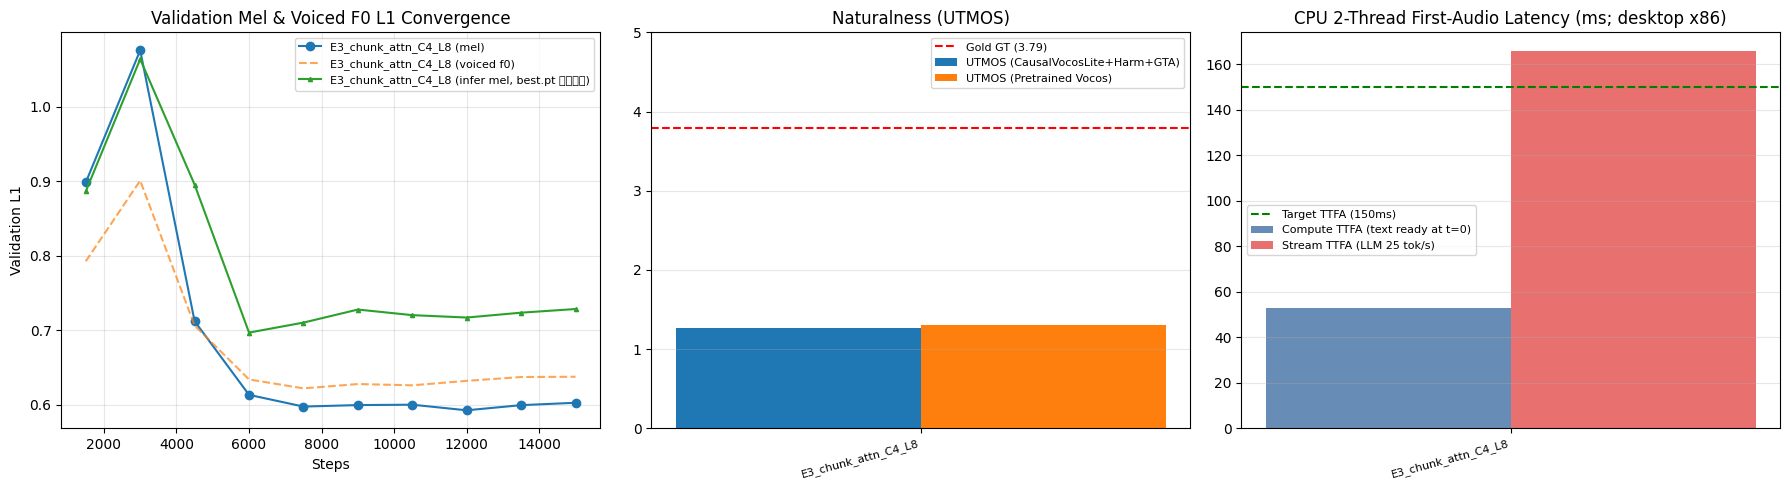

  Candidate_A:


  Candidate_A:


  Candidate_A:


  Candidate_A:


  Candidate_A:


  Candidate_A:


[Saved] 图表与试听质检表已保存至: /content/drive/MyDrive/AetherTTS_Exp/reports/bznsyp_standard_phase1_a6_fL2_vL2


In [12]:
interactive_nb = False
try:
    from IPython import get_ipython
    from IPython.display import Audio, display, HTML
    interactive_nb = get_ipython() is not None
except Exception:
    pass

import matplotlib
if not interactive_nb:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
for exp_name, hist in TRAIN_HISTORIES.items():
    if hist.get("steps"):
        ax.plot(hist["steps"], hist["val_mel"], marker="o", label=f"{exp_name} (mel)")
        if hist.get("val_f0"):
            ax.plot(hist["steps"], hist["val_f0"], linestyle="--", alpha=0.7, label=f"{exp_name} (voiced f0)")
        if hist.get("val_infer_mel"):
            # 真实推理路径 mel L1：best.pt 的选模分量（另有 dur_rel 相加）
            ax.plot(hist["steps"], hist["val_infer_mel"], marker="^", markersize=3, label=f"{exp_name} (infer mel, best.pt)")
ax.set_title("Validation Mel & Voiced F0 L1 Convergence")
ax.set_xlabel("Steps"); ax.set_ylabel("Validation L1"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
x = np.arange(len(LEADERBOARD))
ax.bar(x - 0.18, LEADERBOARD["UTMOS↑"].fillna(0), width=0.36, label="UTMOS (CausalVocosLite+Harm+GTA)")
if LEADERBOARD["UTMOS_PreVocos↑"].notna().any():
    ax.bar(x + 0.18, LEADERBOARD["UTMOS_PreVocos↑"].fillna(0), width=0.36, label="UTMOS (Pretrained Vocos)")
if not np.isnan(GT_UTMOS_MEAN):
    ax.axhline(GT_UTMOS_MEAN, color="red", linestyle="--", label=f"Gold GT ({GT_UTMOS_MEAN:.2f})")
ax.set_xticks(x); ax.set_xticklabels(LEADERBOARD["Model"], rotation=15, ha="right", fontsize=8)
ax.set_title("Naturalness (UTMOS)"); ax.set_ylim(0, 5.0); ax.grid(True, axis="y", alpha=0.3); ax.legend(fontsize=8)

ax = axes[2]
_w = 0.38
ax.bar(x - _w / 2, LEADERBOARD["CPU2T_TTFA_ms↓"], width=_w, color="#4C78A8", alpha=0.85, label="Compute TTFA (text ready at t=0)")
ax.bar(x + _w / 2, LEADERBOARD["Stream_TTFA_ms↓"], width=_w, color="#E45756", alpha=0.85, label=f"Stream TTFA (LLM {CFG['llm_tok_rate']:.0f} tok/s)")
ax.axhline(150.0, color="green", linestyle="--", label="Target TTFA (150ms)")
ax.set_xticks(x); ax.set_xticklabels(LEADERBOARD["Model"], rotation=15, ha="right", fontsize=8)
ax.set_title("CPU 2-Thread First-Audio Latency (ms; desktop x86)"); ax.grid(True, axis="y", alpha=0.3); ax.legend(fontsize=8)

plt.tight_layout()
chart_local = report_local / "comparison_charts.png"
plt.savefig(chart_local, dpi=150)
sync_file_to_storage(chart_local, report_storage / "comparison_charts.png")
if interactive_nb:
    plt.show()
else:
    plt.close(fig)

blind_rows = []
rng_b = random.Random(CFG["seed"] + 99)
model_names = list(TRAINED_MODELS.keys())
preview_utts = [u for u in EVAL_SUITE if not u["is_val"]][:6] or EVAL_SUITE[:6]

for u in preview_utts:
    if interactive_nb:
        display(HTML(f"<h4>[{u['utt_id']}] {u['text']}</h4>"))
    shuffled = list(model_names)
    rng_b.shuffle(shuffled)
    for label_idx, m_name in enumerate(shuffled):
        rec = next(r for r in GENERATED_RECORDS[m_name] if r["utt_id"] == u["utt_id"])
        wav_p = rec["str_wav"] if rec["str_wav"] else rec["off_wav"]
        tag = f"Candidate_{chr(65 + label_idx)}"
        blind_rows.append({"utt_id": u["utt_id"], "text": u["text"], "blind_tag": tag, "true_model": m_name, "wav_path": wav_p, "MOS_or_CMOS": "", "defect_tags": ""})
        if interactive_nb:
            print(f"  {tag}:")
            display(Audio(filename=wav_p, rate=CFG["sample_rate"]))

blind_df = pd.DataFrame(blind_rows)
blind_local = report_local / "blind_ab_listening_sheet.csv"
blind_df.to_csv(blind_local, index=False)
sync_file_to_storage(blind_local, report_storage / "blind_ab_listening_sheet.csv")
save_progress_status("all_complete", {"status": "done", "report_dir": str(report_storage)})
print(f"[Saved] 图表与试听质检表已保存至: {report_storage}")

if IS_COLAB and AUTO_UNASSIGN_COLAB:
    print("[Colab] 全部任务已完成并同步至 Google Drive，10 秒后自动释放 GPU 运行时...")
    time.sleep(10)
    from google.colab import runtime
    runtime.unassign()

## 13. （可选扩展）Apache 2.0 教师离线造数模板（Phase 2 单音色中英混读黄金集）

In [13]:
RUN_TEACHER_SYNTH = False  # Phase 2 造数时改为 True

if RUN_TEACHER_SYNTH:
    OUT_CUSTOM_DIR = STORAGE_ROOT / "datasets" / "custom_bilingual"
    (OUT_CUSTOM_DIR / "wavs").mkdir(parents=True, exist_ok=True)
    print(f"教师造数输出目录已就绪: {OUT_CUSTOM_DIR}")
    print("参考 docs/03_teacher_distillation_pipeline.md：放入合规干声 ref.wav -> 用 Qwen3-TTS / CosyVoice 批量合成 20-25h -> ASR+SIM+UTMOS 四重清洗 -> 设置 DATASET_SOURCE='custom_bilingual' 开训。")
else:
    print("当前跳过教师离线造数。")


当前跳过教师离线造数。
